In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
from torch.utils.data import DataLoader, Subset, random_split
import copy
import numpy as np
import os
import sys
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import json
import random


In [2]:

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']


In [3]:

### CONFIG ###
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# sim settings
FED_ROUNDS = 70        
TOTAL_CLIENTS = 5
CLIENTS_PER_ROUND = 3     
LOCAL_EPOCHS = 3
LOCAL_EPOCHS_FEDDF = 5
SERVER_FUSION_EPOCHS = 5
BATCH_SIZE = 512 
CLIENT_LR = 0.005
SERVER_LR = 0.0001
NUM_WORKERS = 2

# distillation 
TEMP = 1.5
ALPHA = 0.5
BETA = 0.5




seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)


SAVE_DIR = (
    r"C:\Users\hoodo\Desktop\universitas\bachelor\BACHELOR25072026"
    if os.name == "nt"
    else "/mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026"
)

os.makedirs(SAVE_DIR, exist_ok=True)
PATH_BASELINE = os.path.join(SAVE_DIR, 'resnet18_best.pth')
PATH_STUDENT = os.path.join(SAVE_DIR, 'big_student_distilled_best.pth')


In [4]:

######### MODEL DEFINITIONS ########
# models defined in part 1
from torchvision.models.resnet import ResNet, BasicBlock

def get_teacher_model():
    model = resnet18(num_classes=10)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model


class Resnet14(ResNet):
    def __init__(self, num_classes=10):
        super().__init__(BasicBlock,[2, 2, 2, 2], num_classes=num_classes)
        
        # Deleting 4th stage 
        del self.layer4 
        
        self.fc = nn.Linear(256 * BasicBlock.expansion, num_classes)

    def _forward_impl(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        # here I skip layer 4

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


############### HELPERS ###################


def get_model_size_mb(model): #gets real model size 
    param_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    for buffer in model.buffers():
        param_size += buffer.nelement() * buffer.element_size()
    return param_size / 1e6

def get_compressed_size_mb(model): #simulates compressed model size
    total_nonzero = 0
    for name, param in model.named_parameters():
        if 'weight' in name:
            tensor = param.data.cpu()
            nonzero = torch.count_nonzero(tensor).item()
            total_nonzero += nonzero
        else:
            total_nonzero += param.nelement()
            
    return (total_nonzero * 1) / 1e6 




def distillation_loss(student_logits, teacher_logits, T=2.0):
    soft_targets = F.softmax(teacher_logits / T, dim=-1)
    soft_prob = F.log_softmax(student_logits / T, dim=-1)
    return nn.KLDivLoss(reduction='batchmean')(soft_prob, soft_targets) * (T**2)

def evaluate(model, loader, device):
    model.eval()
    correct = 0; total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

def federated_averaging(models):
    w_avg = copy.deepcopy(models[0].state_dict())
    for k in w_avg.keys():
        for i in range(1, len(models)):
            w_avg[k] += models[i].state_dict()[k]
        w_avg[k] = torch.div(w_avg[k], len(models))
    return w_avg

In [5]:
def run_feddf(client_loaders, proxy_loader, test_loader, loader_for_name="iid", pretrained=True):
    torch.cuda.empty_cache()
    print(f"\n Starting FedDF")
    
    global_model = get_teacher_model().to(device)
    if os.path.exists(PATH_BASELINE):
        global_model.load_state_dict(torch.load(PATH_BASELINE, map_location=device, weights_only=True))
    
    client_models = [Resnet14().to(device) for _ in range(TOTAL_CLIENTS)]
    if pretrained:
        if os.path.exists(PATH_STUDENT):
            state_dict = torch.load(PATH_STUDENT, map_location=device, weights_only=True)
            for m in client_models:
                m.load_state_dict(copy.deepcopy(state_dict), strict=False)
    else:
        for m in client_models:
            m.apply(lambda mod: mod.reset_parameters() if hasattr(mod, 'reset_parameters') else None)
            
    history = []
    comm_history = []
    client_acc_history = {i: [] for i in range(TOTAL_CLIENTS)} 
    total_uplink_mb = 0
    highest_acc = 0.0

    model_size = get_model_size_mb(global_model)
    
    pbar=tqdm(range(FED_ROUNDS), desc="Fed Rounds")
    for round_idx in pbar:
        uploaded_models = []
        
        ###client phase
        for client_id in range(TOTAL_CLIENTS):
            student = client_models[client_id]
            student.train()
            optimizer = optim.SGD(student.parameters(), lr=CLIENT_LR, momentum=0.9)
            
            for _ in range(LOCAL_EPOCHS_FEDDF):
                for inputs, labels in client_loaders[client_id]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    s_logits = student(inputs)
                    loss = F.cross_entropy(s_logits, labels)
                    loss.backward()
                    optimizer.step()
                    
            

            # Local model eval
            c_acc = evaluate(student, test_loader, device)
            client_acc_history[client_id].append(c_acc)
            
            # Size calc now simulates INT8 (1 byte per weight)
            total_uplink_mb += model_size
            uploaded_models.append(copy.deepcopy(student))
            
        ###server phase
        global_model.train()
        optimizer_server = optim.SGD(global_model.parameters(), lr=SERVER_LR, momentum=0.9)
        
        for m in uploaded_models: m.eval()
        
        limit_batches = 50
        for _ in range(SERVER_FUSION_EPOCHS):
            for batch_idx, (inputs, _) in enumerate(proxy_loader):
                if batch_idx >= limit_batches: break
                inputs = inputs.to(device)
                with torch.no_grad():
                    ensemble_logits = torch.zeros((inputs.size(0), 10), device=device)
                    for cm in uploaded_models:
                        ensemble_logits += cm(inputs)
                    ensemble_logits /= len(uploaded_models)
                
                server_logits = global_model(inputs)
                loss = distillation_loss(server_logits, ensemble_logits, TEMP)
                optimizer_server.zero_grad()
                loss.backward()
                optimizer_server.step()
                
        acc = evaluate(global_model, test_loader, device)
        history.append(acc)
        comm_history.append(total_uplink_mb)
        
        print(f" Round {round_idx+1}/{FED_ROUNDS}: Acc={acc:.2f}%")
        pbar.set_postfix(acc=f"{acc:.2f}%")
        torch.save(global_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_basic_last_{loader_for_name}.pth'))
        for c_id, s_model in enumerate(client_models):
            torch.save(s_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_basic_student_client{c_id}_last_{loader_for_name}.pth'))
        if acc > highest_acc:
            highest_acc = acc
            torch.save(global_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_basic_best_{loader_for_name}.pth'))
            for c_id, s_model in enumerate(client_models):
                torch.save(s_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_basic_student_client{c_id}_best_{loader_for_name}.pth'))
        del uploaded_models
        torch.cuda.empty_cache()

    histories_to_save = {
        "history": history,
        "comm_history": comm_history,
        "client_acc_history": client_acc_history,
        "total_uplink_mb": total_uplink_mb
    }
    with open(os.path.join(SAVE_DIR, f"feddf_basic_histories_{loader_for_name}.json"), "w") as f:
        json.dump(histories_to_save, f, indent=4)
        
    return history, total_uplink_mb, comm_history, client_acc_history

In [6]:
def run_feddf_bidirect(client_loaders, proxy_loader, test_loader, loader_for_name="iid", pretrained=True):
    torch.cuda.empty_cache()
    print(f"\n Starting bidirectional FedDF")
    
    global_model = get_teacher_model().to(device)
    if os.path.exists(PATH_BASELINE):
        global_model.load_state_dict(torch.load(PATH_BASELINE, map_location=device, weights_only=True))
    
    client_models = [Resnet14().to(device) for _ in range(TOTAL_CLIENTS)]
    if pretrained:
        if os.path.exists(PATH_STUDENT):
            state_dict = torch.load(PATH_STUDENT, map_location=device, weights_only=True)
            for m in client_models:
                m.load_state_dict(copy.deepcopy(state_dict), strict=False)
    else:
        for m in client_models:
             m.apply(lambda mod: mod.reset_parameters() if hasattr(mod, 'reset_parameters') else None)
            
    history = []
    comm_history = []
    client_acc_history = {i: [] for i in range(TOTAL_CLIENTS)} 
    total_uplink_mb = 0
    highest_acc = 0.0

    model_size = get_model_size_mb(global_model)
    
    pbar=tqdm(range(FED_ROUNDS), desc="Fed Rounds")
    for round_idx in pbar:
        uploaded_models = []
        
        ###client phase
        for client_id in range(TOTAL_CLIENTS):
            teacher = global_model
            teacher.eval()
            student = client_models[client_id]
            student.train()
            optimizer = optim.SGD(student.parameters(), lr=CLIENT_LR, momentum=0.9)
            
            for _ in range(LOCAL_EPOCHS_FEDDF):
                for inputs, labels in client_loaders[client_id]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    with torch.no_grad():
                        t_logits = teacher(inputs)
                    s_logits = student(inputs)
                    loss = ALPHA * F.cross_entropy(s_logits, labels) + BETA * distillation_loss(s_logits, t_logits, TEMP)
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
                    

            # Local model eval
            c_acc = evaluate(student, test_loader, device)
            client_acc_history[client_id].append(c_acc)

            total_uplink_mb += model_size
            uploaded_models.append(student)
            
        ###server phase
        global_model.train()
        optimizer_server = optim.SGD(global_model.parameters(), lr=SERVER_LR, momentum=0.9)
        
        for m in uploaded_models: m.eval()
        
        limit_batches = 50
        for _ in range(SERVER_FUSION_EPOCHS):
            for batch_idx, (inputs, _) in enumerate(proxy_loader):
                if batch_idx >= limit_batches: break
                inputs = inputs.to(device)
                with torch.no_grad():
                    ensemble_logits = torch.zeros((inputs.size(0), 10), device=device)
                    for cm in uploaded_models:
                        ensemble_logits += cm(inputs)
                    ensemble_logits /= len(uploaded_models)
                
                server_logits = global_model(inputs)
                loss = distillation_loss(server_logits, ensemble_logits, TEMP)
                optimizer_server.zero_grad()
                loss.backward()
                optimizer_server.step()
                
        acc = evaluate(global_model, test_loader, device)
        history.append(acc)
        comm_history.append(total_uplink_mb)
        
        print(f" Round {round_idx+1}/{FED_ROUNDS}: Acc={acc:.2f}%")
        pbar.set_postfix(acc=f"{acc:.2f}%")
        torch.save(global_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_bidir_last_{loader_for_name}.pth'))
        for c_id, s_model in enumerate(client_models):
            torch.save(s_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_bidir_student_client{c_id}_last_{loader_for_name}.pth'))
            
        if acc > highest_acc:
            highest_acc = acc
            torch.save(global_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_bidir_best_{loader_for_name}.pth'))
            for c_id, s_model in enumerate(client_models):
                torch.save(s_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_bidir_student_client{c_id}_best_{loader_for_name}.pth'))
        del uploaded_models
        torch.cuda.empty_cache()

    histories_to_save = {
        "history": history,
        "comm_history": comm_history,
        "client_acc_history": client_acc_history,
        "total_uplink_mb": total_uplink_mb
    }
    with open(os.path.join(SAVE_DIR, f"feddf_bidir_histories_{loader_for_name}.json"), "w") as f:
        json.dump(histories_to_save, f, indent=4)
        
    return history, total_uplink_mb, comm_history, client_acc_history

In [7]:
## DATA LOADING 
#setting seed
np.random.seed(42)

transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

trainSet = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

proxy_size = len(testSet) // 2
eval_size = len(testSet) - proxy_size
proxy_subset, eval_subset = random_split(testSet, [proxy_size, eval_size], generator=torch.Generator().manual_seed(42))


# Server Loaders
proxy_loader = DataLoader(proxy_subset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True)
test_loader = DataLoader(eval_subset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True)

/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [8]:
## CLIENT DATA LOADING

#goal: number of items per client must differ, and number of items per class per each client too.

def dirichlet(dataset, n_clients, alpha):
    client_ids = [[] for _ in range(n_clients)]
    classes = np.array(dataset.targets)
    n_classes = len(np.unique(classes))

    for c in range(n_classes):

        class_proportions = np.random.dirichlet(np.repeat(alpha, n_clients))

        class_ids = np.where(classes == c)[0]
        np.random.shuffle(class_ids)
        ids_per_client = (class_proportions*len(class_ids)).astype(int)
        ids_per_client[-1] += len(class_ids) - ids_per_client.sum() #to avoid rounding errors

        split_ids = np.split(class_ids, np.cumsum(ids_per_client)[:-1])
        for i in range(n_clients):
            client_ids[i].extend(split_ids[i].tolist())

    return client_ids

# Client Loaders

client_loaders_iid = []
client_loaders_moderatedirichlet = []
client_loaders_strongdirichlet = []
client_ids_iid = list(range(len(trainSet)))
client_ids_moderatedirichlet = dirichlet(trainSet, TOTAL_CLIENTS, alpha=0.5)
client_ids_strongdirichlet = dirichlet(trainSet, TOTAL_CLIENTS, alpha=0.1)

#below is IID split:
split_size = len(trainSet) // TOTAL_CLIENTS
for i in range(TOTAL_CLIENTS):
    subset_indices = client_ids_iid[i*split_size : (i+1)*split_size]
    client_dataset = Subset(trainSet, subset_indices)
    client_loaders_iid.append(DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))


for i in range(TOTAL_CLIENTS):
    client_dataset_moderate = Subset(trainSet, client_ids_moderatedirichlet[i])
    client_loaders_moderatedirichlet.append(DataLoader(client_dataset_moderate, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))
    client_dataset_strong = Subset(trainSet, client_ids_strongdirichlet[i])
    client_loaders_strongdirichlet.append(DataLoader(client_dataset_strong, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))

    

In [9]:

def visualize_split(client_ids, dataset, num_classes=10):
    # Matrix to store counts: rows = clients, cols = classes
    split_matrix = np.zeros((len(client_ids), num_classes))
    targets = np.array(dataset.targets)
    
    # Count how many samples of each class belong to each client
    for i, indices in enumerate(client_ids):
        client_labels = targets[indices]
        unique_classes, counts = np.unique(client_labels, return_counts=True)
        for cls, count in zip(unique_classes, counts):
            split_matrix[i, cls] = count
            
    # Plotting the stacked bar chart
    fig, ax = plt.subplots(figsize=(12, 7))
    clients_x = np.arange(len(client_ids))
    
    bottom = np.zeros(len(client_ids))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes)) # Colors for 10 classes
    
    for cls in range(num_classes):
        ax.bar(clients_x, split_matrix[:, cls], bottom=bottom, 
               label=f'Class {cls}', color=colors[cls], edgecolor='white', linewidth=0.5)
        bottom += split_matrix[:, cls]
        
    ax.set_title(f'Dirichlet Non-IID Data Split (\u03b1=0.5)', fontsize=16, weight='bold')
    ax.set_xlabel('Client ID', fontsize=14)
    ax.set_ylabel('Total Number of Samples', fontsize=14)
    ax.set_xticks(clients_x)
    ax.set_xticklabels([f'Client {i+1}' for i in range(len(client_ids))])
    
    # Put legend outside the plot
    ax.legend(title='CIFAR-10 Classes', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()






###LLLM USED TO ASSIST WITH VISUALIZATION CODE

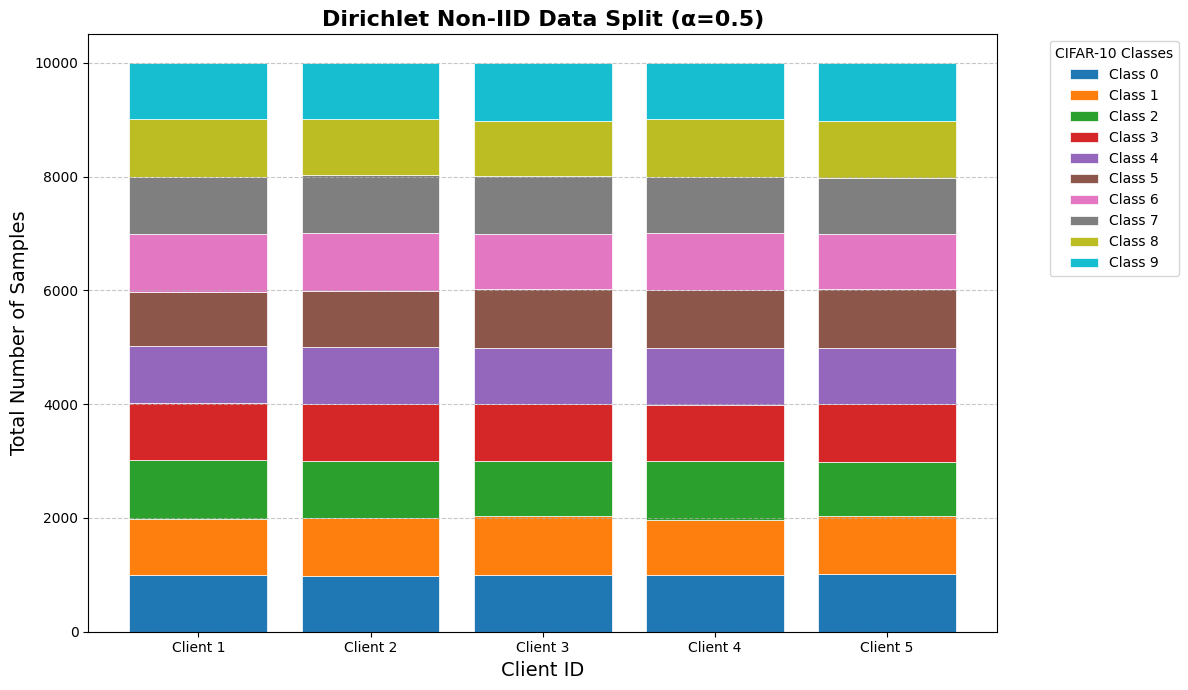

In [10]:
split_size = len(trainSet) // TOTAL_CLIENTS
client_ids_iid_chunks = [client_ids_iid[i*split_size : (i+1)*split_size] for i in range(TOTAL_CLIENTS)]

visualize_split(client_ids_iid_chunks, trainSet)

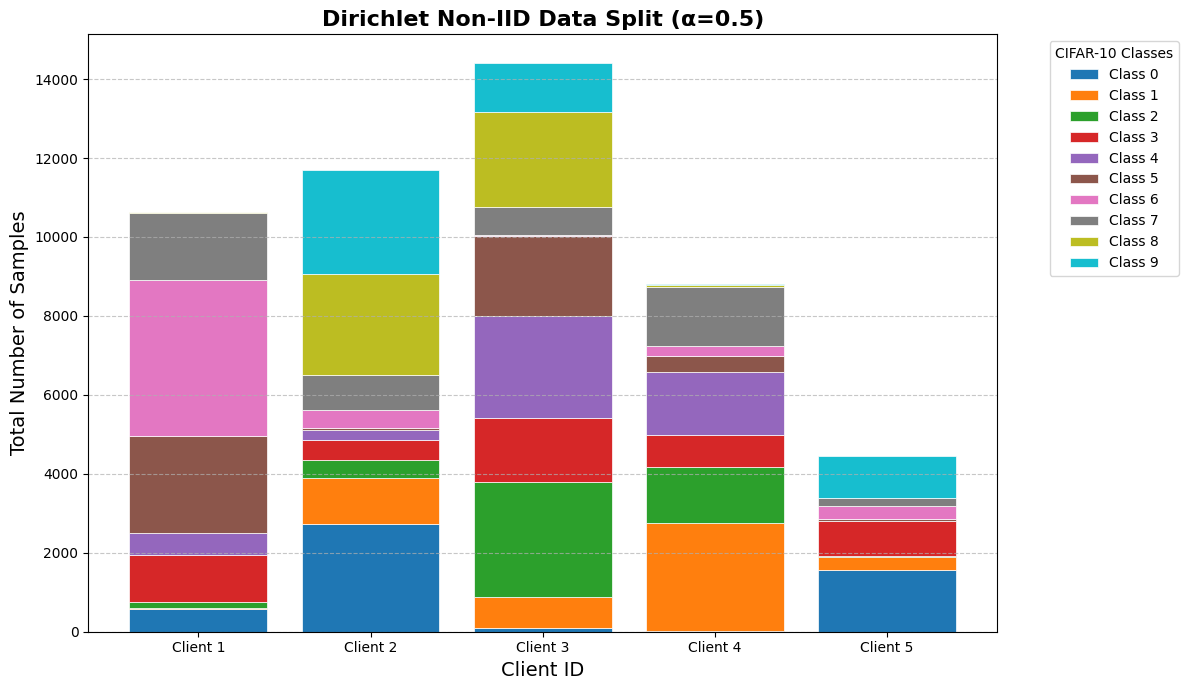

In [11]:
visualize_split(client_ids_moderatedirichlet, trainSet)

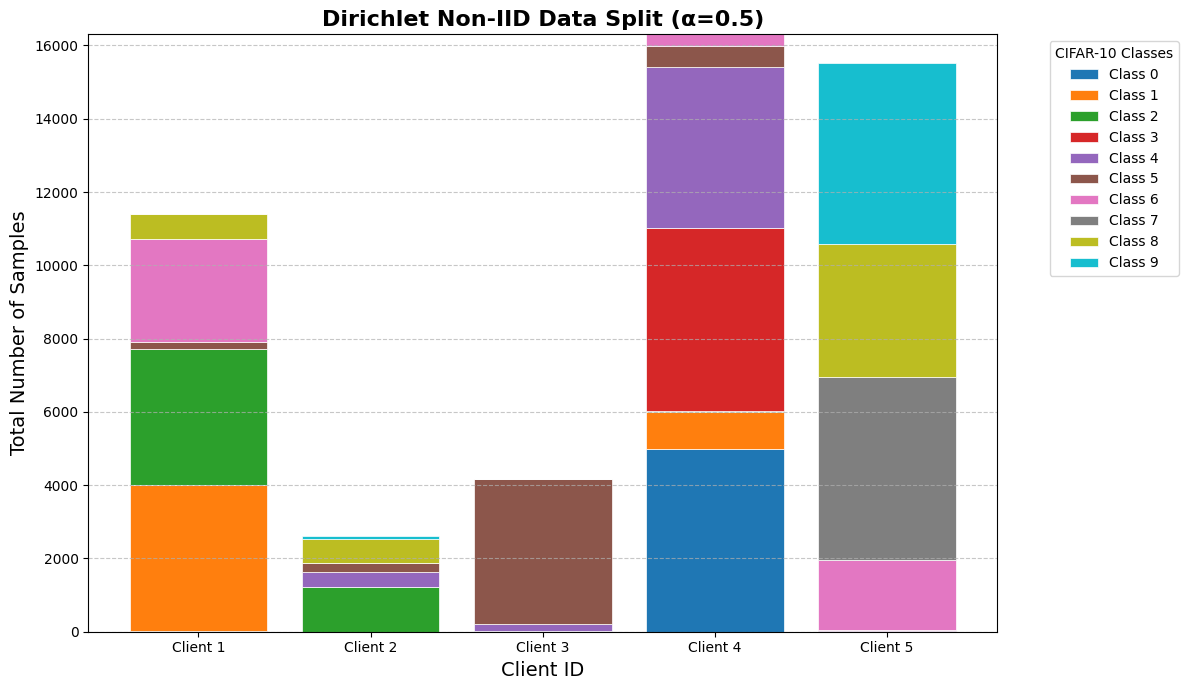

In [12]:
visualize_split(client_ids_strongdirichlet, trainSet)

//////////////
//////////////
/////////////

execution

/////////////
//////////////
///////////////


In [12]:
if __name__ == '__main__':
    feddf_iid_acc, feddf_iid_cost, feddf_iid_comm_hist, client_feddf_iid_acc_hist = run_feddf(client_loaders_iid, proxy_loader, test_loader, loader_for_name="iid", pretrained=False)


 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:15<?, ?it/s, acc=88.54%]

 Round 1/70: Acc=88.54%


Fed Rounds:   1%|▊                                                           | 1/70 [00:31<18:55, 16.46s/it, acc=87.94%]

 Round 2/70: Acc=87.94%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [17:47<00:31, 15.74s/it, acc=87.40%]

 Round 69/70: Acc=87.40%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [18:04<00:15, 15.31s/it, acc=87.94%]

 Round 70/70: Acc=87.94%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [18:04<00:00, 15.50s/it, acc=87.94%]


In [13]:
if __name__ == '__main__':
    feddf_mod_acc, feddf_mod_cost, feddf_mod_comm_hist, client_feddf_mod_acc_hist = run_feddf(client_loaders_moderatedirichlet, proxy_loader, test_loader, loader_for_name="moderatedirichlet", pretrained=False)


 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:14<?, ?it/s, acc=88.28%]

 Round 1/70: Acc=88.28%


Fed Rounds:   1%|▊                                                           | 1/70 [00:30<17:24, 15.14s/it, acc=86.96%]

 Round 2/70: Acc=86.96%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [17:46<00:31, 15.77s/it, acc=83.88%]

 Round 69/70: Acc=83.88%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [18:02<00:15, 15.41s/it, acc=83.54%]

 Round 70/70: Acc=83.54%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [18:03<00:00, 15.47s/it, acc=83.54%]


In [14]:
if __name__ == '__main__':
    feddf_strong_acc, feddf_strong_cost, feddf_strong_comm_hist, client_feddf_strong_acc_hist = run_feddf(client_loaders_strongdirichlet, proxy_loader, test_loader, loader_for_name="strongdirichlet", pretrained=False)


 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:14<?, ?it/s, acc=88.30%]

 Round 1/70: Acc=88.30%


Fed Rounds:   1%|▊                                                           | 1/70 [00:31<17:44, 15.43s/it, acc=87.60%]

 Round 2/70: Acc=87.60%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [17:44<00:30, 15.31s/it, acc=60.82%]

 Round 69/70: Acc=60.82%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [17:59<00:15, 15.77s/it, acc=60.32%]

 Round 70/70: Acc=60.32%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [18:00<00:00, 15.43s/it, acc=60.32%]


In [15]:
if __name__ == '__main__':
    bifeddf_iid_acc, bifeddf_iid_cost, bifeddf_iid_comm_hist, client_bifeddf_iid_acc_hist = run_feddf_bidirect(client_loaders_iid, proxy_loader, test_loader, loader_for_name="iid", pretrained=False)


 Starting bidirectional FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:20<?, ?it/s, acc=88.30%]

 Round 1/70: Acc=88.30%


Fed Rounds:   1%|▊                                                           | 1/70 [00:44<24:47, 21.56s/it, acc=87.64%]

 Round 2/70: Acc=87.64%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [24:56<00:43, 21.54s/it, acc=79.60%]

 Round 69/70: Acc=79.60%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [25:20<00:21, 21.43s/it, acc=80.34%]

 Round 70/70: Acc=80.34%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [25:20<00:00, 21.72s/it, acc=80.34%]


In [16]:
if __name__ == '__main__':
    bifeddf_mod_acc, bifeddf_mod_cost, bifeddf_mod_comm_hist, client_bifeddf_mod_acc_hist = run_feddf_bidirect(client_loaders_moderatedirichlet, proxy_loader, test_loader, loader_for_name="moderatedirichlet", pretrained=False)


 Starting bidirectional FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:20<?, ?it/s, acc=88.36%]

 Round 1/70: Acc=88.36%


Fed Rounds:   1%|▊                                                           | 1/70 [00:42<24:46, 21.54s/it, acc=87.36%]

 Round 2/70: Acc=87.36%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [24:57<00:43, 21.73s/it, acc=51.60%]

 Round 69/70: Acc=51.60%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [25:18<00:21, 21.55s/it, acc=51.76%]

 Round 70/70: Acc=51.76%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [25:19<00:00, 21.70s/it, acc=51.76%]


In [17]:
if __name__ == '__main__':
    bifeddf_strong_acc, bifeddf_strong_cost, bifeddf_strong_comm_hist, client_bifeddf_strong_acc_hist = run_feddf_bidirect(client_loaders_strongdirichlet, proxy_loader, test_loader, loader_for_name="strongdirichlet", pretrained=False)


 Starting bidirectional FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:22<?, ?it/s, acc=88.60%]

 Round 1/70: Acc=88.60%


Fed Rounds:   1%|▊                                                           | 1/70 [00:44<27:16, 23.71s/it, acc=87.06%]

 Round 2/70: Acc=87.06%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [25:06<00:43, 21.65s/it, acc=24.52%]

 Round 69/70: Acc=24.52%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [25:30<00:21, 21.56s/it, acc=25.16%]

 Round 70/70: Acc=25.16%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [25:30<00:00, 21.87s/it, acc=25.16%]


In [51]:
def load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="iid", n_clients=5):

    global_model = get_teacher_model().to(device)
    global_path = os.path.join(SAVE_DIR, f'{run_prefix}_best_{loader_name}.pth')
    if os.path.exists(global_path):
        global_model.load_state_dict(torch.load(global_path, map_location=device, weights_only=True))
    else:
        print(f"no global model at {global_path}")

    # clients are Resnet14, NOT teacher
    client_models = [Resnet14().to(device) for _ in range(n_clients)]
    for c_id in range(n_clients):
        client_path = os.path.join(
            SAVE_DIR, f'{run_prefix}_student_client{c_id}_best_{loader_name}.pth'
        )
        if os.path.exists(client_path):
            client_models[c_id].load_state_dict(
                torch.load(client_path, map_location=device, weights_only=True)
            )
        else:
            print(f"no client {c_id} model at {client_path}")

    history, comm_history, client_acc_history = [], [], {}
    history_path = os.path.join(SAVE_DIR, f"{run_prefix}_histories_{loader_name}.json")

    if os.path.exists(history_path):
        with open(history_path, "r") as f:
            data = json.load(f)
            history = data.get("history", [])
            comm_history = data.get("comm_history", [])
            raw_client_acc = data.get("client_acc_history", {})
            client_acc_history = {int(k): v for k, v in raw_client_acc.items()}
        print("Models and histories loaded successfully.")
    else:
        print(f"no history found at {history_path}")

    return global_model, client_models, history, comm_history, client_acc_history

In [52]:

feddf_iid_model, clients_iid_models, feddf_iid_acc, feddf_iid_comm_hist, client_feddf_iid_acc_hist = load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="iid")
feddf_mod_model, clients_mod_models, feddf_mod_acc, feddf_mod_comm_hist, client_feddf_mod_acc_hist = load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="moderatedirichlet")
feddf_strong_model, clients_strong_models, feddf_strong_acc, feddf_strong_comm_hist, client_feddf_strong_acc_hist = load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="strongdirichlet")
bifeddf_iid_model, clients_bidir_iid_models, bifeddf_iid_acc, bifeddf_iid_comm_hist, client_bifeddf_iid_acc_hist = load_saved_models_and_histories(run_prefix="feddf_bidir", loader_name="iid")
bifeddf_mod_model, clients_bidir_mod_models, bifeddf_mod_acc, bifeddf_mod_comm_hist, client_bifeddf_mod_acc_hist = load_saved_models_and_histories(run_prefix="feddf_bidir", loader_name="moderatedirichlet")
bifeddf_strong_model, clients_bidir_strong_models, bifeddf_strong_acc, bifeddf_strong_comm_hist, client_bifeddf_strong_acc_hist = load_saved_models_and_histories(run_prefix="feddf_bidir", loader_name="strongdirichlet")

Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.


In [15]:
def avg_client_acc(client_hist):
    if not client_hist:
        return float("nan")
    arr = np.array([client_hist[k] for k in sorted(client_hist, key=lambda k: int(k))], dtype=float)
    return arr[:, -1].mean()

In [16]:
print(f"{'Approach':<30} | {'Server Acc':<12} | {'Avg Client Acc':<15}")
print("-" * 65)
print(f"{'FedDF IID':<30} | {feddf_iid_acc[-1]:<12.2f}% | {avg_client_acc(client_feddf_iid_acc_hist):<15.2f}%")
print(f"{'FedDF Mod Dirichlet':<30} | {feddf_mod_acc[-1]:<12.2f}% | {avg_client_acc(client_feddf_mod_acc_hist):<15.2f}%")
print(f"{'FedDF Strong Dirichlet':<30} | {feddf_strong_acc[-1]:<12.2f}% | {avg_client_acc(client_feddf_strong_acc_hist):<15.2f}%")
print(f"{'BiFedDF IID':<30} | {bifeddf_iid_acc[-1]:<12.2f}% | {avg_client_acc(client_bifeddf_iid_acc_hist):<15.2f}%")
print(f"{'BiFedDF Mod Dirichlet':<30} | {bifeddf_mod_acc[-1]:<12.2f}% | {avg_client_acc(client_bifeddf_mod_acc_hist):<15.2f}%")
print(f"{'BiFedDF Strong Dirichlet':<30} | {bifeddf_strong_acc[-1]:<12.2f}% | {avg_client_acc(client_bifeddf_strong_acc_hist):<15.2f}%")

Approach                       | Server Acc   | Avg Client Acc 
-----------------------------------------------------------------
FedDF IID                      | 87.94       % | 69.30          %
FedDF Mod Dirichlet            | 83.54       % | 53.59          %
FedDF Strong Dirichlet         | 60.32       % | 33.69          %
BiFedDF IID                    | 80.34       % | 72.34          %
BiFedDF Mod Dirichlet          | 51.76       % | 54.06          %
BiFedDF Strong Dirichlet       | 25.16       % | 33.60          %


In [17]:
print("\n" + "="*40)
print("FINAL COMPARISON REPORT")
print("="*40)
print(f"{'Approach':<30} | {'Server Acc':<12} | {'Avg Client Acc':<15}")
print("-" * 65)
print(f"{'FedDF IID':<30} | {feddf_iid_acc[-1]:<12.2f}% | {avg_client_acc(client_feddf_iid_acc_hist):<15.2f}%")
print(f"{'FedDF Mod Dirichlet':<30} | {feddf_mod_acc[-1]:<12.2f}% | {avg_client_acc(client_feddf_mod_acc_hist):<15.2f}%")
print(f"{'FedDF Strong Dirichlet':<30} | {feddf_strong_acc[-1]:<12.2f}% | {avg_client_acc(client_feddf_strong_acc_hist):<15.2f}%")
print(f"{'BiFedDF IID':<30} | {bifeddf_iid_acc[-1]:<12.2f}% | {avg_client_acc(client_bifeddf_iid_acc_hist):<15.2f}%")
print(f"{'BiFedDF Mod Dirichlet':<30} | {bifeddf_mod_acc[-1]:<12.2f}% | {avg_client_acc(client_bifeddf_mod_acc_hist):<15.2f}%")
print(f"{'BiFedDF Strong Dirichlet':<30} | {bifeddf_strong_acc[-1]:<12.2f}% | {avg_client_acc(client_bifeddf_strong_acc_hist):<15.2f}%")



print("="*40)
    
# Save
df = pd.DataFrame({
    'Round': range(1, FED_ROUNDS + 1),
    'FedDF_iid_Acc': feddf_iid_acc,
    'FedDF_ModDir_Acc': feddf_mod_acc,
    'FedDF_StrongDir_Acc': feddf_strong_acc,
    'BiFedDF_iid_Acc': bifeddf_iid_acc,
    'BiFedDF_ModDir_Acc': bifeddf_mod_acc,
    'BiFedDF_StrongDir_Acc': bifeddf_strong_acc,

})
df.to_csv("stage3_comparison_results.csv", index=False)
print("Results saved to stage3_comparison_results.csv")


FINAL COMPARISON REPORT
Approach                       | Server Acc   | Avg Client Acc 
-----------------------------------------------------------------
FedDF IID                      | 87.94       % | 69.30          %
FedDF Mod Dirichlet            | 83.54       % | 53.59          %
FedDF Strong Dirichlet         | 60.32       % | 33.69          %
BiFedDF IID                    | 80.34       % | 72.34          %
BiFedDF Mod Dirichlet          | 51.76       % | 54.06          %
BiFedDF Strong Dirichlet       | 25.16       % | 33.60          %
Results saved to stage3_comparison_results.csv


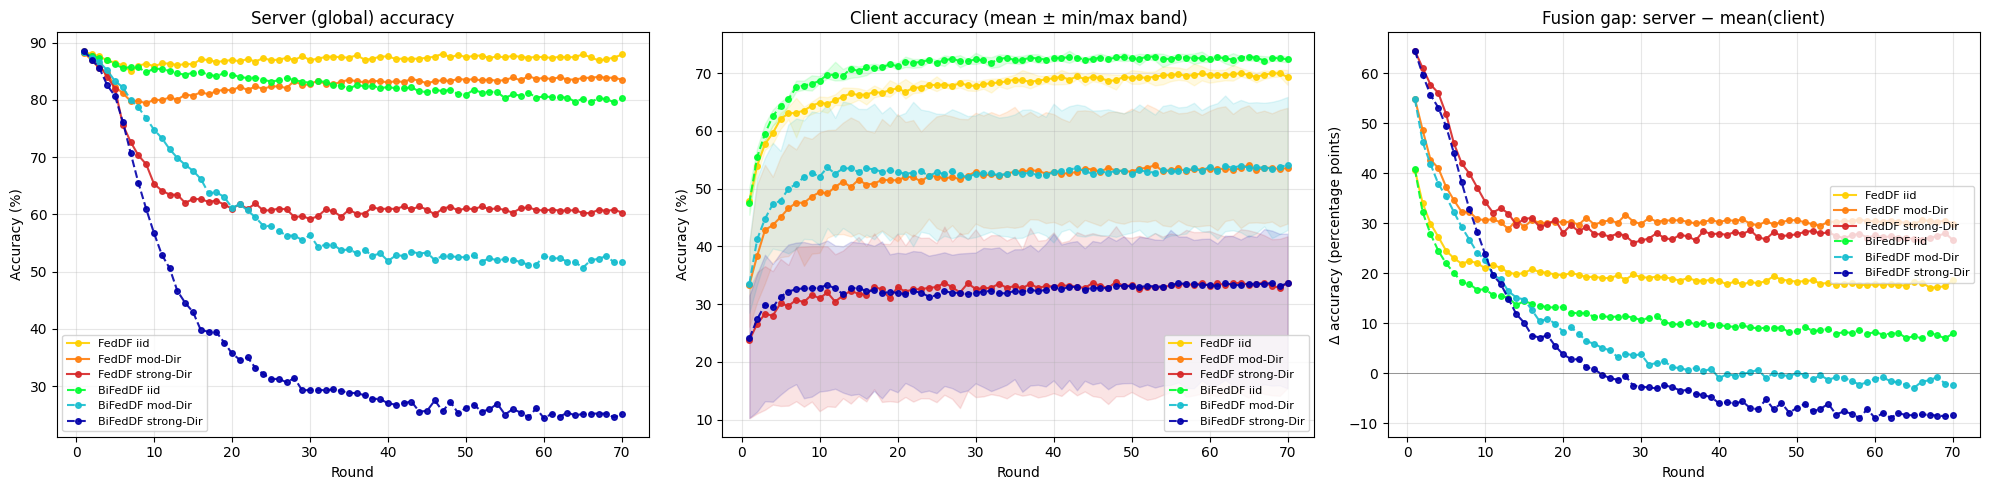

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# (label, server_history, client_history_dict, color, linestyle)
runs = [
    ("FedDF iid",         feddf_iid_acc,      client_feddf_iid_acc_hist,    "#FFD000",   "-"),
    ("FedDF mod-Dir",     feddf_mod_acc,      client_feddf_mod_acc_hist,    "tab:orange", "-"),
    ("FedDF strong-Dir",  feddf_strong_acc,   client_feddf_strong_acc_hist, "tab:red",    "-"),
    ("BiFedDF iid",        bifeddf_iid_acc,    client_bifeddf_iid_acc_hist,    "#00FE31",   "--"),
    ("BiFedDF mod-Dir",    bifeddf_mod_acc,    client_bifeddf_mod_acc_hist,    "tab:cyan", "--"),
    ("BiFedDF strong-Dir", bifeddf_strong_acc, client_bifeddf_strong_acc_hist, "#0200AA",    "--"),
]

def _client_matrix(client_hist):
    # robust to int or str keys (json reload returns str keys)
    keys = sorted(client_hist.keys(), key=lambda k: int(k))
    return np.array([client_hist[k] for k in keys], dtype=float)  # (n_clients, n_rounds)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

# 1) Server (global) accuracy across rounds
for name, server_hist, client_hist, color, ls in runs:
    if not server_hist:
        continue
    rounds = np.arange(1, len(server_hist) + 1)
    ax1.plot(rounds, server_hist, label=name, color=color, linestyle=ls,
             marker='o', markersize=4, alpha=0.9)
ax1.set_title("Server (global) accuracy")
ax1.set_xlabel("Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower left", fontsize=8)

# 2) Client accuracy: mean line + min/max band
for name, server_hist, client_hist, color, ls in runs:
    if not client_hist:
        continue
    arr = _client_matrix(client_hist)
    if arr.size == 0:
        continue
    rounds = np.arange(1, arr.shape[1] + 1)
    mean_acc = arr.mean(axis=0)
    min_acc  = arr.min(axis=0)
    max_acc  = arr.max(axis=0)
    ax2.plot(rounds, mean_acc, label=name, color=color, linestyle=ls,
             marker='o', markersize=4, alpha=0.9)
    ax2.fill_between(rounds, min_acc, max_acc, color=color, alpha=0.12)
ax2.set_title("Client accuracy (mean ± min/max band)")
ax2.set_xlabel("Round")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower right", fontsize=8)

# 3) Fusion gap: server - mean(client)
for name, server_hist, client_hist, color, ls in runs:
    if not server_hist or not client_hist:
        continue
    arr = _client_matrix(client_hist)
    n = min(len(server_hist), arr.shape[1])
    rounds = np.arange(1, n + 1)
    gap = np.asarray(server_hist[:n]) - arr[:, :n].mean(axis=0)
    ax3.plot(rounds, gap, label=name, color=color, linestyle=ls,
             marker='o', markersize=4, alpha=0.9)
ax3.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax3.set_title("Fusion gap: server − mean(client)")
ax3.set_xlabel("Round")
ax3.set_ylabel("Δ accuracy (percentage points)")
ax3.grid(True, alpha=0.3)
ax3.legend(loc="center right", fontsize=8)

plt.tight_layout()
plt.show()

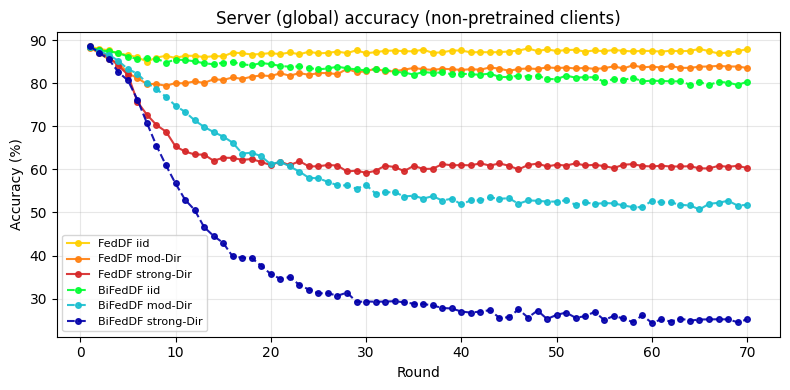

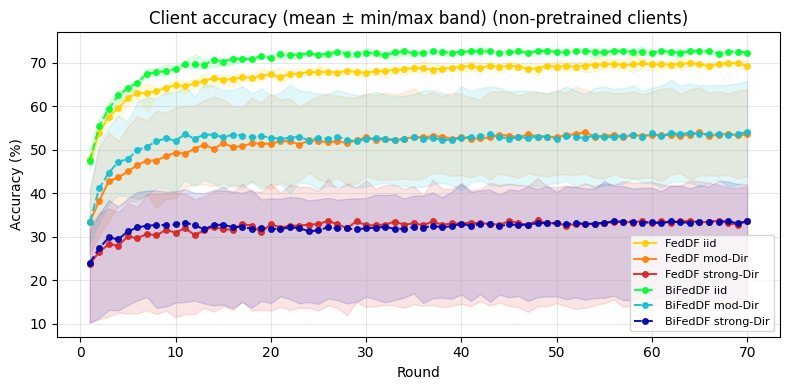

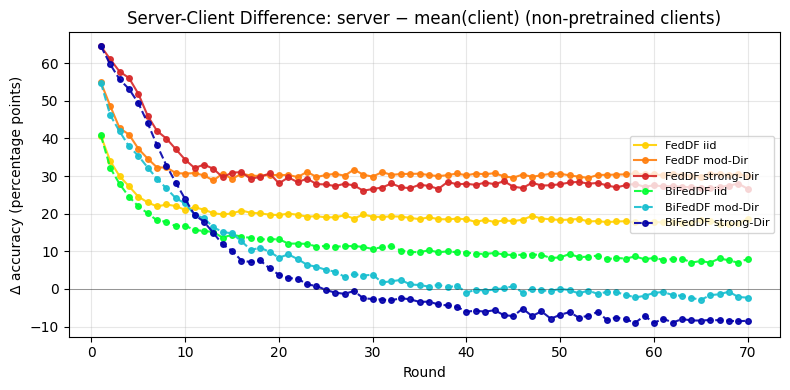

In [56]:
import numpy as np
import matplotlib.pyplot as plt

runs = [
    ("FedDF iid",         feddf_iid_acc,      client_feddf_iid_acc_hist,    "#FFD000",   "-"),
    ("FedDF mod-Dir",     feddf_mod_acc,      client_feddf_mod_acc_hist,    "tab:orange", "-"),
    ("FedDF strong-Dir",  feddf_strong_acc,   client_feddf_strong_acc_hist, "tab:red",    "-"),
    ("BiFedDF iid",        bifeddf_iid_acc,    client_bifeddf_iid_acc_hist,    "#00FE31",   "--"),
    ("BiFedDF mod-Dir",    bifeddf_mod_acc,    client_bifeddf_mod_acc_hist,    "tab:cyan", "--"),
    ("BiFedDF strong-Dir", bifeddf_strong_acc, client_bifeddf_strong_acc_hist, "#0200AA",    "--"),
]

def _client_matrix(client_hist):
    keys = sorted(client_hist.keys(), key=lambda k: int(k))
    return np.array([client_hist[k] for k in keys], dtype=float)

# 1) Server accuracy
fig1, ax1 = plt.subplots(figsize=(8, 4))
for name, server_hist, client_hist, color, ls in runs:
    if not server_hist:
        continue
    rounds = np.arange(1, len(server_hist) + 1)
    ax1.plot(
        rounds, server_hist, label=name, color=color, linestyle=ls,
        marker='o', markersize=4, alpha=0.9
    )
ax1.set_title("Server (global) accuracy (non-pretrained clients)")
ax1.set_xlabel("Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

# 2) Client accuracy
fig2, ax2 = plt.subplots(figsize=(8, 4))
for name, server_hist, client_hist, color, ls in runs:
    if not client_hist:
        continue
    arr = _client_matrix(client_hist)
    if arr.size == 0:
        continue
    rounds = np.arange(1, arr.shape[1] + 1)
    mean_acc = arr.mean(axis=0)
    min_acc = arr.min(axis=0)
    max_acc = arr.max(axis=0)
    ax2.plot(
        rounds, mean_acc, label=name, color=color, linestyle=ls,
        marker='o', markersize=4, alpha=0.9
    )
    ax2.fill_between(rounds, min_acc, max_acc, color=color, alpha=0.12)
ax2.set_title("Client accuracy (mean ± min/max band) (non-pretrained clients)")
ax2.set_xlabel("Round")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# 3) Fusion gap
fig3, ax3 = plt.subplots(figsize=(8, 4))
for name, server_hist, client_hist, color, ls in runs:
    if not server_hist or not client_hist:
        continue
    arr = _client_matrix(client_hist)
    n = min(len(server_hist), arr.shape[1])
    rounds = np.arange(1, n + 1)
    gap = np.asarray(server_hist[:n]) - arr[:, :n].mean(axis=0)
    ax3.plot(
        rounds, gap, label=name, color=color, linestyle=ls,
        marker='o', markersize=4, alpha=0.9
    )
ax3.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax3.set_title("Server-Client Difference: server − mean(client) (non-pretrained clients)")
ax3.set_xlabel("Round")
ax3.set_ylabel("Δ accuracy (percentage points)")
ax3.grid(True, alpha=0.3)
ax3.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()

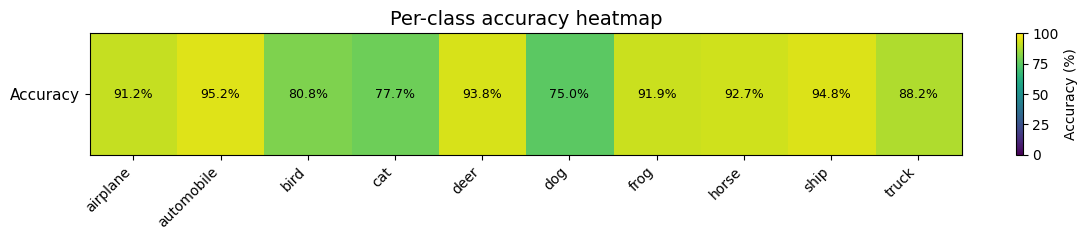

Per-class accuracy: [91.18852459 95.16806723 80.78358209 77.734375   93.84288747 74.95107632
 91.91919192 92.71255061 94.77756286 88.2       ]


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torchvision

def plot_per_class_accuracy_heatmap(model, loader,  name="Per-class accuracy heatmap", device=device, cmap='viridis'):
    class_names = [
            "airplane", "automobile", "bird", "cat", "deer",
            "dog", "frog", "horse", "ship", "truck"
        ]

    n_classes = len(class_names)
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    model.eval()
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    acc = 100.0 * correct / np.maximum(total, 1)

    fig, ax = plt.subplots(figsize=(12, 2.5))
    im = ax.imshow(acc[np.newaxis, :], cmap=cmap, aspect='auto', vmin=0, vmax=100)

    ax.set_xticks(np.arange(n_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticks([0])
    ax.set_yticklabels(['Accuracy'], fontsize=11)

    for i, value in enumerate(acc):
        text_color = 'white' if value < 50 else 'black'
        ax.text(i, 0, f'{value:.1f}%', ha='center', va='center', color=text_color, fontsize=9)

    fig.colorbar(im, ax=ax, orientation='vertical', label='Accuracy (%)')
    ax.set_title(name, fontsize=14)
    plt.tight_layout()
    plt.show()

    return acc


per_class_acc = plot_per_class_accuracy_heatmap(feddf_iid_model, test_loader)
print("Per-class accuracy:", per_class_acc)

FedDF IID


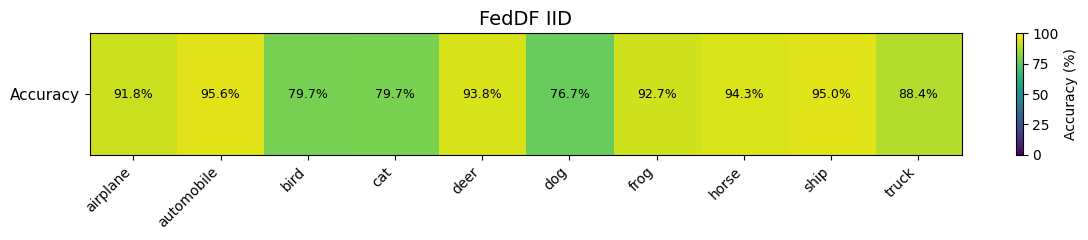

FedDF Mod Dirichlet


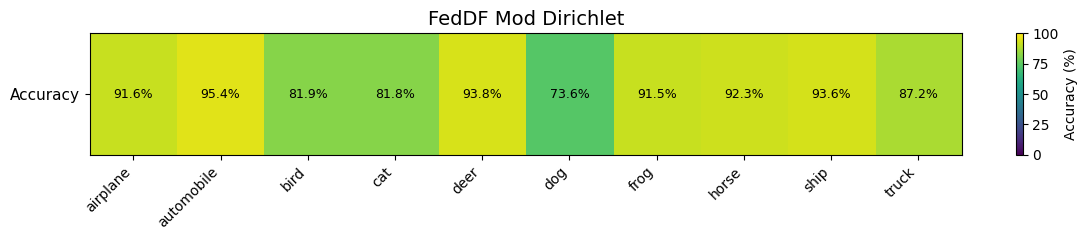

FedDF Strong Dirichlet


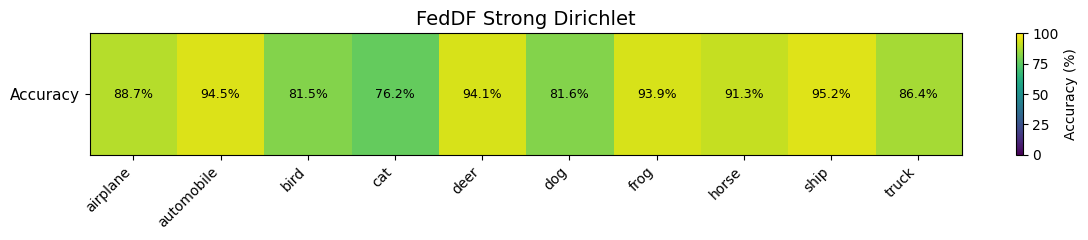

BiFedDF IID


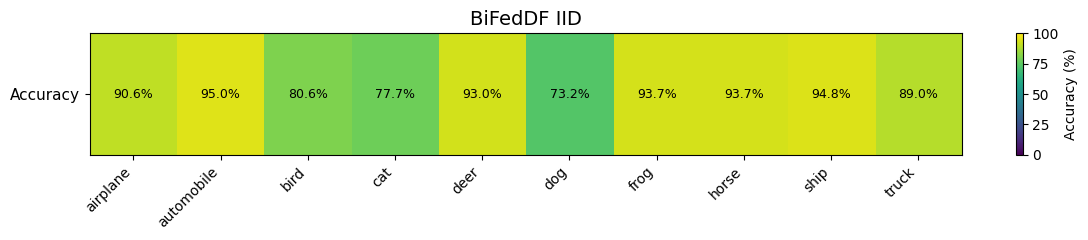

BiFedDF Mod Dirichlet


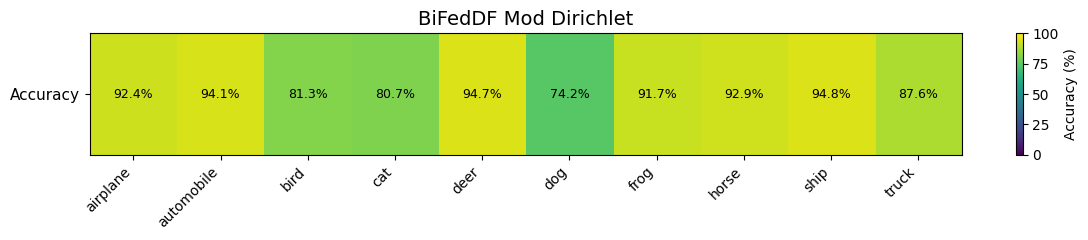

BiFedDF Strong Dirichlet


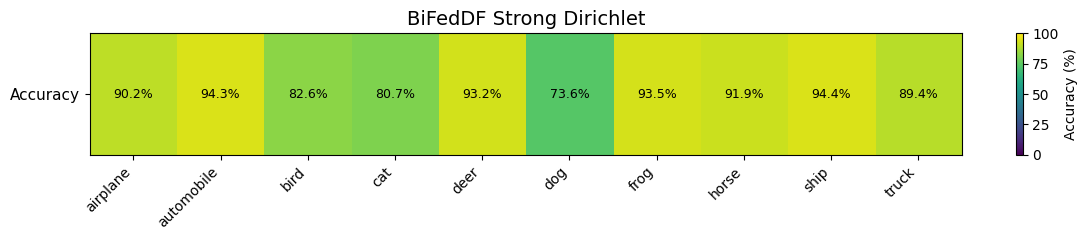

In [21]:
models = [
    ("FedDF IID", feddf_iid_model),
    ("FedDF Mod Dirichlet", feddf_mod_model),
    ("FedDF Strong Dirichlet", feddf_strong_model),
    ("BiFedDF IID", bifeddf_iid_model),
    ("BiFedDF Mod Dirichlet", bifeddf_mod_model),
    ("BiFedDF Strong Dirichlet", bifeddf_strong_model),
]

for name, model in models:
    print(name)
    plot_per_class_accuracy_heatmap(model, test_loader, name)

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_server_per_class_accuracy_group.png


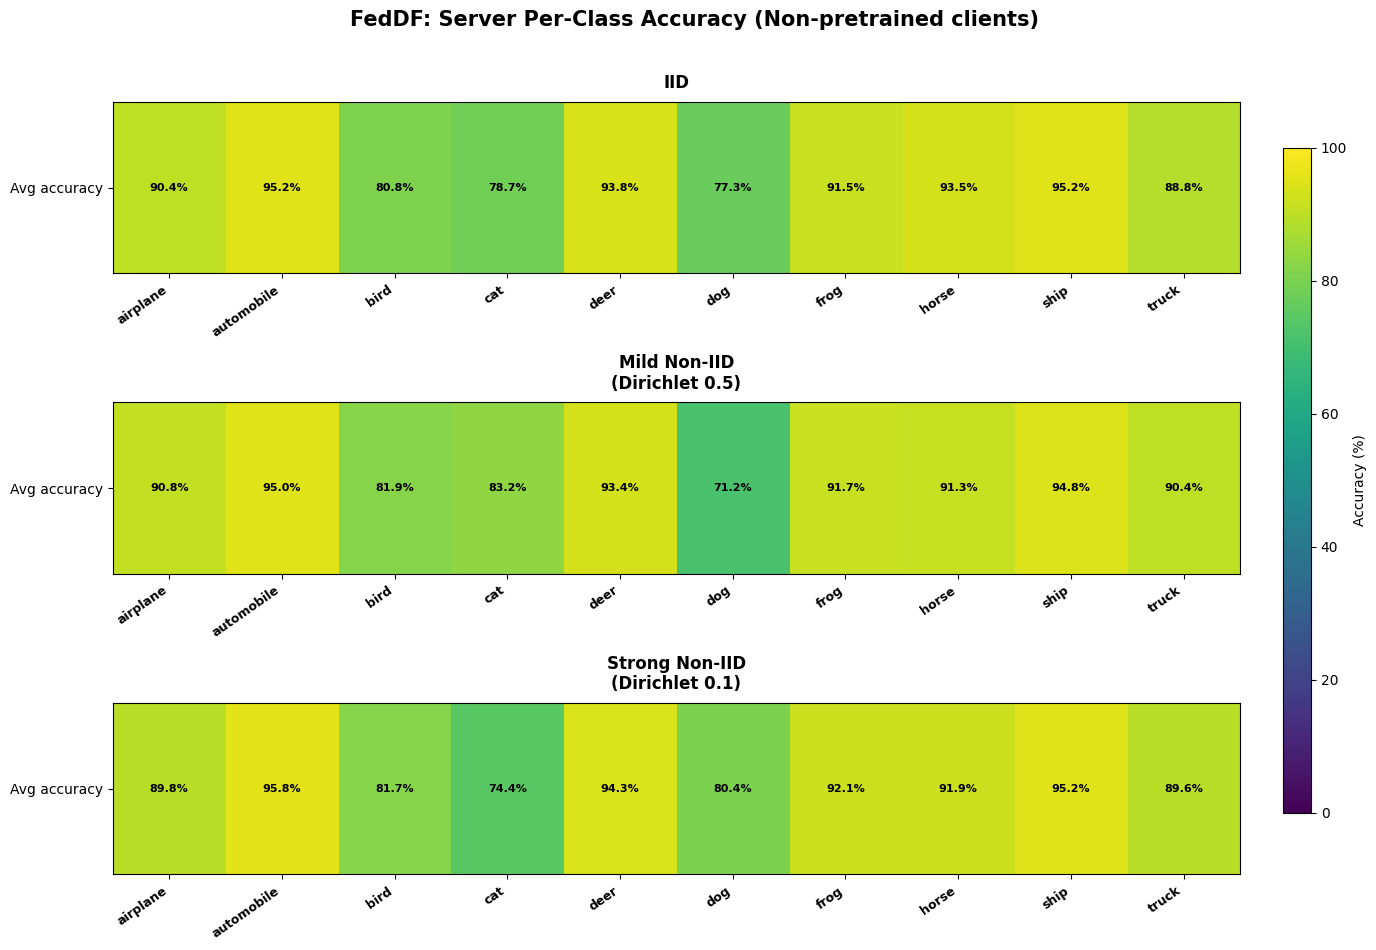

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_client_per_class_accuracy_group.png


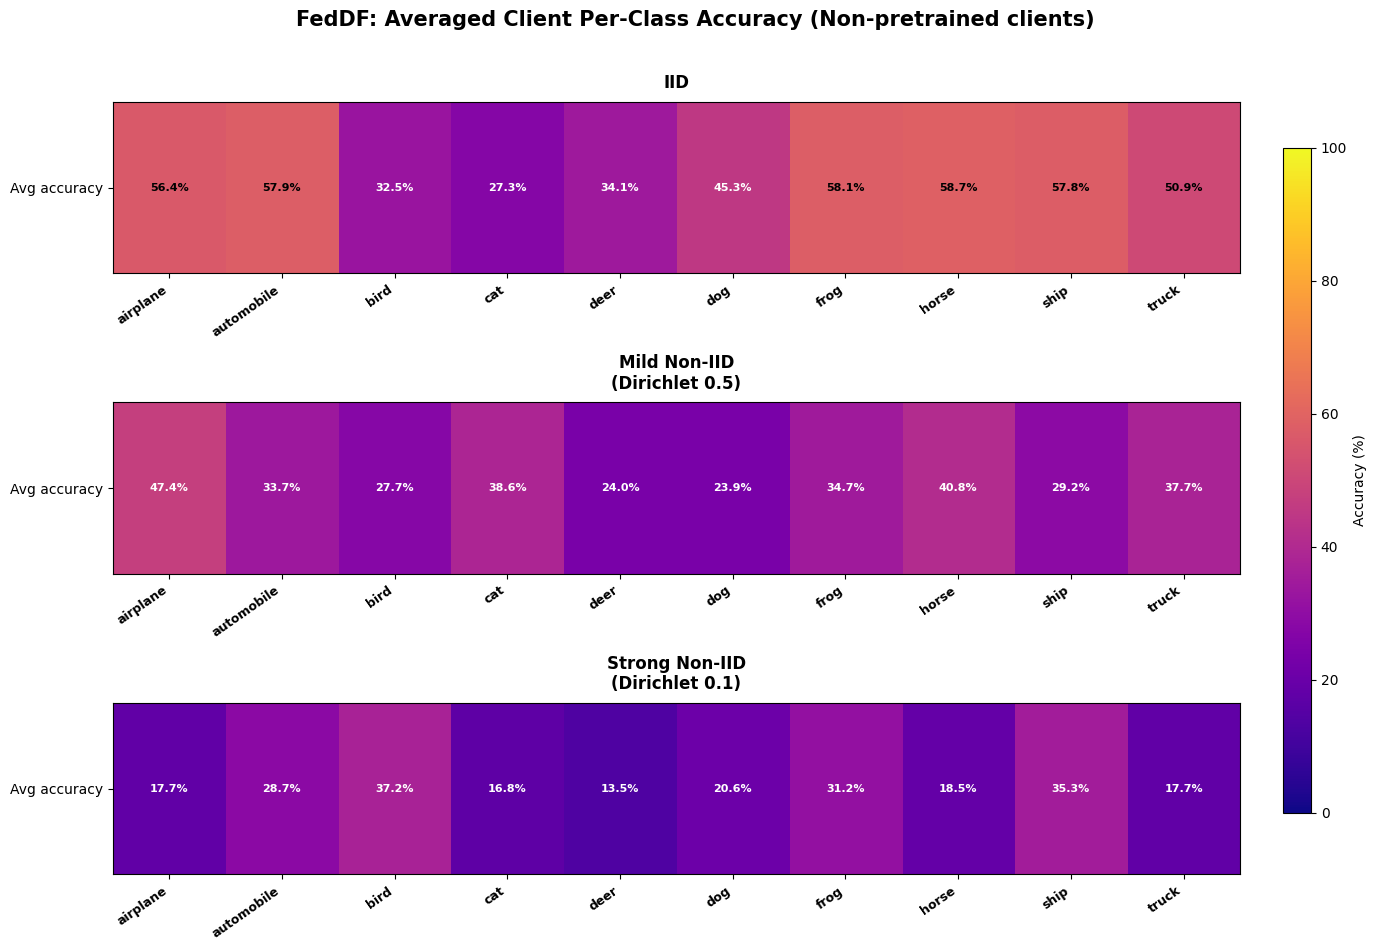

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_server_per_class_accuracy_group.png


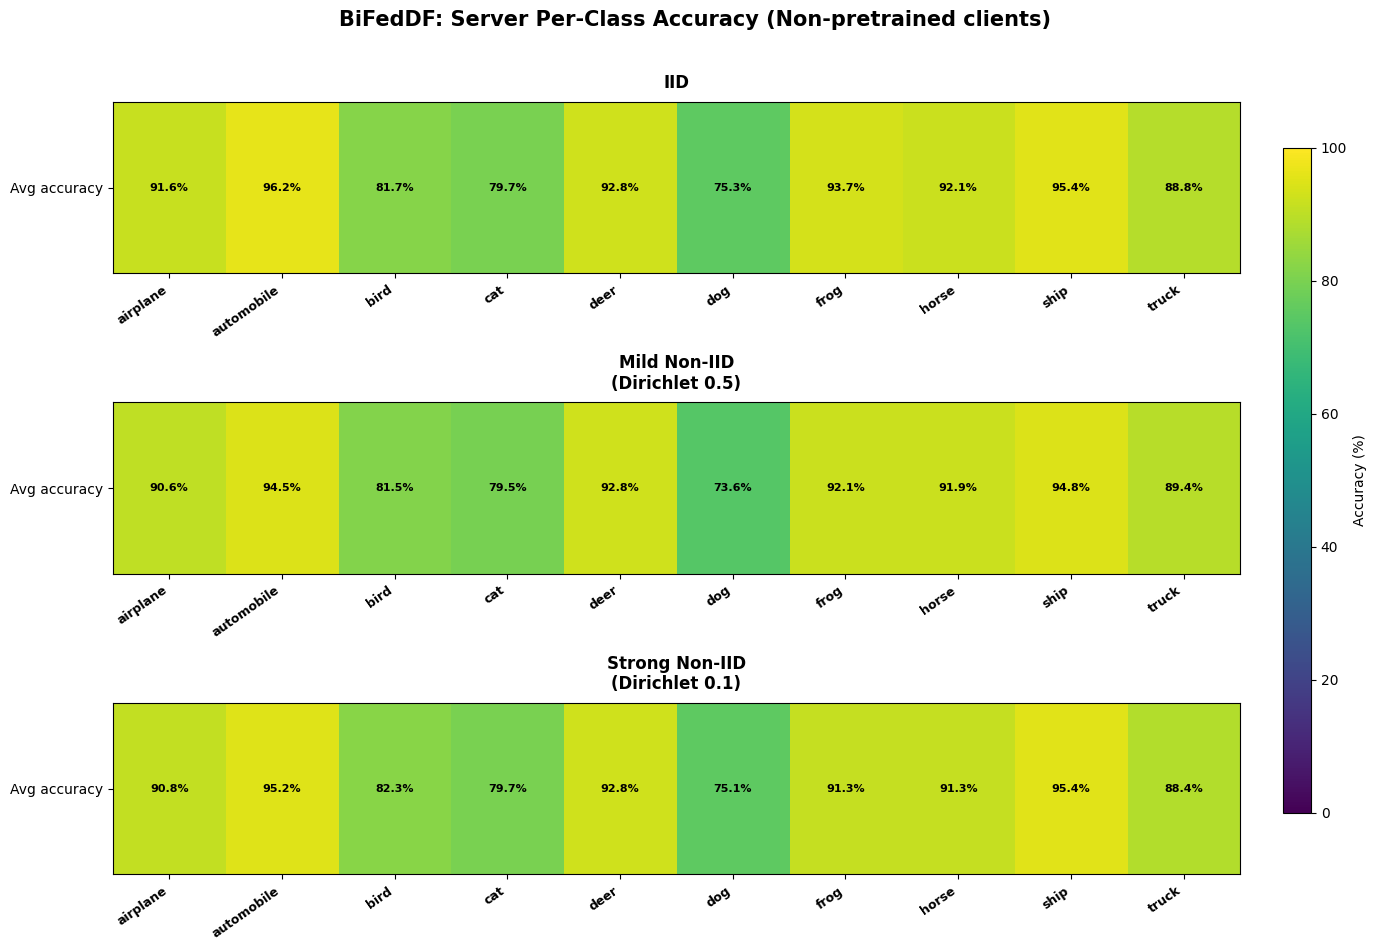

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_client_per_class_accuracy_group.png


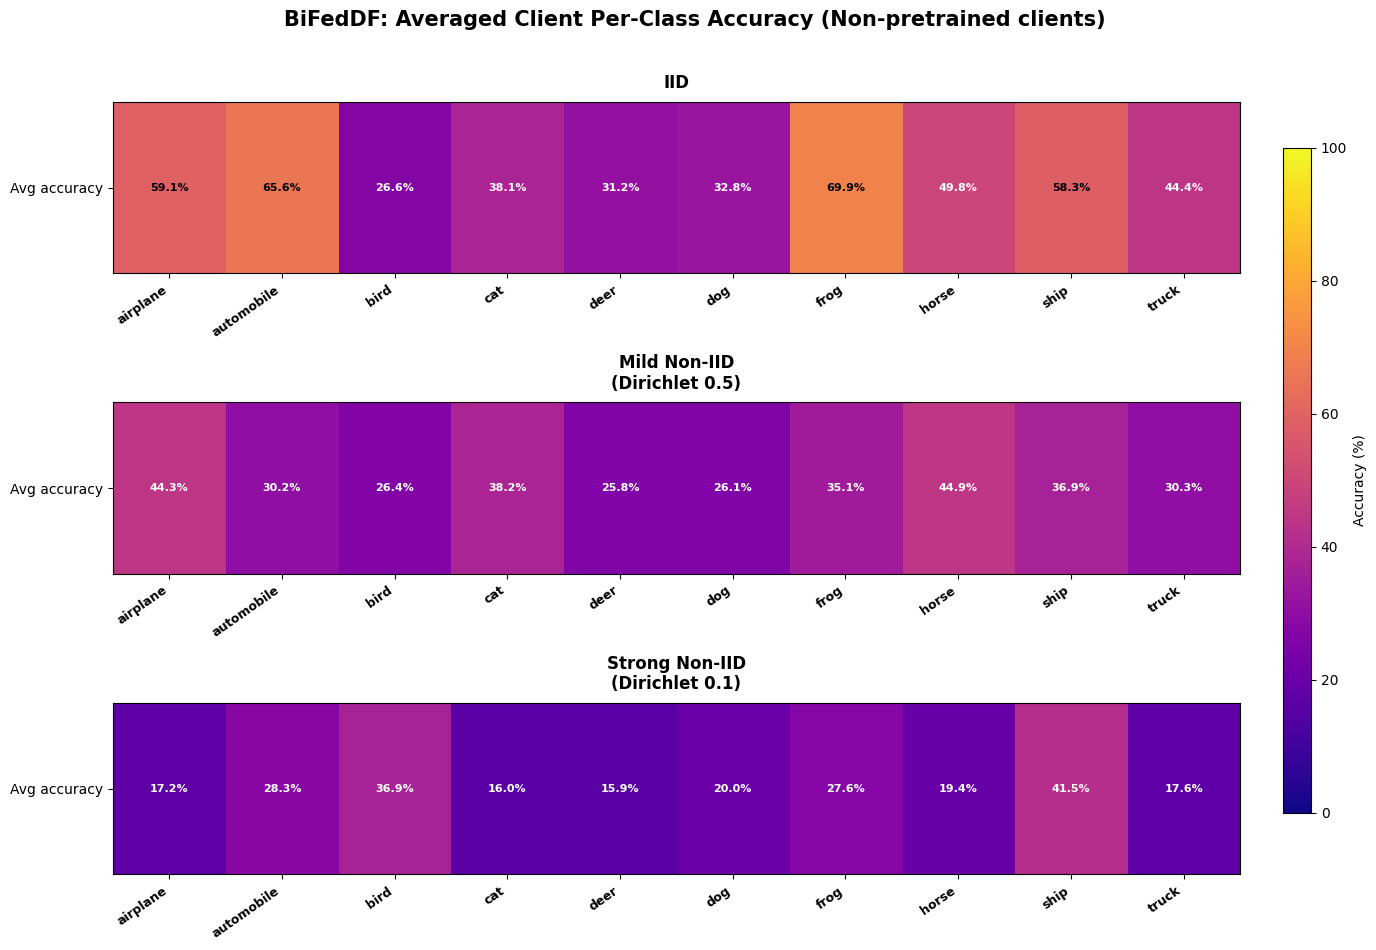

In [55]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Liberation Sans", "DejaVu Sans", "sans-serif"]

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Match cell 27: use a fresh single-worker loader for plotting/evaluation
eval_loader = DataLoader(
    eval_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

def average_client_per_class_accuracy(models, loader, device=device):
    per_model_acc = [compute_per_class_accuracy(model, loader, device=device) for model in models]
    return np.mean(per_model_acc, axis=0)

def plot_heatmap_group_stacked(title, heatmaps, cmap="viridis", save_name=None):
    fig, axes = plt.subplots(3, 1, figsize=(14, 9.5))
    fig.suptitle(title, fontsize=15, fontweight="bold", y=0.995)

    last_im = None

    for ax, (subplot_title, values) in zip(axes, heatmaps):
        last_im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect="auto", vmin=0, vmax=100)
        ax.set_title(subplot_title, fontsize=12, fontweight="bold", pad=10)
        ax.set_xticks(np.arange(len(class_names)))
        ax.set_xticklabels(class_names, rotation=35, ha="right", fontsize=9, fontweight="bold")
        ax.set_yticks([0])
        ax.set_yticklabels(["Avg accuracy"], fontsize=10)

        for i, value in enumerate(values):
            text_color = "white" if value < 50 else "black"
            ax.text(i, 0, f"{value:.1f}%", ha="center", va="center", color=text_color, fontsize=8, fontweight="bold")

    plt.tight_layout(rect=[0, 0, 0.90, 0.98])
    cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    fig.colorbar(last_im, cax=cax, label="Accuracy (%)")

    if save_name:
        save_path = os.path.join(SAVE_DIR, save_name)
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

feddf_server_heatmaps = [
    ("IID", compute_per_class_accuracy(feddf_iid_model, eval_loader, device=device)),
    ("Mild Non-IID\n(Dirichlet 0.5)", compute_per_class_accuracy(feddf_mod_model, eval_loader, device=device)),
    ("Strong Non-IID\n(Dirichlet 0.1)", compute_per_class_accuracy(feddf_strong_model, eval_loader, device=device)),
]

feddf_client_heatmaps = [
    ("IID", average_client_per_class_accuracy(clients_iid_models, eval_loader, device=device)),
    ("Mild Non-IID\n(Dirichlet 0.5)", average_client_per_class_accuracy(clients_mod_models, eval_loader, device=device)),
    ("Strong Non-IID\n(Dirichlet 0.1)", average_client_per_class_accuracy(clients_strong_models, eval_loader, device=device)),
]

bifeddf_server_heatmaps = [
    ("IID", compute_per_class_accuracy(bifeddf_iid_model, eval_loader, device=device)),
    ("Mild Non-IID\n(Dirichlet 0.5)", compute_per_class_accuracy(bifeddf_mod_model, eval_loader, device=device)),
    ("Strong Non-IID\n(Dirichlet 0.1)", compute_per_class_accuracy(bifeddf_strong_model, eval_loader, device=device)),
]

bifeddf_client_heatmaps = [
    ("IID", average_client_per_class_accuracy(clients_bidir_iid_models, eval_loader, device=device)),
    ("Mild Non-IID\n(Dirichlet 0.5)", average_client_per_class_accuracy(clients_bidir_mod_models, eval_loader, device=device)),
    ("Strong Non-IID\n(Dirichlet 0.1)", average_client_per_class_accuracy(clients_bidir_strong_models, eval_loader, device=device)),
]

plot_heatmap_group_stacked(
    "FedDF: Server Per-Class Accuracy (Non-pretrained clients)",
    feddf_server_heatmaps,
    cmap="viridis",
    save_name="feddf_server_per_class_accuracy_group.png",
)

plot_heatmap_group_stacked(
    "FedDF: Averaged Client Per-Class Accuracy (Non-pretrained clients)",
    feddf_client_heatmaps,
    cmap="plasma",
    save_name="feddf_client_per_class_accuracy_group.png",
)

plot_heatmap_group_stacked(
    "BiFedDF: Server Per-Class Accuracy (Non-pretrained clients)",
    bifeddf_server_heatmaps,
    cmap="viridis",
    save_name="bifeddf_server_per_class_accuracy_group.png",
)

plot_heatmap_group_stacked(
    "BiFedDF: Averaged Client Per-Class Accuracy (Non-pretrained clients)",
    bifeddf_client_heatmaps,
    cmap="plasma",
    save_name="bifeddf_client_per_class_accuracy_group.png",
)

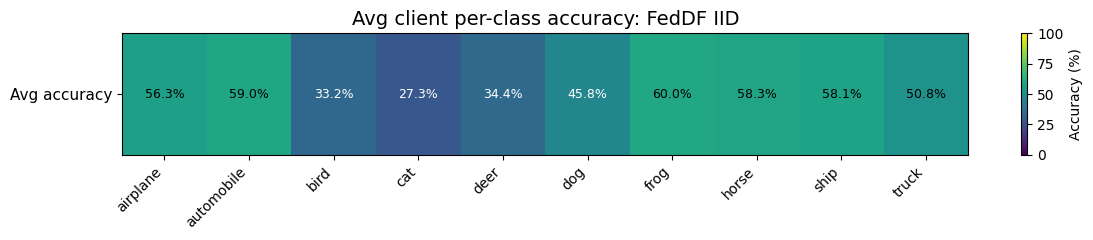

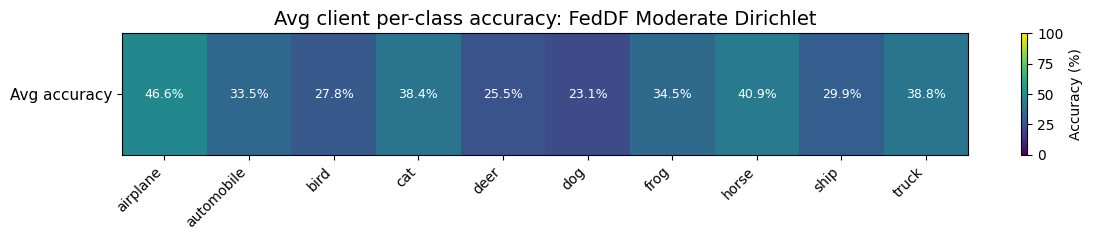

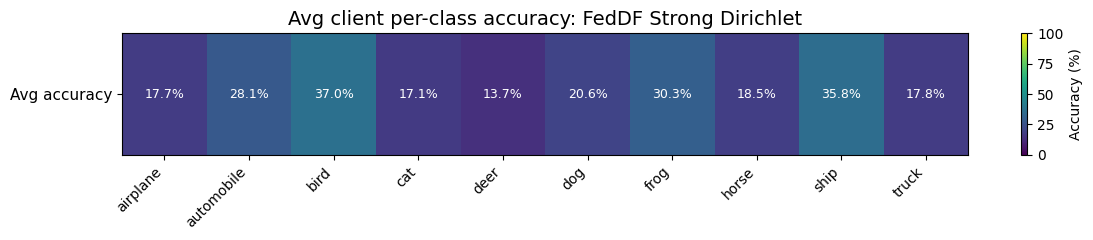

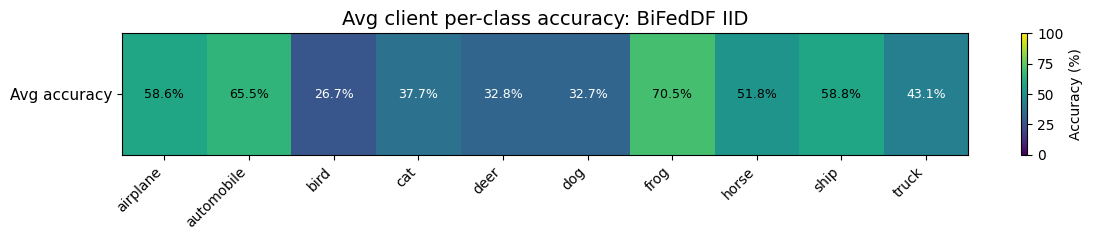

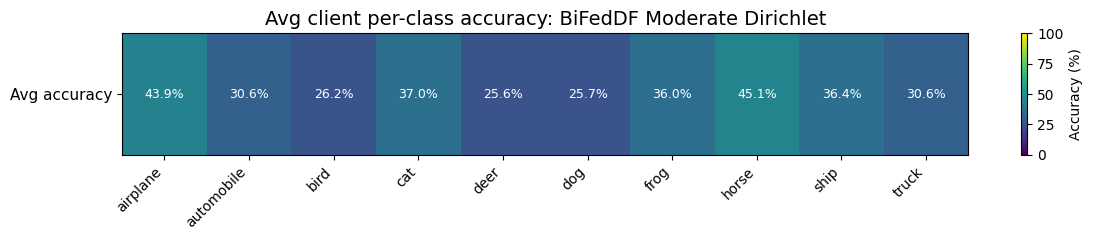

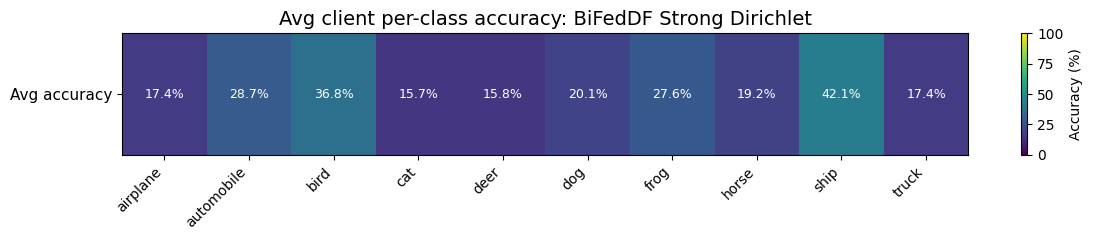

array([17.41803279, 28.65546218, 36.79104478, 15.703125  , 15.79617834,
       20.07827789, 27.5959596 , 19.1902834 , 42.08897485, 17.36      ])

In [22]:
def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

def plot_avg_per_class_accuracy_heatmap(models, loader, title, device=device, cmap='viridis'):
    all_acc = np.stack([compute_per_class_accuracy(m, loader, device) for m in models], axis=0)
    avg_acc = all_acc.mean(axis=0)

    class_names = [
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ]
    n_classes = len(class_names)

    fig, ax = plt.subplots(figsize=(12, 2.5))
    im = ax.imshow(avg_acc[np.newaxis, :], cmap=cmap, aspect='auto', vmin=0, vmax=100)

    ax.set_xticks(np.arange(n_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticks([0])
    ax.set_yticklabels(['Avg accuracy'], fontsize=11)

    for i, value in enumerate(avg_acc):
        text_color = 'white' if value < 50 else 'black'
        ax.text(i, 0, f'{value:.1f}%', ha='center', va='center', color=text_color, fontsize=9)

    fig.colorbar(im, ax=ax, orientation='vertical', label='Accuracy (%)')
    ax.set_title(title, fontsize=14)
    plt.tight_layout()
    plt.show()

    return avg_acc

plot_avg_per_class_accuracy_heatmap(
    clients_iid_models,
    test_loader,
    "Avg client per-class accuracy: FedDF IID"
)

plot_avg_per_class_accuracy_heatmap(
    clients_mod_models,
    test_loader,
    "Avg client per-class accuracy: FedDF Moderate Dirichlet"
)

plot_avg_per_class_accuracy_heatmap(
    clients_strong_models,
    test_loader,
    "Avg client per-class accuracy: FedDF Strong Dirichlet"
)

plot_avg_per_class_accuracy_heatmap(
    clients_bidir_iid_models,
    test_loader,
    "Avg client per-class accuracy: BiFedDF IID"
)

plot_avg_per_class_accuracy_heatmap(
    clients_bidir_mod_models,
    test_loader,
    "Avg client per-class accuracy: BiFedDF Moderate Dirichlet"
)

plot_avg_per_class_accuracy_heatmap(
    clients_bidir_strong_models,
    test_loader,
    "Avg client per-class accuracy: BiFedDF Strong Dirichlet"
)
    

P.S. plotting was done with LLM assistance

In [23]:

def run_whole_thing_again(seed):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
    ])

    trainSet = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
    testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

    proxy_size = len(testSet) // 2
    eval_size = len(testSet) - proxy_size
    proxy_subset, eval_subset = random_split(testSet, [proxy_size, eval_size], generator=torch.Generator().manual_seed(42))


    # Server Loaders
    proxy_loader = DataLoader(proxy_subset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=False)
    test_loader = DataLoader(eval_subset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=False)

    client_loaders_iid = []
    client_loaders_moderatedirichlet = []
    client_loaders_strongdirichlet = []

    client_ids_iid = list(range(len(trainSet)))
    client_ids_moderatedirichlet = dirichlet(trainSet, TOTAL_CLIENTS, alpha=0.5)
    client_ids_strongdirichlet = dirichlet(trainSet, TOTAL_CLIENTS, alpha=0.1)

    split_size = len(trainSet) // TOTAL_CLIENTS
    for i in range(TOTAL_CLIENTS):
        subset_indices = client_ids_iid[i*split_size : (i+1)*split_size]
        client_dataset = Subset(trainSet, subset_indices)
        client_loaders_iid.append(
            DataLoader(
                client_dataset,
                batch_size=BATCH_SIZE,
                shuffle=True,
                pin_memory=True,
                num_workers=NUM_WORKERS,
                persistent_workers=False
            )
        )

    for i in range(TOTAL_CLIENTS):
        client_dataset_moderate = Subset(trainSet, client_ids_moderatedirichlet[i])
        client_loaders_moderatedirichlet.append(
            DataLoader(
                client_dataset_moderate,
                batch_size=BATCH_SIZE,
                shuffle=True,
                pin_memory=True,
                num_workers=NUM_WORKERS,
                persistent_workers=False
            )
        )

        client_dataset_strong = Subset(trainSet, client_ids_strongdirichlet[i])
        client_loaders_strongdirichlet.append(
            DataLoader(
                client_dataset_strong,
                batch_size=BATCH_SIZE,
                shuffle=True,
                pin_memory=True,
                num_workers=NUM_WORKERS,
                persistent_workers=False
            )
        )

    feddf_iid_acc, feddf_iid_cost, feddf_iid_comm_hist, client_feddf_iid_acc_hist = run_feddf(client_loaders_iid, proxy_loader, test_loader, loader_for_name="iid" + f"_{seed}")
    feddf_mod_acc, feddf_mod_cost, feddf_mod_comm_hist, client_feddf_mod_acc_hist = run_feddf(client_loaders_moderatedirichlet, proxy_loader, test_loader, loader_for_name="moderatedirichlet" + f"_{seed}")
    feddf_strong_acc, feddf_strong_cost, feddf_strong_comm_hist, client_feddf_strong_acc_hist = run_feddf(client_loaders_strongdirichlet, proxy_loader, test_loader, loader_for_name="strongdirichlet" + f"_{seed}")
    bifeddf_iid_acc, bifeddf_iid_cost, bifeddf_iid_comm_hist, client_bifeddf_iid_acc_hist = run_feddf_bidirect(client_loaders_iid, proxy_loader, test_loader, loader_for_name="iid" + f"_{seed}")
    bifeddf_mod_acc, bifeddf_mod_cost, bifeddf_mod_comm_hist, client_bifeddf_mod_acc_hist = run_feddf_bidirect(client_loaders_moderatedirichlet, proxy_loader, test_loader, loader_for_name="moderatedirichlet" + f"_{seed}")
    bifeddf_strong_acc, bifeddf_strong_cost, bifeddf_strong_comm_hist, client_bifeddf_strong_acc_hist = run_feddf_bidirect(client_loaders_strongdirichlet, proxy_loader, test_loader, loader_for_name="strongdirichlet" + f"_{seed}")
    return {
        "feddf_iid_acc": feddf_iid_acc,
        "feddf_mod_acc": feddf_mod_acc,
        "feddf_strong_acc": feddf_strong_acc,
        "bifeddf_iid_acc": bifeddf_iid_acc,
        "bifeddf_mod_acc": bifeddf_mod_acc,
        "bifeddf_strong_acc": bifeddf_strong_acc,
        "client_feddf_iid_acc_hist": client_feddf_iid_acc_hist,
        "client_feddf_mod_acc_hist": client_feddf_mod_acc_hist,
        "client_feddf_strong_acc_hist": client_feddf_strong_acc_hist,
        "client_bifeddf_iid_acc_hist": client_bifeddf_iid_acc_hist,
        "client_bifeddf_mod_acc_hist": client_bifeddf_mod_acc_hist,
        "client_bifeddf_strong_acc_hist": client_bifeddf_strong_acc_hist,
    }





In [29]:
results_100 = run_whole_thing_again(seed=100)


/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")



 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:17<?, ?it/s, acc=88.80%]

 Round 1/70: Acc=88.80%


Fed Rounds:   1%|▊                                                           | 1/70 [00:40<21:47, 18.95s/it, acc=88.60%]

...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [29:38<00:50, 25.29s/it, acc=80.54%]

 Round 69/70: Acc=80.54%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [30:05<00:25, 25.27s/it, acc=80.22%]

 Round 70/70: Acc=80.22%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [30:05<00:00, 25.80s/it, acc=80.22%]


In [30]:
results_200 = run_whole_thing_again(seed=200)



 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:17<?, ?it/s, acc=88.94%]

 Round 1/70: Acc=88.94%


Fed Rounds:   1%|▊                                                           | 1/70 [00:36<21:32, 18.73s/it, acc=88.30%]

 Round 2/70: Acc=88.30%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [29:12<00:51, 25.76s/it, acc=76.76%]

 Round 69/70: Acc=76.76%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [29:37<00:25, 25.52s/it, acc=76.26%]

 Round 70/70: Acc=76.26%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [29:38<00:00, 25.40s/it, acc=76.26%]


In [31]:
results_300 = run_whole_thing_again(seed=300)



 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:17<?, ?it/s, acc=88.64%]

 Round 1/70: Acc=88.64%


Fed Rounds:   1%|▊                                                           | 1/70 [00:38<21:39, 18.83s/it, acc=88.68%]

 Round 2/70: Acc=88.68%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [31:26<00:54, 27.43s/it, acc=78.06%]

 Round 69/70: Acc=78.06%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [31:53<00:27, 27.41s/it, acc=76.64%]

 Round 70/70: Acc=76.64%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [31:54<00:00, 27.35s/it, acc=76.64%]


In [32]:
results_400 = run_whole_thing_again(seed=400)



 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:28<?, ?it/s, acc=88.60%]

 Round 1/70: Acc=88.60%


Fed Rounds:   1%|▊                                                           | 1/70 [00:51<34:41, 30.17s/it, acc=88.84%]

 Round 2/70: Acc=88.84%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [29:59<00:52, 26.09s/it, acc=80.88%]

 Round 69/70: Acc=80.88%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [30:25<00:26, 26.09s/it, acc=81.60%]

 Round 70/70: Acc=81.60%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [30:26<00:00, 26.09s/it, acc=81.60%]


In [33]:
results_500 = run_whole_thing_again(seed=500)


 Starting FedDF


Fed Rounds:   0%|                                                                    | 0/70 [00:20<?, ?it/s, acc=88.98%]

 Round 1/70: Acc=88.98%


Fed Rounds:   1%|▊                                                           | 1/70 [00:40<24:07, 20.97s/it, acc=88.78%]

 Round 2/70: Acc=88.78%


...

Fed Rounds:  97%|█████████████████████████████████████████████████████████▎ | 68/70 [29:12<00:52, 26.15s/it, acc=83.62%]

 Round 69/70: Acc=83.62%


Fed Rounds:  99%|██████████████████████████████████████████████████████████▏| 69/70 [29:39<00:26, 26.41s/it, acc=84.00%]

 Round 70/70: Acc=84.00%


Fed Rounds: 100%|███████████████████████████████████████████████████████████| 70/70 [29:40<00:00, 25.43s/it, acc=84.00%]


In [24]:
def aggregate_results(results_list):
    aggregated = {
        "feddf_iid_acc": [],
        "feddf_mod_acc": [],
        "feddf_strong_acc": [],
        "bifeddf_iid_acc": [],
        "bifeddf_mod_acc": [],
        "bifeddf_strong_acc": [],
        "client_feddf_iid_acc_hist": {},
        "client_feddf_mod_acc_hist": {},
        "client_feddf_strong_acc_hist": {},
        "client_bifeddf_iid_acc_hist": {},
        "client_bifeddf_mod_acc_hist": {},
        "client_bifeddf_strong_acc_hist": {},
    }

    for results in results_list:
        for key in aggregated.keys():
            if key.startswith("client_"):
                for client_id, acc_history in results[key].items():
                    if client_id not in aggregated[key]:
                        aggregated[key][client_id] = []
                    aggregated[key][client_id].append(acc_history)
            else:
                aggregated[key].append(results[key])

    return aggregated

def plot_all(aggregated_results, title_prefix=""):
    #this will create 3 plots (server accuracy, client accuracy, fusion gap) for each of the 6 runs (FedDF and BiFedDF with IID, moderate Dirichlet, and strong Dirichlet splits) for all the seeds (100, 200, 300, 400, 500). Not averaged, but plotted separately for each seed. The plots will be saved to disk with filenames indicating the seed and the type of plot.
    """
    Create 3 plots per seed:
    1) server accuracy
    2) client accuracy
    3) fusion gap

    Each seed gets its own figure set.
    """
    def _client_matrix(client_hist):
        if not client_hist:
            return np.array([])
        keys = sorted(client_hist.keys(), key=lambda k: int(k))
        return np.array([client_hist[k] for k in keys], dtype=float)

    runs = [
        ("FedDF iid",         aggregated_results["feddf_iid_acc"],      aggregated_results["client_feddf_iid_acc_hist"],    "#FFD000",   "-"),
        ("FedDF mod-Dir",     aggregated_results["feddf_mod_acc"],      aggregated_results["client_feddf_mod_acc_hist"],    "tab:orange", "-"),
        ("FedDF strong-Dir",  aggregated_results["feddf_strong_acc"],   aggregated_results["client_feddf_strong_acc_hist"], "tab:red",    "-"),
        ("BiFedDF iid",        aggregated_results["bifeddf_iid_acc"],    aggregated_results["client_bifeddf_iid_acc_hist"],    "#00FE31",   "--"),
        ("BiFedDF mod-Dir",    aggregated_results["bifeddf_mod_acc"],    aggregated_results["client_bifeddf_mod_acc_hist"],    "tab:cyan", "--"),
        ("BiFedDF strong-Dir", aggregated_results["bifeddf_strong_acc"], aggregated_results["client_bifeddf_strong_acc_hist"], "#0200AA",    "--"),
    ]

    # Each entry in aggregated_results["feddf_iid_acc"] is one seed's history list
    # We assume the same number of seeds exists for each run type.
    n_seeds = len(aggregated_results["feddf_iid_acc"])

    for seed_idx in range(n_seeds):
        seed_name = f"seed_{seed_idx + 1}"

        # --- 1) Server accuracy plot for this seed ---
        fig1, ax1 = plt.subplots(figsize=(8, 4))
        for name, server_hist, client_hist, color, ls in runs:
            if not server_hist:
                continue
            seed_server_hist = server_hist[seed_idx] if seed_idx < len(server_hist) else None
            if not seed_server_hist:
                continue

            rounds = np.arange(1, len(seed_server_hist) + 1)
            ax1.plot(
                rounds,
                seed_server_hist,
                label=name,
                color=color,
                linestyle=ls,
                marker="o",
                markersize=3,
                alpha=0.9
            )

        ax1.set_title(f"{title_prefix}{seed_name}: Server accuracy")
        ax1.set_xlabel("Round")
        ax1.set_ylabel("Accuracy (%)")
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc="lower left", fontsize=8)
        plt.tight_layout()
        fig1.savefig(os.path.join(SAVE_DIR, f"{title_prefix}{seed_name}_server_accuracy.png"), dpi=200)
        plt.close(fig1)

        # --- 2) Client accuracy plot for this seed ---
        fig2, ax2 = plt.subplots(figsize=(8, 4))
        for name, server_hist, client_hist, color, ls in runs:
            if not client_hist:
                continue

            # Structure is: client_id -> [hist_seed1, hist_seed2, ...]
            if isinstance(next(iter(client_hist.values()), None), list):
                client_ids = sorted(client_hist.keys(), key=lambda k: int(k))
                client_hist_seed = []
                for client_id in client_ids:
                    histories = client_hist[client_id]
                    if seed_idx < len(histories):
                        client_hist_seed.append(histories[seed_idx])

                if client_hist_seed:
                    arr = np.array(client_hist_seed, dtype=float)
                    if arr.ndim == 1:
                        arr = arr[np.newaxis, :]
                    rounds = np.arange(1, arr.shape[1] + 1)
                    mean_acc = arr.mean(axis=0)
                    min_acc = arr.min(axis=0)
                    max_acc = arr.max(axis=0)

                    ax2.plot(
                        rounds,
                        mean_acc,
                        label=name,
                        color=color,
                        linestyle=ls,
                        marker="o",
                        markersize=3,
                        alpha=0.9
                    )
                    ax2.fill_between(rounds, min_acc, max_acc, color=color, alpha=0.12)

            else:
                # fallback
                arr = _client_matrix(client_hist)
                if arr.size == 0:
                    continue
                rounds = np.arange(1, arr.shape[1] + 1)
                mean_acc = arr.mean(axis=0)
                min_acc = arr.min(axis=0)
                max_acc = arr.max(axis=0)

                ax2.plot(
                    rounds,
                    mean_acc,
                    label=name,
                    color=color,
                    linestyle=ls,
                    marker="o",
                    markersize=3,
                    alpha=0.9
                )
                ax2.fill_between(rounds, min_acc, max_acc, color=color, alpha=0.12)

        ax2.set_title(f"{title_prefix}{seed_name}: Client accuracy")
        ax2.set_xlabel("Round")
        ax2.set_ylabel("Accuracy (%)")
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc="lower right", fontsize=8)
        plt.tight_layout()
        fig2.savefig(os.path.join(SAVE_DIR, f"{title_prefix}{seed_name}_client_accuracy.png"), dpi=200)
        plt.close(fig2)

        # --- 3) Fusion gap plot for this seed ---
        fig3, ax3 = plt.subplots(figsize=(8, 4))
        for name, server_hist, client_hist, color, ls in runs:
            if not server_hist or not client_hist:
                continue

            seed_server_hist = server_hist[seed_idx] if seed_idx < len(server_hist) else None
            if not seed_server_hist:
                continue

            if isinstance(next(iter(client_hist.values()), None), list):
                client_ids = sorted(client_hist.keys(), key=lambda k: int(k))
                client_hist_seed = []
                for client_id in client_ids:
                    histories = client_hist[client_id]
                    if seed_idx < len(histories):
                        client_hist_seed.append(histories[seed_idx])

                if client_hist_seed:
                    arr = np.array(client_hist_seed, dtype=float)
                    if arr.ndim == 1:
                        arr = arr[np.newaxis, :]
                    mean_client = arr.mean(axis=0)
                    n = min(len(seed_server_hist), len(mean_client))
                    rounds = np.arange(1, n + 1)
                    gap = np.asarray(seed_server_hist[:n]) - mean_client[:n]
                    ax3.plot(
                        rounds,
                        gap,
                        label=name,
                        color=color,
                        linestyle=ls,
                        marker="o",
                        markersize=3,
                        alpha=0.9
                    )
            else:
                arr = _client_matrix(client_hist)
                if arr.size == 0:
                    continue
                n = min(len(seed_server_hist), arr.shape[1])
                rounds = np.arange(1, n + 1)
                gap = np.asarray(seed_server_hist[:n]) - arr[:, :n].mean(axis=0)
                ax3.plot(
                    rounds,
                    gap,
                    label=name,
                    color=color,
                    linestyle=ls,
                    marker="o",
                    markersize=3,
                    alpha=0.9
                )

        ax3.axhline(0, color="black", linewidth=0.5, alpha=0.5)
        ax3.set_title(f"{title_prefix}{seed_name}: Fusion gap")
        ax3.set_xlabel("Round")
        ax3.set_ylabel("Δ accuracy (percentage points)")
        ax3.grid(True, alpha=0.3)
        ax3.legend(loc="center right", fontsize=8)
        plt.tight_layout()
        fig3.savefig(os.path.join(SAVE_DIR, f"{title_prefix}{seed_name}_fusion_gap.png"), dpi=200)
        plt.close(fig3)


In [31]:
aggregated = aggregate_results([results_100, results_200, results_300, results_400, results_500])
plot_all(aggregated, title_prefix="seeded_")

Averaged plots saved successfully to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/seeded_averaged_results.png


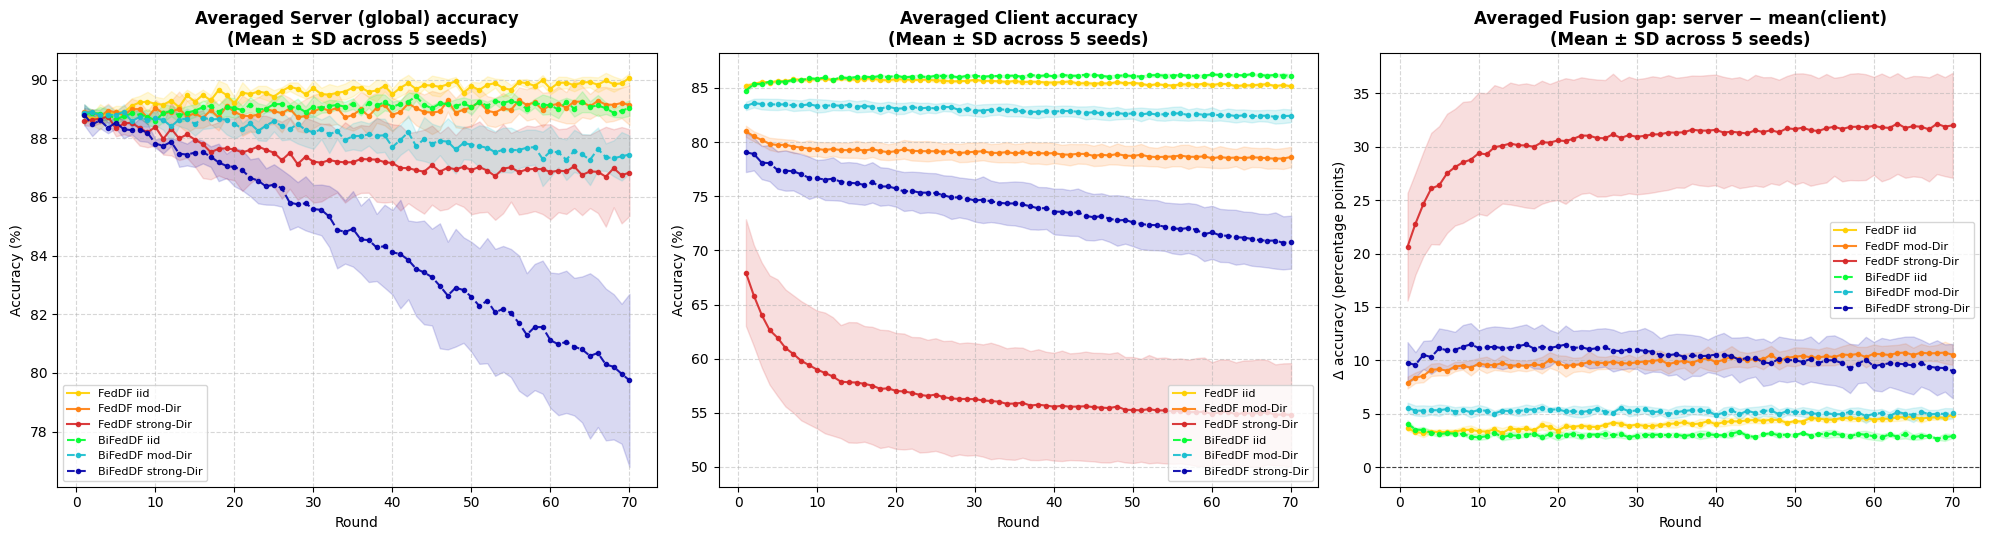

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import os

import matplotlib.pyplot as plt

# Global font configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Config matching your runs
runs_config = [
    ("FedDF iid",         "feddf_iid_acc",      "client_feddf_iid_acc_hist",    "#FFD000",   "-"),
    ("FedDF mod-Dir",     "feddf_mod_acc",      "client_feddf_mod_acc_hist",    "tab:orange", "-"),
    ("FedDF strong-Dir",  "feddf_strong_acc",   "client_feddf_strong_acc_hist", "tab:red",    "-"),
    ("BiFedDF iid",        "bifeddf_iid_acc",    "client_bifeddf_iid_acc_hist",    "#00FE31",   "--"),
    ("BiFedDF mod-Dir",    "bifeddf_mod_acc",    "client_bifeddf_mod_acc_hist",    "tab:cyan", "--"),
    ("BiFedDF strong-Dir", "bifeddf_strong_acc", "client_bifeddf_strong_acc_hist", "#0200AA",    "--"),
]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5.5))

for name, server_key, client_key, color, ls in runs_config:
    # 1. Process Server Accuracy over 5 seeds
    server_histories = aggregated[server_key]  # list of 5 seed lists
    if not server_histories:
        continue
    server_arr = np.array(server_histories)    # shape: (5, FED_ROUNDS)
    rounds = np.arange(1, server_arr.shape[1] + 1)
    
    mean_server = server_arr.mean(axis=0)
    std_server = server_arr.std(axis=0)
    
    # 2. Process Client Accuracy over 5 seeds
    client_hist_dict = aggregated[client_key]  # dict: client_id -> list of 5 seed lists
    if not client_hist_dict:
        continue
        
    client_data = []
    for c_id in sorted(client_hist_dict.keys(), key=lambda k: int(k)):
        client_data.append(client_hist_dict[c_id])
    client_arr = np.array(client_data)         # shape: (num_clients, num_seeds, FED_ROUNDS)
    
    # Calculate average client accuracy across clients per seed first, then take statistics across seeds
    seed_client_means = client_arr.mean(axis=0) # shape: (num_seeds, FED_ROUNDS)
    
    mean_client = seed_client_means.mean(axis=0)
    std_client = seed_client_means.std(axis=0)
    
    # 3. Process Fusion Gap (Server Acc - Avg Client Acc per seed)
    gap_arr = server_arr - seed_client_means   # shape: (num_seeds, FED_ROUNDS)
    mean_gap = gap_arr.mean(axis=0)
    std_gap = gap_arr.std(axis=0)
    
    # --- Plot 1: Averaged Server Accuracy ---
    ax1.plot(rounds, mean_server, label=name, color=color, linestyle=ls, marker='o', markersize=3, alpha=0.9)
    ax1.fill_between(rounds, mean_server - std_server, mean_server + std_server, color=color, alpha=0.15)
    
    # --- Plot 2: Averaged Client Accuracy ---
    ax2.plot(rounds, mean_client, label=name, color=color, linestyle=ls, marker='o', markersize=3, alpha=0.9)
    ax2.fill_between(rounds, mean_client - std_client, mean_client + std_client, color=color, alpha=0.15)
    
    # --- Plot 3: Averaged Fusion Gap ---
    ax3.plot(rounds, mean_gap, label=name, color=color, linestyle=ls, marker='o', markersize=3, alpha=0.9)
    ax3.fill_between(rounds, mean_gap - std_gap, mean_gap + std_gap, color=color, alpha=0.15)

# Styling Plot 1 (Server Accuracy)
ax1.set_title("Averaged Server (global) accuracy\n(Mean ± SD across 5 seeds)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Round", fontsize=10)
ax1.set_ylabel("Accuracy (%)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc="lower left", fontsize=8)

# Styling Plot 2 (Client Accuracy)
ax2.set_title("Averaged Client accuracy\n(Mean ± SD across 5 seeds)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Round", fontsize=10)
ax2.set_ylabel("Accuracy (%)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc="lower right", fontsize=8)

# Styling Plot 3 (Fusion Gap)
ax3.axhline(0, color="black", linewidth=0.8, linestyle='--', alpha=0.7)
ax3.set_title("Averaged Fusion gap: server − mean(client)\n(Mean ± SD across 5 seeds)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Round", fontsize=10)
ax3.set_ylabel("Δ accuracy (percentage points)", fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc="center right", fontsize=8)

plt.tight_layout()

# Save to your specified SAVE_DIR
avg_plot_path = os.path.join(SAVE_DIR, "seeded_averaged_results.png")
plt.savefig(avg_plot_path, dpi=300)
print(f"Averaged plots saved successfully to: {avg_plot_path}")
plt.show()

Saved server accuracy plot to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/seeded_averaged_server_accuracy.png


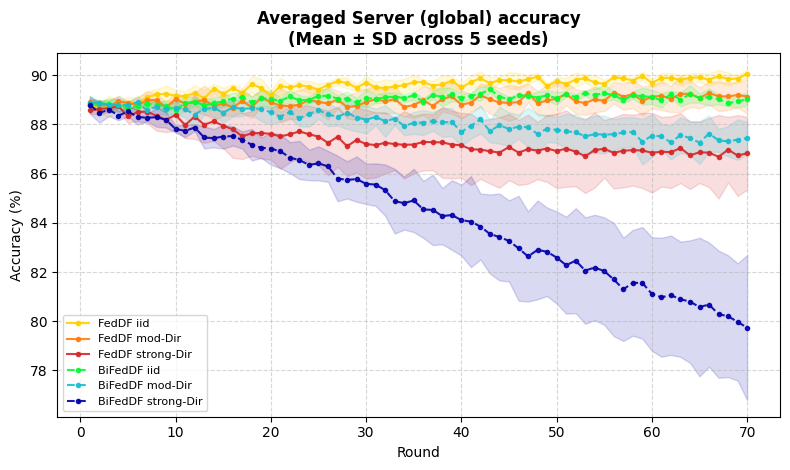

Saved client accuracy plot to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/seeded_averaged_client_accuracy.png


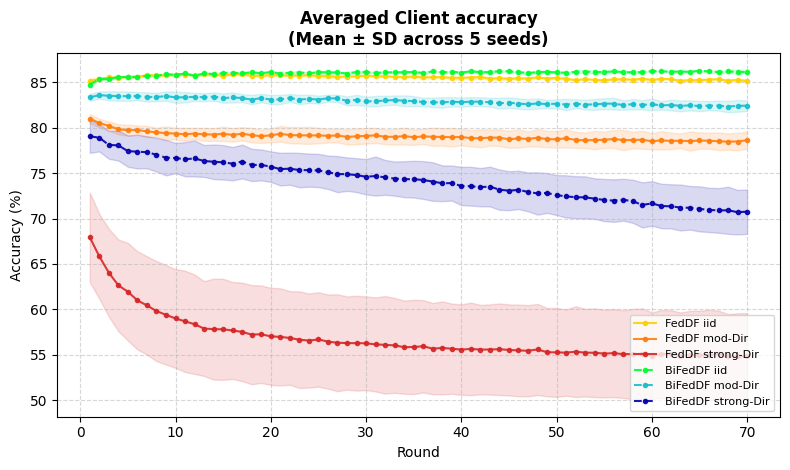

Saved server-client difference plot to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/seeded_averaged_server_client_difference.png


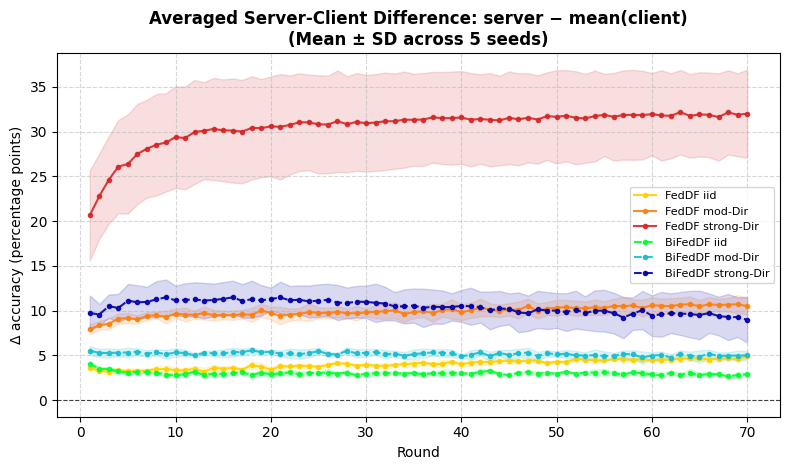

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Global font configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Config matching your runs
runs_config = [
    ("FedDF iid",         "feddf_iid_acc",      "client_feddf_iid_acc_hist",    "#FFD000",   "-"),
    ("FedDF mod-Dir",     "feddf_mod_acc",      "client_feddf_mod_acc_hist",    "tab:orange", "-"),
    ("FedDF strong-Dir",  "feddf_strong_acc",   "client_feddf_strong_acc_hist", "tab:red",    "-"),
    ("BiFedDF iid",       "bifeddf_iid_acc",    "client_bifeddf_iid_acc_hist",  "#00FE31",   "--"),
    ("BiFedDF mod-Dir",   "bifeddf_mod_acc",    "client_bifeddf_mod_acc_hist",  "tab:cyan",  "--"),
    ("BiFedDF strong-Dir","bifeddf_strong_acc", "client_bifeddf_strong_acc_hist","#0200AA",   "--"),
]

def _client_seed_array(client_hist_dict):
    """
    Convert:
      client_id -> [seed1_history, seed2_history, ...]
    into:
      array with shape (n_clients, n_seeds, n_rounds)
    """
    if not client_hist_dict:
        return None

    client_ids = sorted(client_hist_dict.keys(), key=lambda k: int(k))
    per_client = []

    for client_id in client_ids:
        histories = client_hist_dict.get(client_id, [])
        if not histories:
            continue
        per_client.append(np.asarray(histories, dtype=float))

    if not per_client:
        return None

    arr = np.asarray(per_client, dtype=float)

    # Expected shape: (n_clients, n_seeds, n_rounds)
    if arr.ndim != 3:
        return None

    return arr

# -----------------------------
# 1) Averaged Server Accuracy
# -----------------------------
fig1, ax1 = plt.subplots(figsize=(8, 4.8))

for name, server_key, client_key, color, ls in runs_config:
    server_histories = aggregated[server_key]  # list of seed-wise server histories
    if not server_histories:
        continue

    server_arr = np.asarray(server_histories, dtype=float)  # (n_seeds, n_rounds)
    mean_server = server_arr.mean(axis=0)
    std_server = server_arr.std(axis=0)
    rounds = np.arange(1, len(mean_server) + 1)

    ax1.plot(rounds, mean_server, label=name, color=color, linestyle=ls,
             marker='o', markersize=3, alpha=0.9)
    ax1.fill_between(rounds, mean_server - std_server, mean_server + std_server,
                     color=color, alpha=0.15)

ax1.set_title("Averaged Server (global) accuracy\n(Mean ± SD across 5 seeds)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Round", fontsize=10)
ax1.set_ylabel("Accuracy (%)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc="lower left", fontsize=8)

plt.tight_layout()
server_plot_path = os.path.join(SAVE_DIR, "seeded_averaged_server_accuracy.png")
plt.savefig(server_plot_path, dpi=300)
print(f"Saved server accuracy plot to: {server_plot_path}")
plt.show()
plt.close(fig1)

# -----------------------------
# 2) Averaged Client Accuracy
# -----------------------------
fig2, ax2 = plt.subplots(figsize=(8, 4.8))

for name, server_key, client_key, color, ls in runs_config:
    client_arr = _client_seed_array(aggregated[client_key])
    if client_arr is None:
        continue

    # client_arr: (n_clients, n_seeds, n_rounds)
    seed_client_means = client_arr.mean(axis=0)  # (n_seeds, n_rounds)
    mean_client = seed_client_means.mean(axis=0)
    std_client = seed_client_means.std(axis=0)
    rounds = np.arange(1, len(mean_client) + 1)

    ax2.plot(rounds, mean_client, label=name, color=color, linestyle=ls,
             marker='o', markersize=3, alpha=0.9)
    ax2.fill_between(rounds, mean_client - std_client, mean_client + std_client,
                     color=color, alpha=0.15)

ax2.set_title("Averaged Client accuracy\n(Mean ± SD across 5 seeds)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Round", fontsize=10)
ax2.set_ylabel("Accuracy (%)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc="lower right", fontsize=8)

plt.tight_layout()
client_plot_path = os.path.join(SAVE_DIR, "seeded_averaged_client_accuracy.png")
plt.savefig(client_plot_path, dpi=300)
print(f"Saved client accuracy plot to: {client_plot_path}")
plt.show()
plt.close(fig2)

# -----------------------------
# 3) Server-Client Difference
# -----------------------------
fig3, ax3 = plt.subplots(figsize=(8, 4.8))

for name, server_key, client_key, color, ls in runs_config:
    server_histories = aggregated[server_key]
    client_arr = _client_seed_array(aggregated[client_key])

    if not server_histories or client_arr is None:
        continue

    server_arr = np.asarray(server_histories, dtype=float)  # (n_seeds, n_rounds)
    seed_client_means = client_arr.mean(axis=0)              # (n_seeds, n_rounds)

    n_seeds = min(server_arr.shape[0], seed_client_means.shape[0])
    n_rounds = min(server_arr.shape[1], seed_client_means.shape[1])

    server_arr = server_arr[:n_seeds, :n_rounds]
    seed_client_means = seed_client_means[:n_seeds, :n_rounds]

    diff_arr = server_arr - seed_client_means
    mean_diff = diff_arr.mean(axis=0)
    std_diff = diff_arr.std(axis=0)
    rounds = np.arange(1, len(mean_diff) + 1)

    ax3.plot(rounds, mean_diff, label=name, color=color, linestyle=ls,
             marker='o', markersize=3, alpha=0.9)
    ax3.fill_between(rounds, mean_diff - std_diff, mean_diff + std_diff,
                     color=color, alpha=0.15)

ax3.axhline(0, color="black", linewidth=0.8, linestyle='--', alpha=0.7)
ax3.set_title("Averaged Server-Client Difference: server − mean(client)\n(Mean ± SD across 5 seeds)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Round", fontsize=10)
ax3.set_ylabel("Δ accuracy (percentage points)", fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc="center right", fontsize=8)

plt.tight_layout()
diff_plot_path = os.path.join(SAVE_DIR, "seeded_averaged_server_client_difference.png")
plt.savefig(diff_plot_path, dpi=300)
print(f"Saved server-client difference plot to: {diff_plot_path}")
plt.show()
plt.close(fig3)

Starting per-class accuracy calculation across 5 seeds...


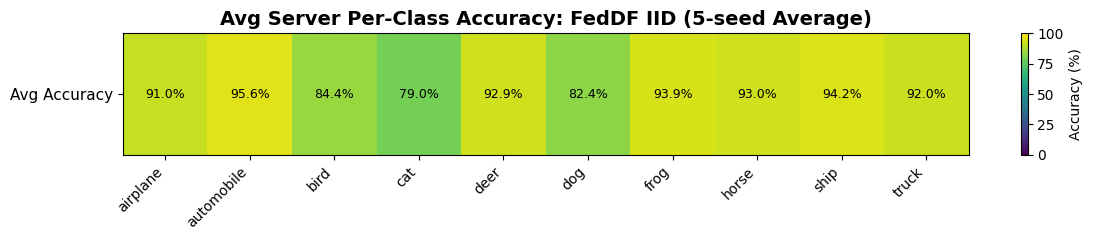

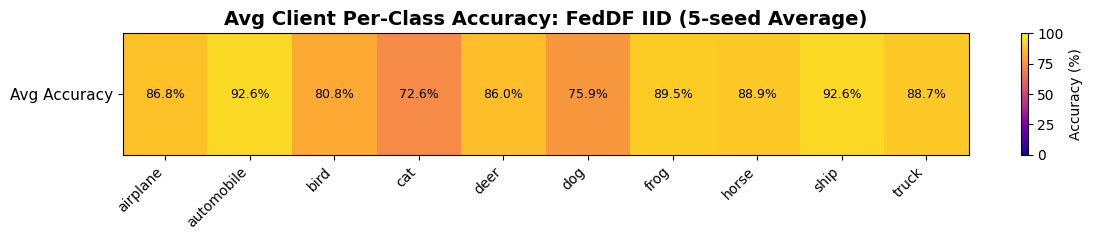

------------------------------------------------------------


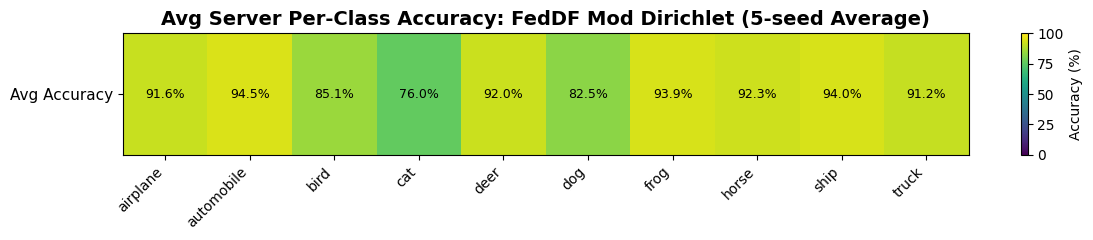

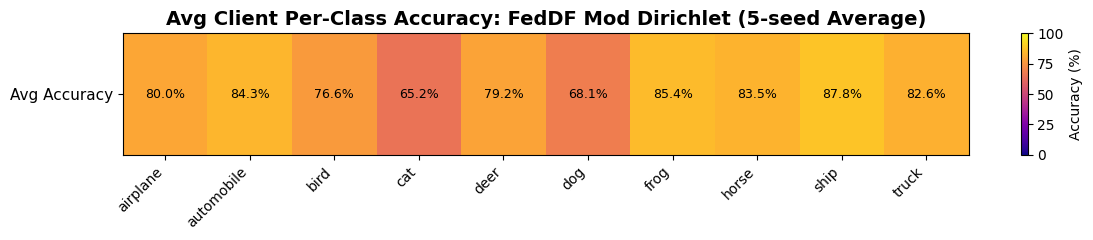

------------------------------------------------------------


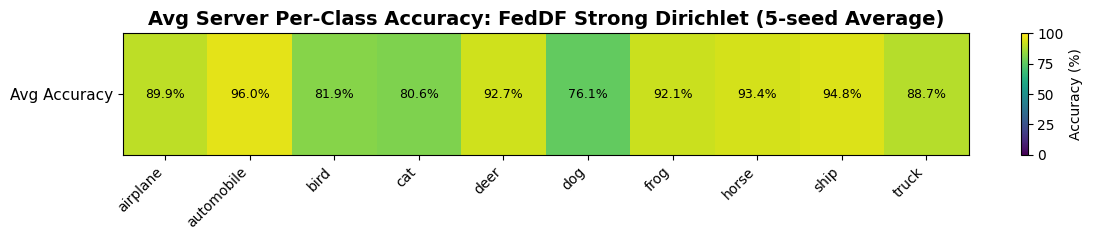

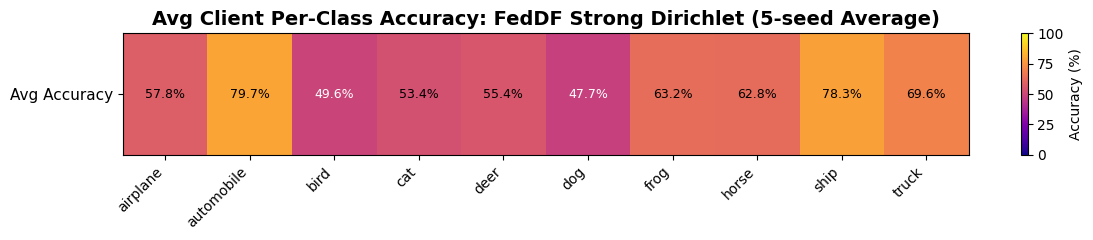

------------------------------------------------------------


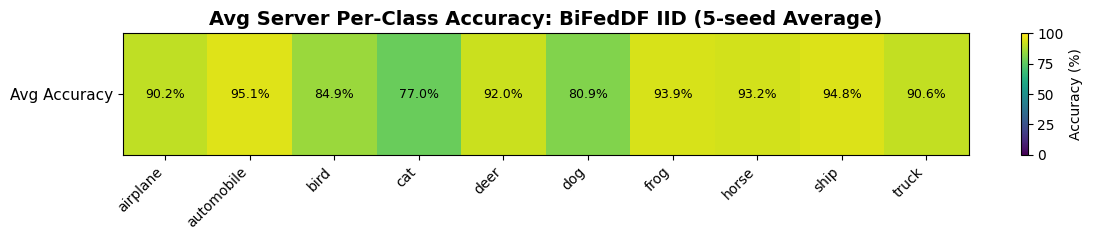

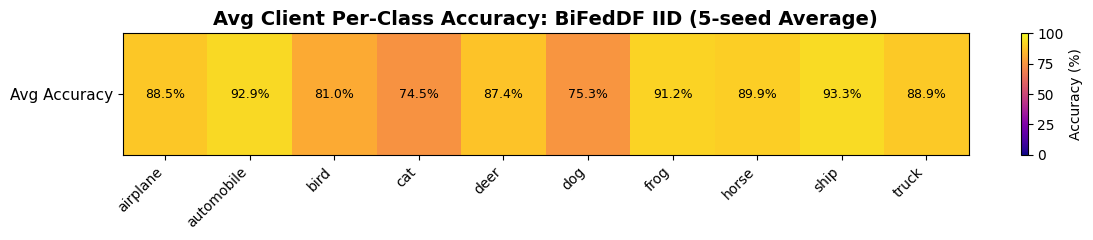

------------------------------------------------------------


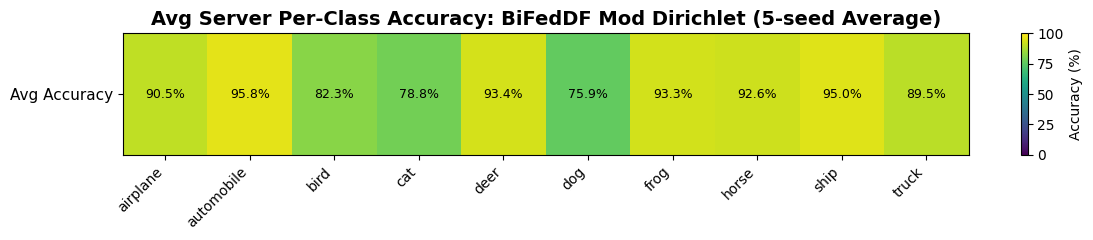

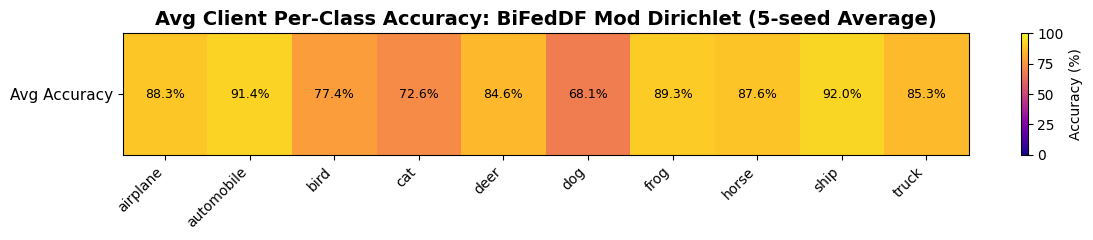

------------------------------------------------------------


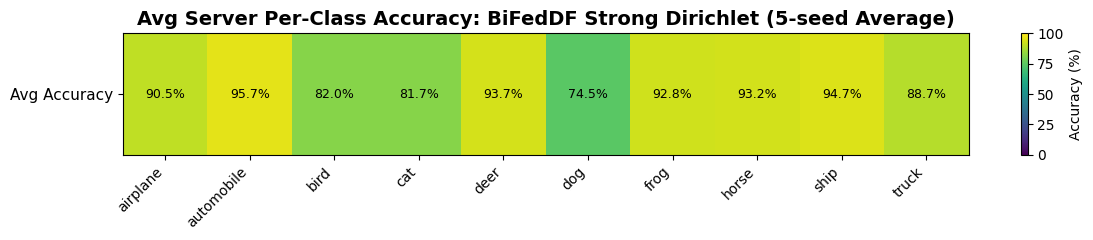

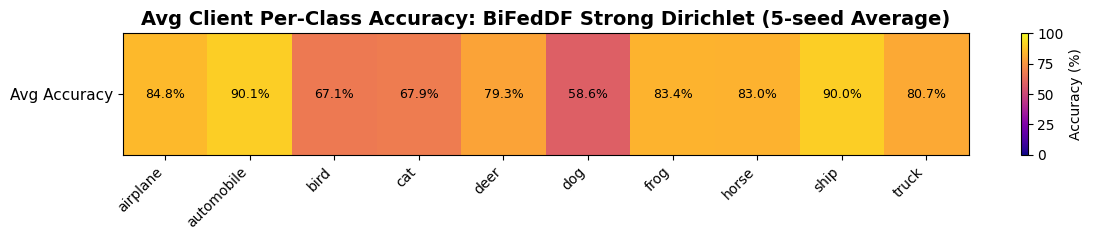

------------------------------------------------------------


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

# 1. Helper function to compute per-class accuracy for a model
def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

# 2. Helper to plot the heatmap
def plot_averaged_heatmap(acc_matrix, title, cmap='viridis'):
    class_names = [
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ]
    n_classes = len(class_names)

    fig, ax = plt.subplots(figsize=(12, 2.5))
    im = ax.imshow(acc_matrix[np.newaxis, :], cmap=cmap, aspect='auto', vmin=0, vmax=100)

    ax.set_xticks(np.arange(n_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticks([0])
    ax.set_yticklabels(['Avg Accuracy'], fontsize=11)

    for i, value in enumerate(acc_matrix):
        text_color = 'white' if value < 50 else 'black'
        ax.text(i, 0, f'{value:.1f}%', ha='center', va='center', color=text_color, fontsize=9)

    fig.colorbar(im, ax=ax, orientation='vertical', label='Accuracy (%)')
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Seeds and runs configurations
seeds = [100, 200, 300, 400, 500]
runs = [
    ("FedDF IID",              "feddf_basic", "iid"),
    ("FedDF Mod Dirichlet",      "feddf_basic", "moderatedirichlet"),
    ("FedDF Strong Dirichlet",   "feddf_basic", "strongdirichlet"),
    ("BiFedDF IID",             "feddf_bidir", "iid"),
    ("BiFedDF Mod Dirichlet",     "feddf_bidir", "moderatedirichlet"),
    ("BiFedDF Strong Dirichlet",  "feddf_bidir", "strongdirichlet")
]

print("Starting per-class accuracy calculation across 5 seeds...\n" + "="*60)

for display_name, run_prefix, loader_base in runs:
    server_seed_accs = []
    client_seed_accs = []
    
    for seed in seeds:
        loader_name = f"{loader_base}_{seed}"
        
        # --- A. Load Server (Global) Model and compute accuracy ---
        global_path = os.path.join(SAVE_DIR, f'{run_prefix}_best_{loader_name}.pth')
        if os.path.exists(global_path):
            server_model = get_teacher_model().to(device)
            server_model.load_state_dict(torch.load(global_path, map_location=device, weights_only=True))
            
            s_acc = compute_per_class_accuracy(server_model, test_loader, device)
            server_seed_accs.append(s_acc)
        else:
            print(f"Warning: missing server model at {global_path}")
            
        # --- B. Load Client Models and compute average accuracy ---
        seed_client_accs = []
        for c_id in range(TOTAL_CLIENTS):
            client_path = os.path.join(SAVE_DIR, f'{run_prefix}_student_client{c_id}_best_{loader_name}.pth')
            if os.path.exists(client_path):
                client_model = Resnet14().to(device)
                client_model.load_state_dict(torch.load(client_path, map_location=device, weights_only=True))
                
                c_acc = compute_per_class_accuracy(client_model, test_loader, device)
                seed_client_accs.append(c_acc)
                
        if seed_client_accs:
            # Average clients per seed first
            client_seed_accs.append(np.mean(seed_client_accs, axis=0))
            
    # 3. Average across all 5 seeds and plot
    if server_seed_accs:
        avg_server_acc = np.mean(server_seed_accs, axis=0)
        plot_averaged_heatmap(
            avg_server_acc, 
            f"Avg Server Per-Class Accuracy: {display_name} (5-seed Average)"
        )
        
    if client_seed_accs:
        avg_client_acc = np.mean(client_seed_accs, axis=0)
        plot_averaged_heatmap(
            avg_client_acc, 
            f"Avg Client Per-Class Accuracy: {display_name} (5-seed Average)",
            cmap='plasma'
        )
        
    print("-"*60)

Reloading all models using Round 70 (_last_) checkpoints...
Successfully reloaded all models!

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_avg_server_per_class_accuracy_group_LAST.png


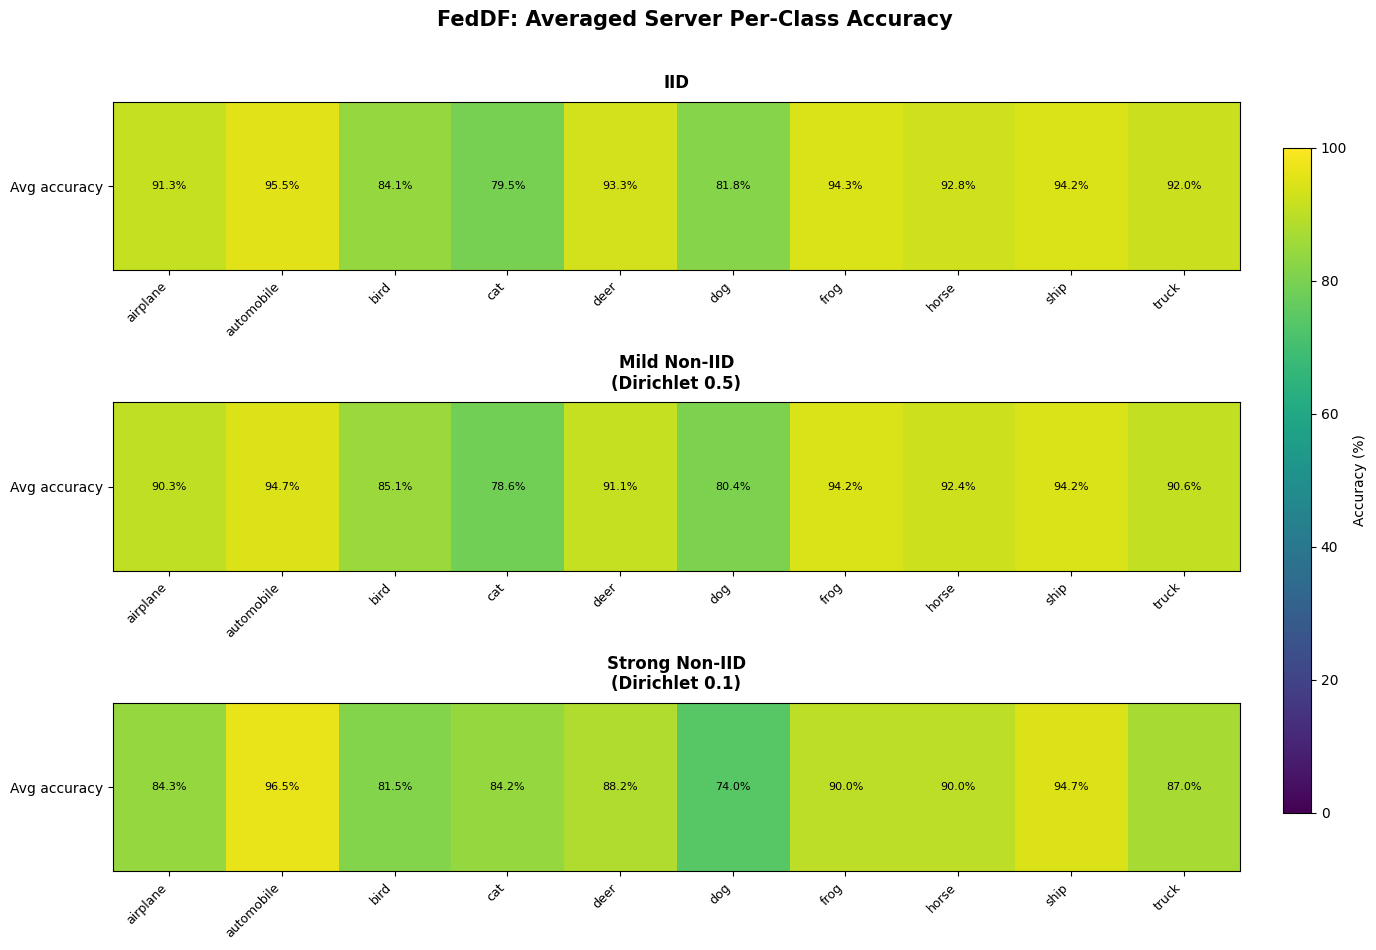

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_avg_client_per_class_accuracy_group_LAST.png


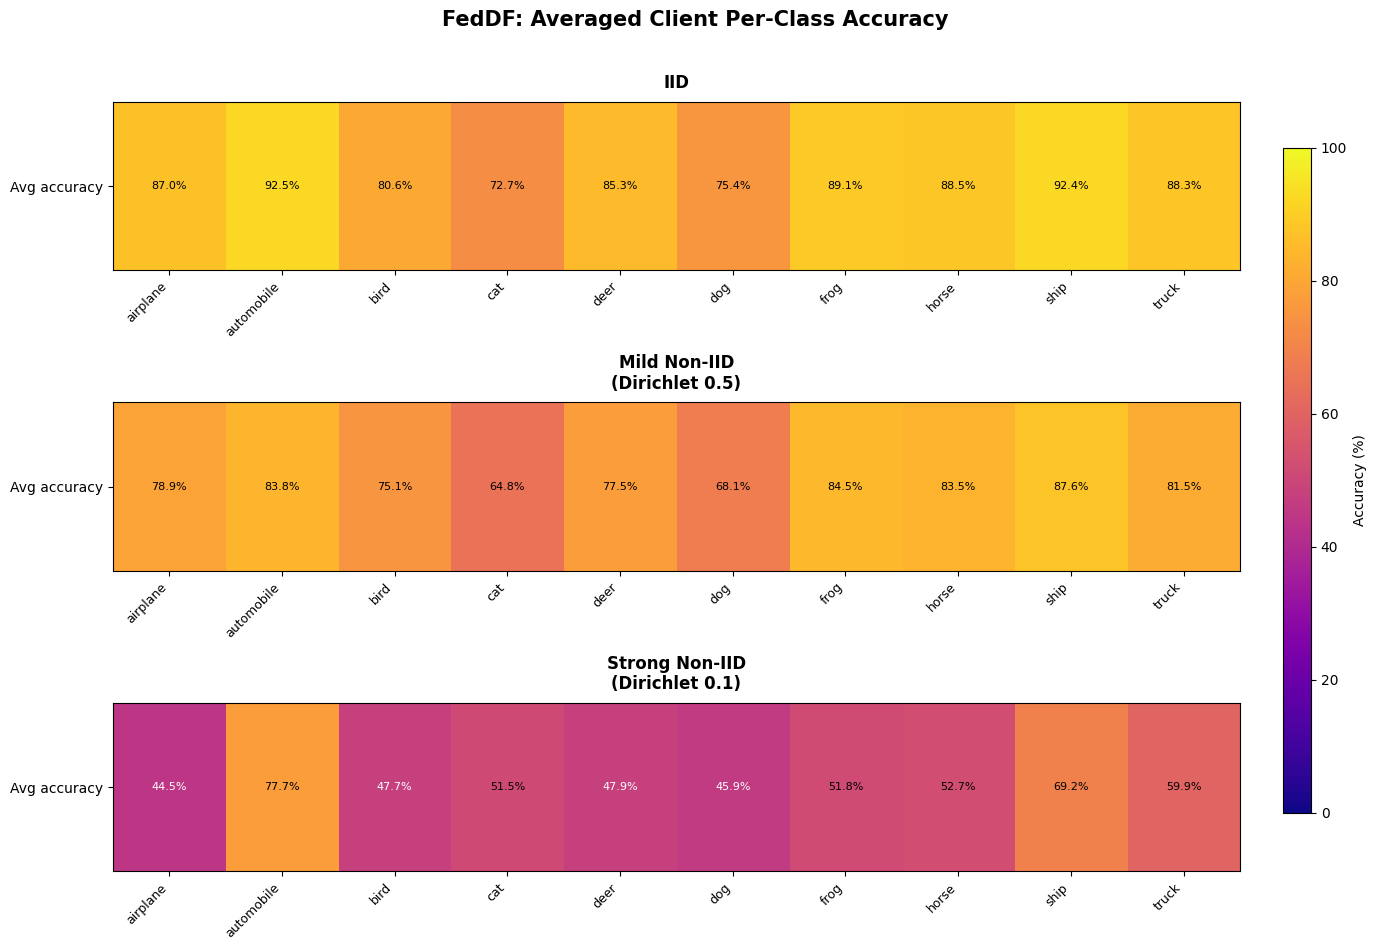

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_avg_server_per_class_accuracy_group_LAST.png


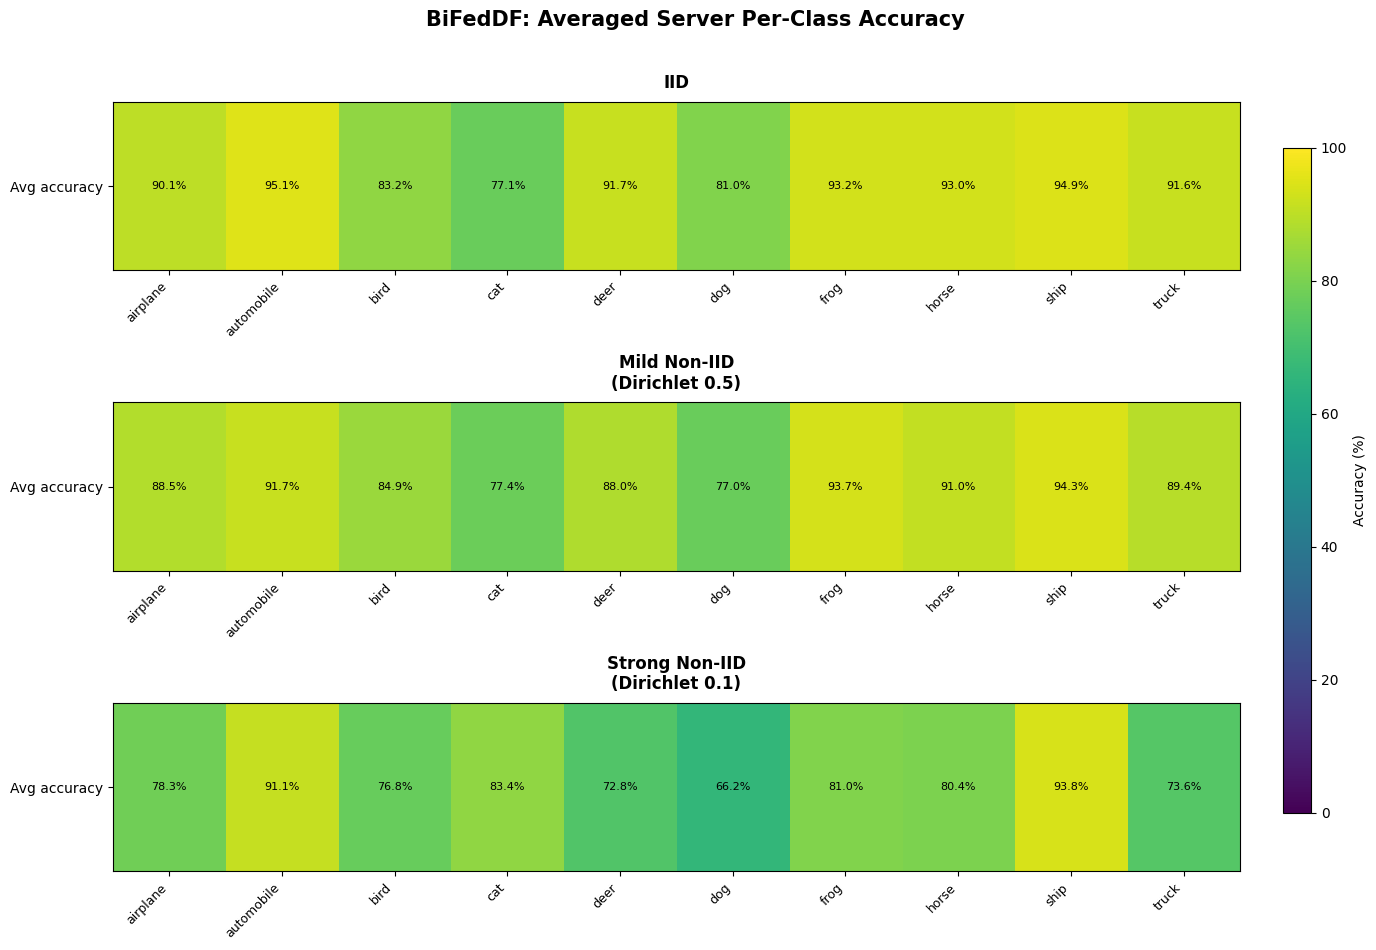

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_avg_client_per_class_accuracy_group_LAST.png


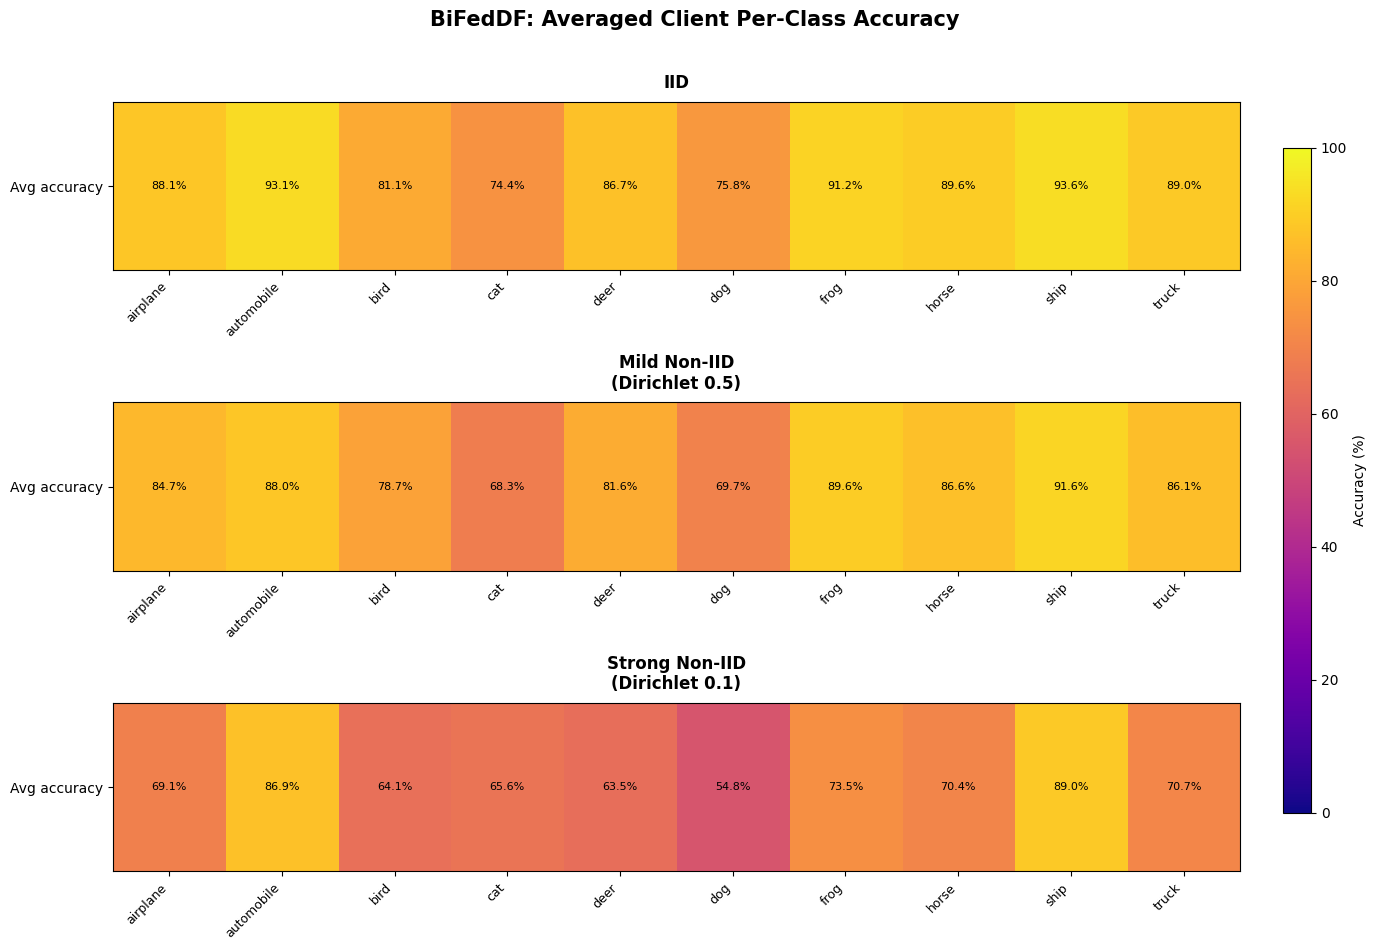

In [57]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
import json
from torch.utils.data import DataLoader

# ---------------------------------------------------------
# 1. FIX THE LOADER TO LOAD ROUND 70 (_last_) MODELS
# ---------------------------------------------------------
def load_saved_models_and_histories_LAST(run_prefix="feddf_basic", loader_name="iid", n_clients=5):
    global_model = get_teacher_model().to(device)
    
    # FIXED: loading '_last_' instead of '_best_'
    global_path = os.path.join(SAVE_DIR, f'{run_prefix}_last_{loader_name}.pth') 
    
    if os.path.exists(global_path):
        global_model.load_state_dict(torch.load(global_path, map_location=device, weights_only=True))
    else:
        print(f"Warning: no global model at {global_path}")
        
    client_models = [Resnet14().to(device) for _ in range(n_clients)]
    for c_id in range(n_clients):
        # FIXED: loading '_last_' instead of '_best_'
        client_path = os.path.join(SAVE_DIR, f'{run_prefix}_student_client{c_id}_last_{loader_name}.pth')
        if os.path.exists(client_path):
            client_models[c_id].load_state_dict(torch.load(client_path, map_location=device, weights_only=True))
        else:
            print(f"Warning: no client {c_id} model at {client_path}")
            
    history, comm_history, client_acc_history = [], [], {}
    history_path = os.path.join(SAVE_DIR, f"{run_prefix}_histories_{loader_name}.json")
    if os.path.exists(history_path):
        with open(history_path, "r") as f:
            data = json.load(f)
            history = data.get("history", [])
            comm_history = data.get("comm_history", [])
            raw_client_acc = data.get("client_acc_history", {})
            client_acc_history = {int(k): v for k, v in raw_client_acc.items()}
            
    return global_model, client_models, history, comm_history, client_acc_history

# ---------------------------------------------------------
# 2. REPOPULATE THE loaded_runs DICTIONARY
# ---------------------------------------------------------
print("Reloading all models using Round 70 (_last_) checkpoints...")
seeds = [100, 200, 300, 400, 500]

for run_prefix in loaded_runs.keys():
    for loader_base in loaded_runs[run_prefix].keys():
        for seed in seeds:
            loader_name_with_seed = f"{loader_base}_{seed}"
            
            g_model, c_models, hist, comm_hist, c_acc_hist = load_saved_models_and_histories_LAST(
                run_prefix=run_prefix,
                loader_name=loader_name_with_seed,
                n_clients=TOTAL_CLIENTS
            )
            
            loaded_runs[run_prefix][loader_base][seed] = {
                "global_model": g_model,
                "client_models": c_models,
                "history": hist,
                "comm_history": comm_hist,
                "client_acc_history": c_acc_hist
            }
print("Successfully reloaded all models!\n")

# ---------------------------------------------------------
# 3. YOUR EXACT PLOTTING CODE (Now using the correct data)
# ---------------------------------------------------------
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

eval_loader = DataLoader(
    eval_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

def plot_heatmap_group_stacked(title, heatmaps, cmap='viridis', save_name=None):
    fig, axes = plt.subplots(3, 1, figsize=(14, 9.5))
    fig.suptitle(title, fontsize=15, fontweight='bold', y=0.995)

    vmin, vmax = 0, 100
    last_im = None

    for ax, (subplot_title, values) in zip(axes, heatmaps):
        last_im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
        ax.set_title(subplot_title, fontsize=12, fontweight='bold', pad=10)
        ax.set_xticks(np.arange(len(class_names)))
        ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=9)
        ax.set_yticks([0])
        ax.set_yticklabels(['Avg accuracy'], fontsize=10)

        for i, value in enumerate(values):
            text_color = 'white' if value < 50 else 'black'
            ax.text(i, 0, f'{value:.1f}%', ha='center', va='center', color=text_color, fontsize=8)

    plt.tight_layout(rect=[0, 0, 0.90, 0.98])
    cax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) 
    fig.colorbar(last_im, cax=cax, label='Accuracy (%)')

    if save_name:
        save_path = os.path.join(SAVE_DIR, save_name)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

def average_server_and_client_per_class(run_prefix, loader_base, loader):
    seed_keys = sorted(loaded_runs[run_prefix][loader_base].keys())

    server_seed_accs = []
    client_seed_accs = []

    for seed in seed_keys:
        entry = loaded_runs[run_prefix][loader_base][seed]

        server_model = entry["global_model"]
        client_models = entry["client_models"]

        server_acc = compute_per_class_accuracy(server_model, loader, device)
        server_seed_accs.append(server_acc)

        client_accs = [compute_per_class_accuracy(m, loader, device) for m in client_models]
        client_seed_accs.append(np.mean(client_accs, axis=0))

    avg_server = np.mean(server_seed_accs, axis=0)
    avg_client = np.mean(client_seed_accs, axis=0)

    return avg_server, avg_client

feddf_configs = [
    ("IID", "feddf_basic", "iid"),
    ("Mild Non-IID\n(Dirichlet 0.5)", "feddf_basic", "moderatedirichlet"),
    ("Strong Non-IID\n(Dirichlet 0.1)", "feddf_basic", "strongdirichlet"),
]

bifeddf_configs = [
    ("IID", "feddf_bidir", "iid"),
    ("Mild Non-IID\n(Dirichlet 0.5)", "feddf_bidir", "moderatedirichlet"),
    ("Strong Non-IID\n(Dirichlet 0.1)", "feddf_bidir", "strongdirichlet"),
]

# Generate FedDF Plots
feddf_server_heatmaps = []
for label, run_prefix, loader_base in feddf_configs:
    avg_server, avg_client = average_server_and_client_per_class(run_prefix, loader_base, eval_loader)
    feddf_server_heatmaps.append((label, avg_server))

plot_heatmap_group_stacked(
    "FedDF: Averaged Server Per-Class Accuracy",
    feddf_server_heatmaps,
    cmap='viridis',
    save_name="feddf_avg_server_per_class_accuracy_group_LAST.png"
)

feddf_client_heatmaps = []
for label, run_prefix, loader_base in feddf_configs:
    avg_server, avg_client = average_server_and_client_per_class(run_prefix, loader_base, eval_loader)
    feddf_client_heatmaps.append((label, avg_client))

plot_heatmap_group_stacked(
    "FedDF: Averaged Client Per-Class Accuracy",
    feddf_client_heatmaps,
    cmap='plasma',
    save_name="feddf_avg_client_per_class_accuracy_group_LAST.png"
)

# Generate BiFedDF Plots
bifeddf_server_heatmaps = []
for label, run_prefix, loader_base in bifeddf_configs:
    avg_server, avg_client = average_server_and_client_per_class(run_prefix, loader_base, eval_loader)
    bifeddf_server_heatmaps.append((label, avg_server))

plot_heatmap_group_stacked(
    "BiFedDF: Averaged Server Per-Class Accuracy",
    bifeddf_server_heatmaps,
    cmap='viridis',
    save_name="bifeddf_avg_server_per_class_accuracy_group_LAST.png"
)

bifeddf_client_heatmaps = []
for label, run_prefix, loader_base in bifeddf_configs:
    avg_server, avg_client = average_server_and_client_per_class(run_prefix, loader_base, eval_loader)
    bifeddf_client_heatmaps.append((label, avg_client))

plot_heatmap_group_stacked(
    "BiFedDF: Averaged Client Per-Class Accuracy",
    bifeddf_client_heatmaps,
    cmap='plasma',
    save_name="bifeddf_avg_client_per_class_accuracy_group_LAST.png"
)

Calculating 5-seed averaged accuracy across 6 setups...
Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/avg_server_per_class_accuracy_group_6.png


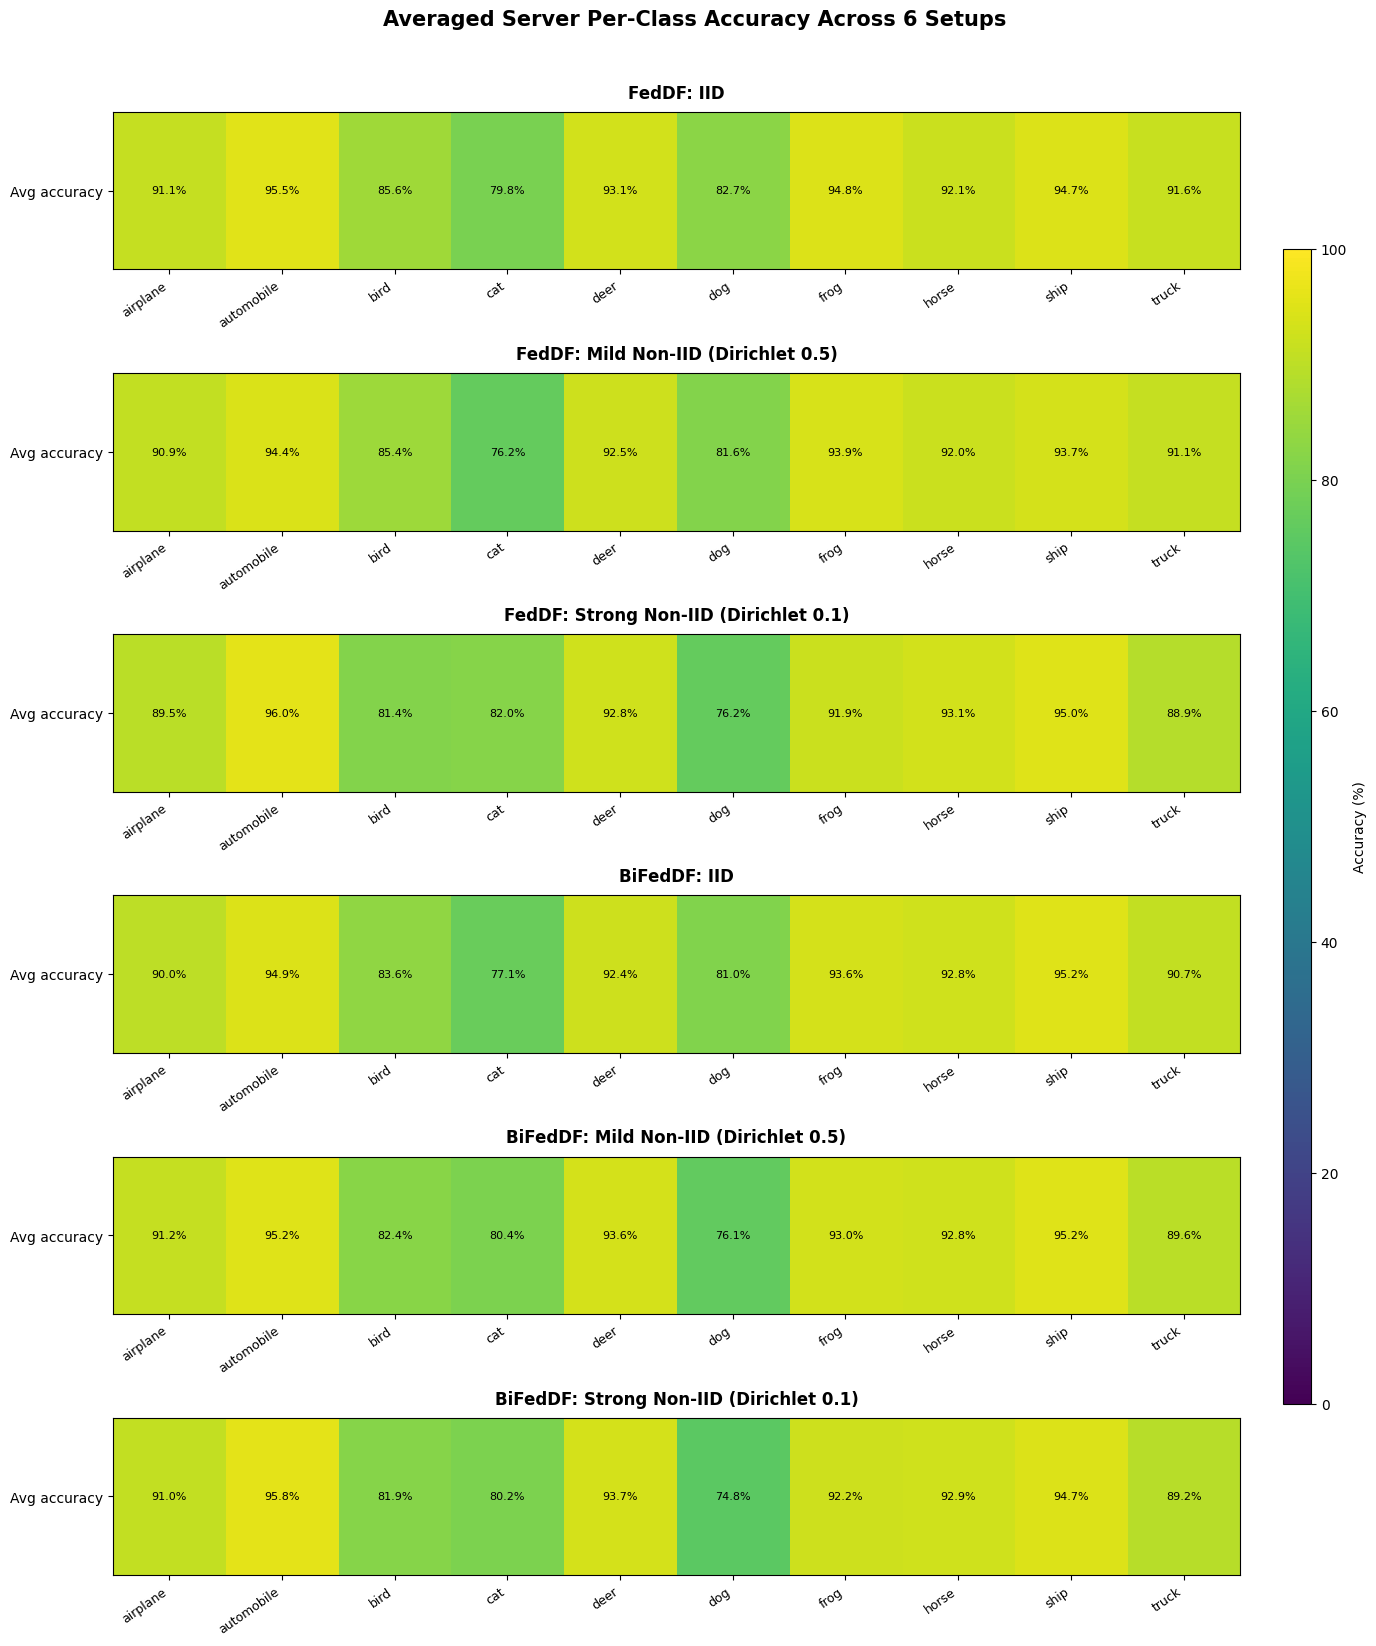

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/avg_client_per_class_accuracy_group_6.png


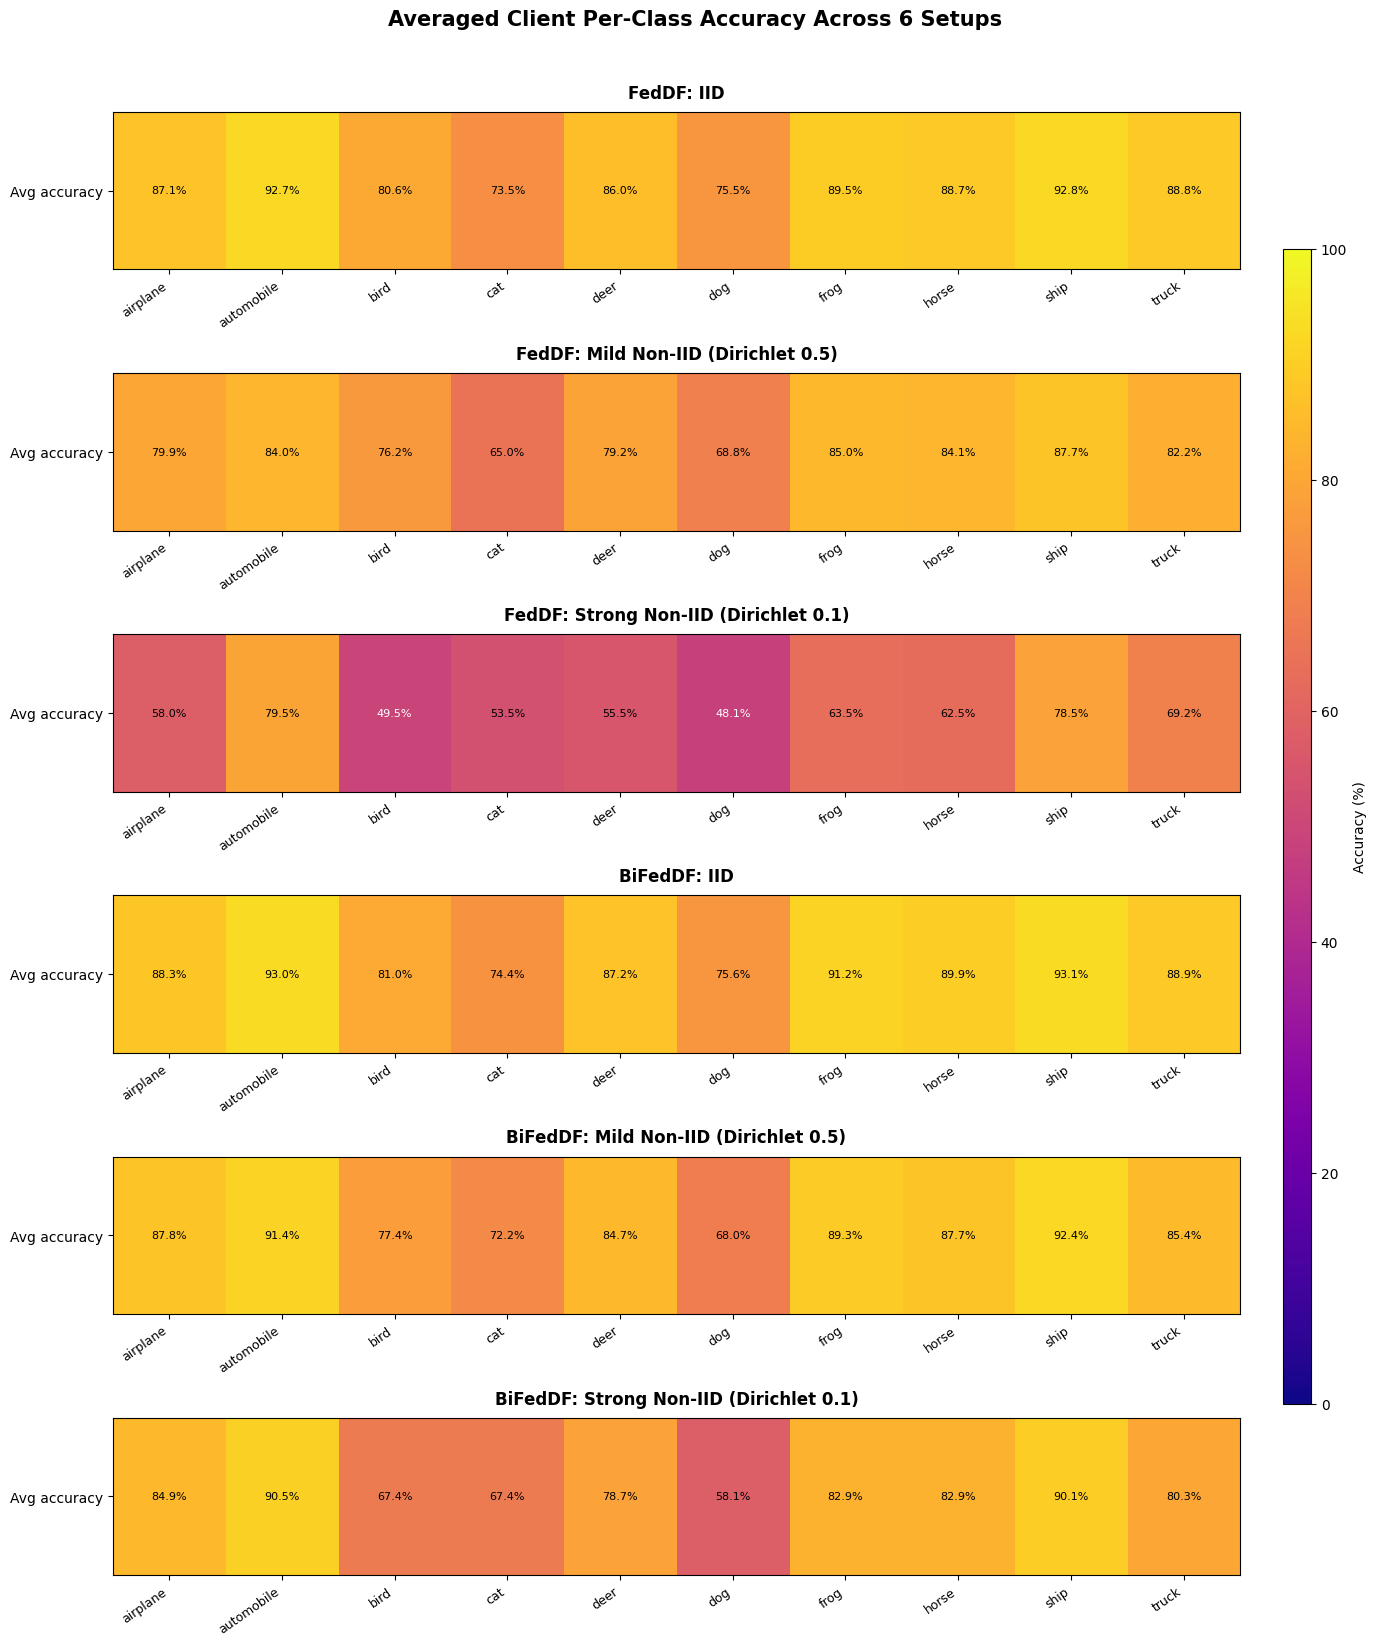

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
from torch.utils.data import DataLoader

# Font configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Fresh single-worker eval loader to avoid notebook/WSL multiprocessing crashes
eval_loader = DataLoader(
    eval_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

def plot_heatmap_group_stacked(title, heatmaps, cmap='viridis', save_name=None):
    n_rows = len(heatmaps)
    # Dynamically scale figure size based on the number of heatmaps
    fig, axes = plt.subplots(n_rows, 1, figsize=(14, 2.5 * n_rows + 1.5))
    fig.suptitle(title, fontsize=15, fontweight='bold', y=0.995)

    vmin, vmax = 0, 100
    last_im = None

    if n_rows == 1:
        axes = [axes]

    for ax, (subplot_title, values) in zip(axes, heatmaps):
        last_im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
        ax.set_title(subplot_title, fontsize=12, fontweight='bold', pad=10)
        ax.set_xticks(np.arange(len(class_names)))
        ax.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
        ax.set_yticks([0])
        ax.set_yticklabels(['Avg accuracy'], fontsize=10)

        for i, value in enumerate(values):
            text_color = 'white' if value < 50 else 'black'
            ax.text(i, 0, f'{value:.1f}%', ha='center', va='center', color=text_color, fontsize=8)

    # 1. Constrain subplots to the left 90% of the figure
    plt.tight_layout(rect=[0, 0, 0.90, 0.98])

    # 2. Position the colorbar neatly on the right
    cax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) 
    fig.colorbar(last_im, cax=cax, label='Accuracy (%)')

    if save_name:
        save_path = os.path.join(SAVE_DIR, save_name)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

def average_server_and_client_per_class(run_prefix, loader_base, loader):
    seed_keys = sorted(loaded_runs[run_prefix][loader_base].keys())

    server_seed_accs = []
    client_seed_accs = []

    for seed in seed_keys:
        entry = loaded_runs[run_prefix][loader_base][seed]

        server_model = entry["global_model"]
        client_models = entry["client_models"]

        server_acc = compute_per_class_accuracy(server_model, loader, device)
        server_seed_accs.append(server_acc)

        client_accs = [compute_per_class_accuracy(m, loader, device) for m in client_models]
        client_seed_accs.append(np.mean(client_accs, axis=0))

    avg_server = np.mean(server_seed_accs, axis=0)
    avg_client = np.mean(client_seed_accs, axis=0)

    return avg_server, avg_client

# Unified configuration list for all 6 setups
configs = [
    ("FedDF: IID", "feddf_basic", "iid"),
    ("FedDF: Mild Non-IID (Dirichlet 0.5)", "feddf_basic", "moderatedirichlet"),
    ("FedDF: Strong Non-IID (Dirichlet 0.1)", "feddf_basic", "strongdirichlet"),
    ("BiFedDF: IID", "feddf_bidir", "iid"),
    ("BiFedDF: Mild Non-IID (Dirichlet 0.5)", "feddf_bidir", "moderatedirichlet"),
    ("BiFedDF: Strong Non-IID (Dirichlet 0.1)", "feddf_bidir", "strongdirichlet"),
]

print("Calculating 5-seed averaged accuracy across 6 setups...")
server_heatmaps = []
client_heatmaps = []

for label, run_prefix, loader_base in configs:
    avg_server, avg_client = average_server_and_client_per_class(run_prefix, loader_base, eval_loader)
    server_heatmaps.append((label, avg_server))
    client_heatmaps.append((label, avg_client))

# --- Plot 1: Server Per-Class Accuracy (6 Setups) ---
plot_heatmap_group_stacked(
    "Averaged Server Per-Class Accuracy Across 6 Setups",
    server_heatmaps,
    cmap='viridis',
    save_name="avg_server_per_class_accuracy_group_6.png"
)

# --- Plot 2: Client Per-Class Accuracy (6 Setups) ---
plot_heatmap_group_stacked(
    "Averaged Client Per-Class Accuracy Across 6 Setups",
    client_heatmaps,
    cmap='plasma',
    save_name="avg_client_per_class_accuracy_group_6.png"
)

TypeError: PercentFormatter.__init__() got an unexpected keyword argument 'is_latex_string'

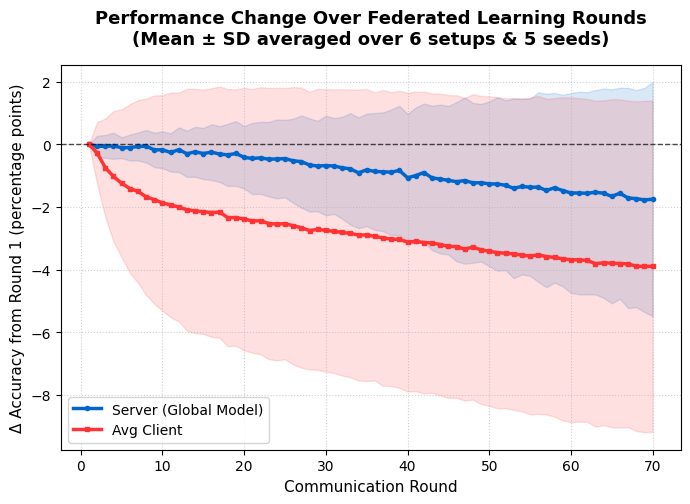

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Ensure Arial font configurations are applied
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# List of setups to aggregate
runs_keys = [
    ("feddf_iid_acc",      "client_feddf_iid_acc_hist"),
    ("feddf_mod_acc",      "client_feddf_mod_acc_hist"),
    ("feddf_strong_acc",   "client_feddf_strong_acc_hist"),
    ("bifeddf_iid_acc",    "client_bifeddf_iid_acc_hist"),
    ("bifeddf_mod_acc",    "client_bifeddf_mod_acc_hist"),
    ("bifeddf_strong_acc", "client_bifeddf_strong_acc_hist"),
]

# We will store the delta trajectories for each run setup and each seed
all_server_deltas = []  # To hold arrays of shape (5, FED_ROUNDS) for each of the 6 configs
all_client_deltas = []  # To hold arrays of shape (5, FED_ROUNDS) for each of the 6 configs

for server_key, client_key in runs_keys:
    # --- 1. Server Delta calculation ---
    server_hist = np.array(aggregated[server_key])  # shape: (5 seeds, FED_ROUNDS)
    # Subtract Round 0 (index 0) from all rounds for each seed individually
    server_delta = server_hist - server_hist[:, 0:1]
    all_server_deltas.append(server_delta)
    
    # --- 2. Client Delta calculation ---
    client_hist_dict = aggregated[client_key]
    client_data = []
    for c_id in sorted(client_hist_dict.keys(), key=lambda k: int(k)):
        client_data.append(client_hist_dict[c_id])
    # shape: (num_clients, 5 seeds, FED_ROUNDS)
    client_arr = np.array(client_data)
    
    # Average across clients to get mean client trajectory per seed
    seed_client_means = client_arr.mean(axis=0)  # shape: (5 seeds, FED_ROUNDS)
    # Subtract Round 0 (index 0) from all rounds for each seed individually
    client_delta = seed_client_means - seed_client_means[:, 0:1]
    all_client_deltas.append(client_delta)

# Stack trajectories across all configs and seeds to get overall statistics
# Shape: (6 configs * 5 seeds, FED_ROUNDS) -> (30, FED_ROUNDS)
server_flat = np.vstack(all_server_deltas)
client_flat = np.vstack(all_client_deltas)

mean_server_delta = server_flat.mean(axis=0)
std_server_delta = server_flat.std(axis=0)

mean_client_delta = client_flat.mean(axis=0)
std_client_delta = client_flat.std(axis=0)

rounds = np.arange(1, len(mean_server_delta) + 1)

# Create the figure
fig, ax = plt.subplots(figsize=(8, 5))

# Plot Server line & SD band
ax.plot(rounds, mean_server_delta, label="Server (Global Model)", 
        color="#0066CC", linestyle="-", linewidth=2.5, marker="o", markersize=3)
ax.fill_between(rounds, mean_server_delta - std_server_delta, mean_server_delta + std_server_delta, 
                color="#0066CC", alpha=0.15)

# Plot Avg Client line & SD band
ax.plot(rounds, mean_client_delta, label="Avg Client", 
        color="#FF3333", linestyle="-", linewidth=2.5, marker="s", markersize=3)
ax.fill_between(rounds, mean_client_delta - std_client_delta, mean_client_delta + std_client_delta, 
                color="#FF3333", alpha=0.15)

# Styling and reference lines
ax.axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.7)

ax.set_title("Performance Change Over Federated Learning Rounds\n(Mean ± SD averaged over 6 setups & 5 seeds)", 
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Communication Round", fontsize=11)
ax.set_ylabel("Δ Accuracy from Round 1 (percentage points)", fontsize=11)

ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower left", fontsize=10, frameon=True, shadow=False)

# Make the y-axis formatting read clearly with signs
import matplotlib.ticker as mticker
ax.yaxis.set_major_formatter(mticker.PercentFormatter(symbol="pp", is_latex_string=False))

plt.tight_layout()

# Save the visualization
save_path = os.path.join(SAVE_DIR, "performance_degradation_rounds.png")
plt.savefig(save_path, dpi=300)
print(f"Degradation plot successfully saved to: {save_path}")
plt.show()

In [27]:

loaded_runs = {
    "feddf_basic": {
        "iid": {},
        "moderatedirichlet": {},
        "strongdirichlet": {}
    },
    "feddf_bidir": {
        "iid": {},
        "moderatedirichlet": {},
        "strongdirichlet": {}
    }
}

seeds = [100, 200, 300, 400, 500]


for run_prefix in loaded_runs.keys():
    for loader_base in loaded_runs[run_prefix].keys():
        print(f"Loading: {run_prefix} | Dataset: {loader_base}")
        for seed in seeds:
            loader_name_with_seed = f"{loader_base}_{seed}"
            
            g_model, c_models, hist, comm_hist, c_acc_hist = load_saved_models_and_histories(
                run_prefix=run_prefix,
                loader_name=loader_name_with_seed,
                n_clients=TOTAL_CLIENTS
            )
            
            loaded_runs[run_prefix][loader_base][seed] = {
                "global_model": g_model,
                "client_models": c_models,
                "history": hist,
                "comm_history": comm_hist,
                "client_acc_history": c_acc_hist
            }
        print("-" * 50)

print("\n" + "="*70)
print("All 30 setup iterations (6 configurations x 5 seeds) successfully loaded into 'loaded_runs'!")

Loading: feddf_basic | Dataset: iid
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
--------------------------------------------------
Loading: feddf_basic | Dataset: moderatedirichlet
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
--------------------------------------------------
Loading: feddf_basic | Dataset: strongdirichlet
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
--------------------------------------------------
Loading: feddf_bidir | Dataset: iid
Models and histories loaded successfully.
Model

Calculating pairwise client prediction agreement across all setups and seeds...
Processing: FedDF IID...
Processing: FedDF Mod Dirichlet...
Processing: FedDF Strong Dirichlet...
Processing: BiFedDF IID...
Processing: BiFedDF Mod Dirichlet...
Processing: BiFedDF Strong Dirichlet...

All calculations completed! Plotting heatmaps...
Heatmap grid successfully saved to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/pairwise_client_prediction_agreement.png


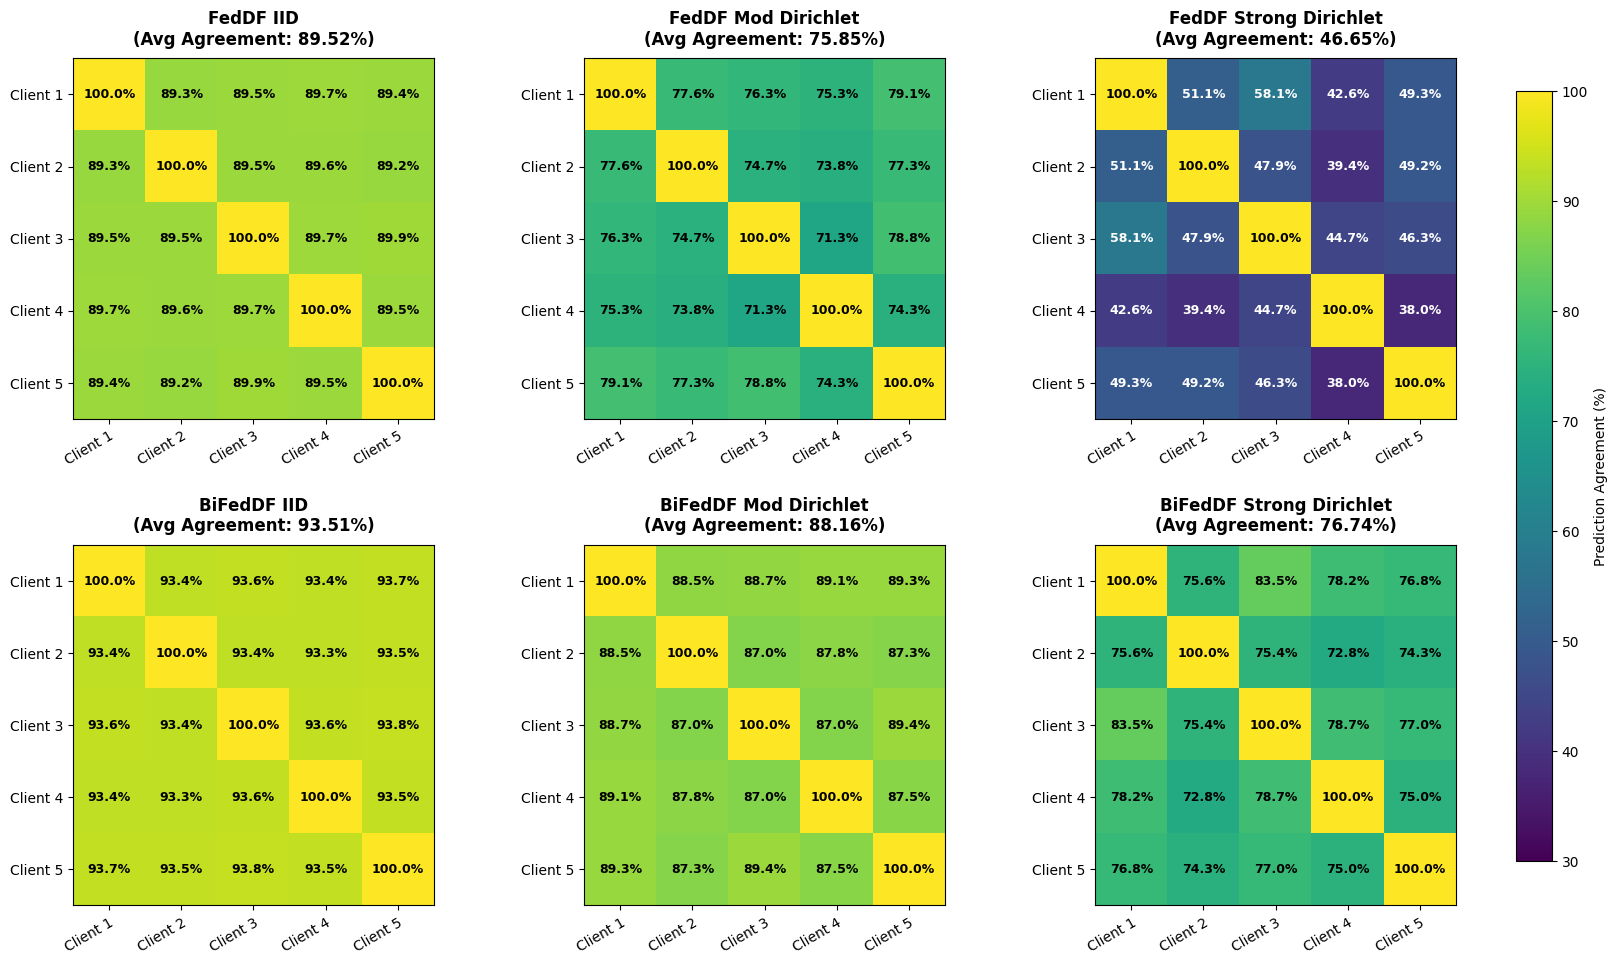

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

# Ensure Arial font configurations are applied
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Configurations list matching your runs
runs_config = [
    ("FedDF IID",              "feddf_basic", "iid"),
    ("FedDF Mod Dirichlet",      "feddf_basic", "moderatedirichlet"),
    ("FedDF Strong Dirichlet",   "feddf_basic", "strongdirichlet"),
    ("BiFedDF IID",             "feddf_bidir", "iid"),
    ("BiFedDF Mod Dirichlet",     "feddf_bidir", "moderatedirichlet"),
    ("BiFedDF Strong Dirichlet",  "feddf_bidir", "strongdirichlet")
]

seeds = [100, 200, 300, 400, 500]
n_clients = 5

# Dictionary to hold the 5-seed averaged 5x5 agreement matrix for each of the 6 setups
averaged_agreement_matrices = {}

print("Calculating pairwise client prediction agreement across all setups and seeds...")

for display_name, run_prefix, loader_base in runs_config:
    print(f"Processing: {display_name}...")
    setup_matrices = []
    
    for seed in seeds:
        # Retrieve the pre-loaded client models for this seed setup
        client_models = loaded_runs[run_prefix][loader_base][seed]["client_models"]
        
        # Ensure all models are in eval mode
        for m in client_models:
            m.eval()
            
        # Collect predictions on the test loader
        all_preds = {i: [] for i in range(n_clients)}
        with torch.no_grad():
            for inputs, _ in test_loader:
                inputs = inputs.to(device)
                for i, model in enumerate(client_models):
                    logits = model(inputs)
                    preds = logits.argmax(dim=1)
                    all_preds[i].extend(preds.cpu().numpy())
                    
        # Compute the 5x5 pairwise agreement matrix for this seed
        agreement_matrix = np.zeros((n_clients, n_clients))
        for i in range(n_clients):
            for j in range(n_clients):
                if i == j:
                    agreement_matrix[i, j] = 100.0
                else:
                    preds_i = np.array(all_preds[i])
                    preds_j = np.array(all_preds[j])
                    agreement_matrix[i, j] = np.mean(preds_i == preds_j) * 100.0
                    
        setup_matrices.append(agreement_matrix)
        
    # Average the matrices across the 5 seeds
    averaged_agreement_matrices[display_name] = np.mean(setup_matrices, axis=0)

print("\nAll calculations completed! Plotting heatmaps...")

# Plotting the 2x3 grid of heatmaps
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

client_labels = [f"Client {i+1}" for i in range(n_clients)]

for idx, (display_name, _, _) in enumerate(runs_config):
    ax = axes[idx]
    matrix = averaged_agreement_matrices[display_name]
    
    # Draw the heatmap using imshow
    # We use 'plasma' cmap so diversity is highly visible, or 'viridis' to match your heatmaps
    im = ax.imshow(matrix, cmap='viridis', vmin=30, vmax=100)
    
    # Set tick labels
    ax.set_xticks(np.arange(n_clients))
    ax.set_yticks(np.arange(n_clients))
    ax.set_xticklabels(client_labels, fontsize=10)
    ax.set_yticklabels(client_labels, fontsize=10)
    
    # Rotate tick labels for readability
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
    
    # Annotate each cell with its percentage value
    for i in range(n_clients):
        for j in range(n_clients):
            val = matrix[i, j]
            # Adjust text color for contrast based on background intensity
            text_color = "white" if val < 65 else "black"
            ax.text(j, i, f"{val:.1f}%", ha="center", va="center", color=text_color, fontsize=9, fontweight='bold')
            
    # Compute and display average cross-agreement (excluding diagonal self-agreement)
    off_diag_mask = ~np.eye(n_clients, dtype=bool)
    avg_cross_agreement = matrix[off_diag_mask].mean()
    
    ax.set_title(f"{display_name}\n(Avg Agreement: {avg_cross_agreement:.2f}%)", fontsize=12, fontweight='bold', pad=10)

# Add a colorbar on the right side of the figure
cbar_ax = fig.add_axes([0.94, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Prediction Agreement (%)")

plt.subplots_adjust(right=0.92, hspace=0.35, wspace=0.25)

# Save the visualization to your SAVE_DIR
save_path = os.path.join(SAVE_DIR, "pairwise_client_prediction_agreement.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Heatmap grid successfully saved to: {save_path}")
plt.show()

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_pairwise_client_prediction_agreement.png


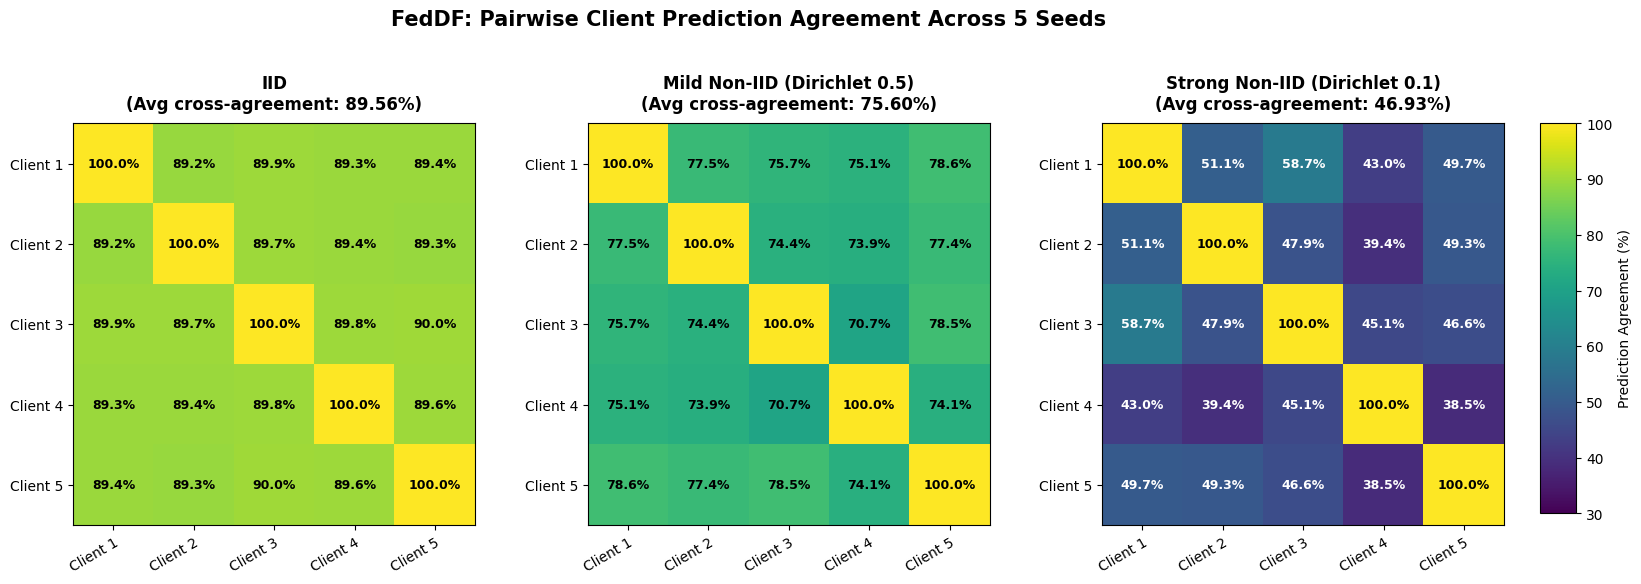

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_pairwise_client_prediction_agreement.png


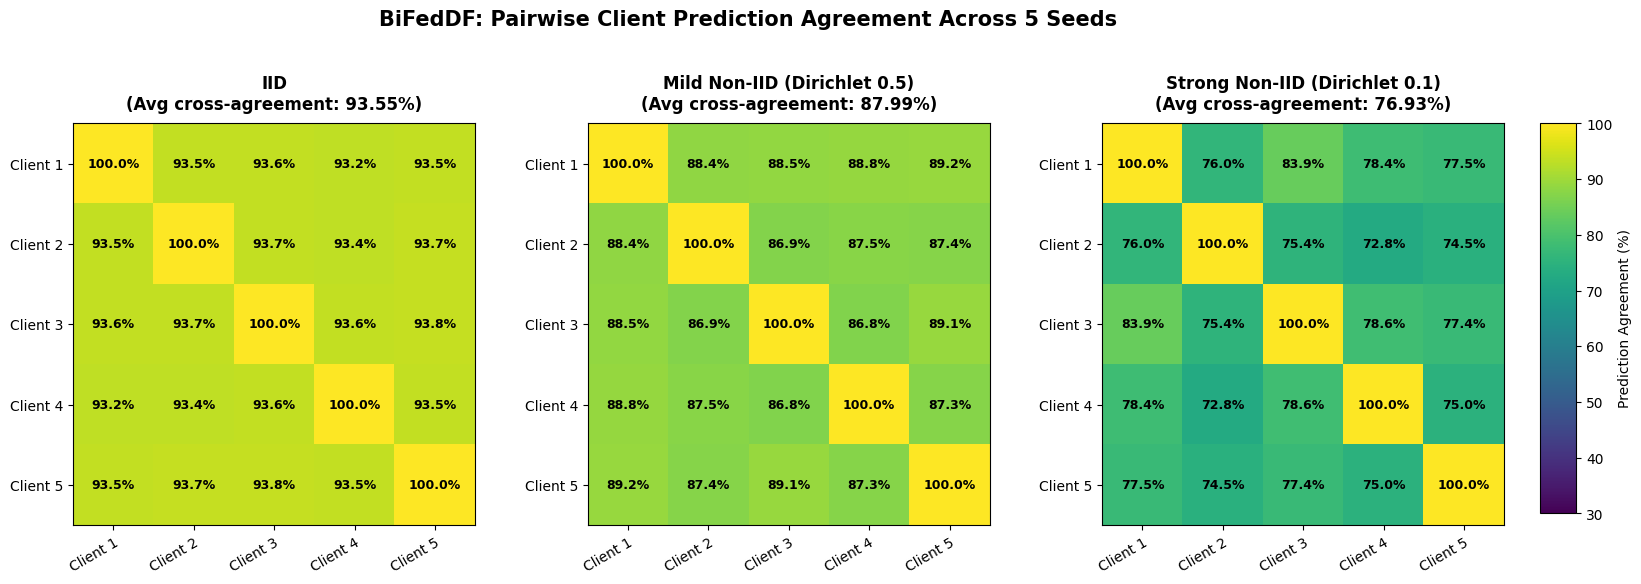

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
from torch.utils.data import DataLoader

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

seeds = [100, 200, 300, 400, 500]
n_clients = 5
client_labels = [f"Client {i+1}" for i in range(n_clients)]

# Fresh single-worker eval loader to avoid multiprocessing crashes
eval_loader = DataLoader(
    eval_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

split_configs = [
    ("IID", "iid"),
    ("Mild Non-IID (Dirichlet 0.5)", "moderatedirichlet"),
    ("Strong Non-IID (Dirichlet 0.1)", "strongdirichlet"),
]

def compute_pairwise_agreement_matrix(client_models, loader, device=device):
    for m in client_models:
        m.eval()

    all_preds = {i: [] for i in range(len(client_models))}

    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            for i, model in enumerate(client_models):
                logits = model(inputs)
                preds = logits.argmax(dim=1)
                all_preds[i].extend(preds.cpu().numpy())

    agreement_matrix = np.zeros((len(client_models), len(client_models)), dtype=float)

    for i in range(len(client_models)):
        for j in range(len(client_models)):
            if i == j:
                agreement_matrix[i, j] = 100.0
            else:
                preds_i = np.array(all_preds[i])
                preds_j = np.array(all_preds[j])
                agreement_matrix[i, j] = np.mean(preds_i == preds_j) * 100.0

    return agreement_matrix

def plot_family_agreement_figure(family_name, run_prefix, cmap='viridis'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(
        f"{family_name}: Pairwise Client Prediction Agreement Across 5 Seeds",
        fontsize=15,
        fontweight='bold',
        y=1.02
    )

    for ax, (split_label, loader_base) in zip(axes, split_configs):
        seed_matrices = []

        for seed in seeds:
            client_models = loaded_runs[run_prefix][loader_base][seed]["client_models"]
            matrix = compute_pairwise_agreement_matrix(client_models, eval_loader, device=device)
            seed_matrices.append(matrix)

        avg_matrix = np.mean(seed_matrices, axis=0)

        im = ax.imshow(avg_matrix, cmap=cmap, vmin=30, vmax=100)
        ax.set_title(split_label, fontsize=12, fontweight='bold', pad=10)
        ax.set_xticks(np.arange(n_clients))
        ax.set_yticks(np.arange(n_clients))
        ax.set_xticklabels(client_labels, fontsize=10)
        ax.set_yticklabels(client_labels, fontsize=10)
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

        for i in range(n_clients):
            for j in range(n_clients):
                val = avg_matrix[i, j]
                text_color = "white" if val < 65 else "black"
                ax.text(
                    j, i, f"{val:.1f}%",
                    ha="center", va="center",
                    color=text_color, fontsize=9, fontweight='bold'
                )

        off_diag_mask = ~np.eye(n_clients, dtype=bool)
        avg_cross_agreement = avg_matrix[off_diag_mask].mean()
        ax.set_title(
            f"{split_label}\n(Avg cross-agreement: {avg_cross_agreement:.2f}%)",
            fontsize=12, fontweight='bold', pad=10
        )

    cbar_ax = fig.add_axes([0.94, 0.18, 0.02, 0.65])
    fig.colorbar(im, cax=cbar_ax, label="Prediction Agreement (%)")

    plt.subplots_adjust(right=0.92, wspace=0.28)

    save_path = os.path.join(SAVE_DIR, f"{family_name.lower()}_pairwise_client_prediction_agreement.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

plot_family_agreement_figure("FedDF", "feddf_basic", cmap='viridis')
plot_family_agreement_figure("BiFedDF", "feddf_bidir", cmap='viridis')

Computing ensemble gains across 5 seeds for all configurations...
-> FedDF IID: Mean Gain = +1.53% (± 0.50%)
-> FedDF Mod Dirichlet: Mean Gain = +7.03% (± 1.39%)
-> FedDF Strong Dirichlet: Mean Gain = +22.45% (± 6.45%)
-> BiFedDF IID: Mean Gain = +0.71% (± 0.12%)
-> BiFedDF Mod Dirichlet: Mean Gain = +1.89% (± 0.16%)
-> BiFedDF Strong Dirichlet: Mean Gain = +5.70% (± 2.00%)

Ensemble gain plot successfully saved to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/ensemble_gain_comparison.png


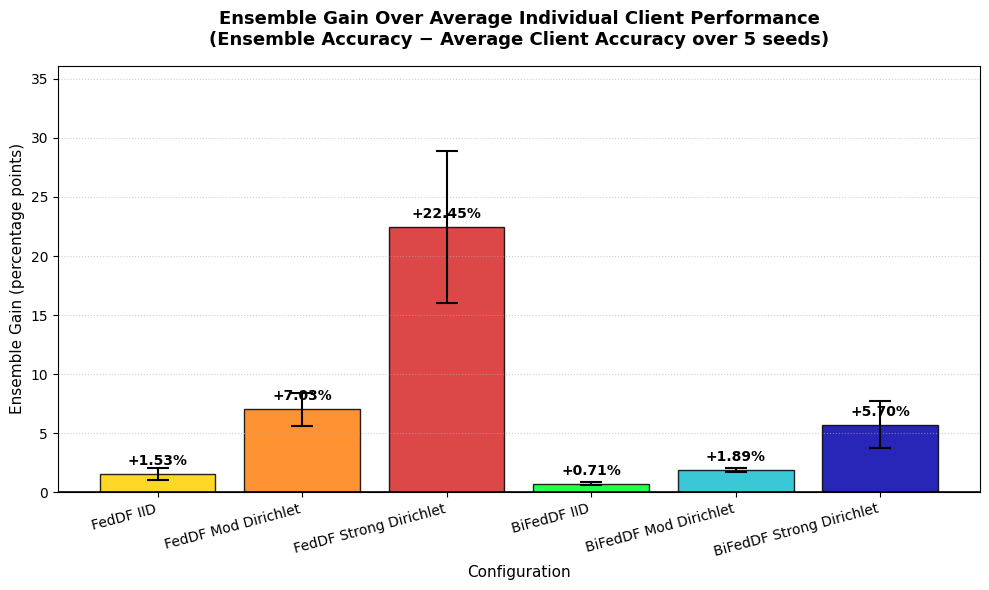

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

# Ensure Arial font configurations are applied
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Helper function to compute test accuracy of an ensemble of models on the test loader
def compute_ensemble_accuracy(client_models, loader, device):
    for m in client_models:
        m.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            # Sum logits across all client models
            ensemble_logits = torch.zeros((inputs.size(0), 10), device=device)
            for model in client_models:
                ensemble_logits += model(inputs)
            
            _, predicted = torch.max(ensemble_logits, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

# Run configurations matching your experiments
runs_config = [
    ("FedDF IID",              "feddf_basic", "iid",             "#FFD000"),
    ("FedDF Mod Dirichlet",      "feddf_basic", "moderatedirichlet", "tab:orange"),
    ("FedDF Strong Dirichlet",   "feddf_basic", "strongdirichlet",   "tab:red"),
    ("BiFedDF IID",             "feddf_bidir", "iid",             "#00FE31"),
    ("BiFedDF Mod Dirichlet",     "feddf_bidir", "moderatedirichlet", "tab:cyan"),
    ("BiFedDF Strong Dirichlet",  "feddf_bidir", "strongdirichlet",   "#0200AA")
]

seeds = [100, 200, 300, 400, 500]

mean_gains = []
std_gains = []
display_names = []
colors = []

print("Computing ensemble gains across 5 seeds for all configurations...")

for display_name, run_prefix, loader_base, color in runs_config:
    gains = []
    for seed in seeds:
        client_models = loaded_runs[run_prefix][loader_base][seed]["client_models"]
        
        # 1. Compute Ensemble Accuracy
        ens_acc = compute_ensemble_accuracy(client_models, test_loader, device)
        
        # 2. Compute average accuracy of individual clients
        indiv_accs = [evaluate(m, test_loader, device) for m in client_models]
        avg_indiv_acc = np.mean(indiv_accs)
        
        # 3. Calculate Gain
        gain = ens_acc - avg_indiv_acc
        gains.append(gain)
        
    mean_gain = np.mean(gains)
    std_gain = np.std(gains)
    
    mean_gains.append(mean_gain)
    std_gains.append(std_gain)
    display_names.append(display_name)
    colors.append(color)
    
    print(f"-> {display_name}: Mean Gain = +{mean_gain:.2f}% (± {std_gain:.2f}%)")

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Plot bars with standard deviation error bars
bars = ax.bar(display_names, mean_gains, yerr=std_gains, color=colors, edgecolor='black', alpha=0.85, 
              capsize=8, error_kw=dict(lw=1.5, capthick=1.5, ecolor='black'))

# Add value labels on top of the bars
for bar in bars:
    height = bar.get_height()
    label_y = height + 0.15 if height >= 0 else height - 0.5
    ax.annotate(f'+{height:.2f}%' if height >= 0 else f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, label_y),
                xytext=(0, 3 if height >= 0 else -12),  # vertical offsets
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Style plot
ax.axhline(0, color='black', linewidth=1.2)
ax.set_title("Ensemble Gain Over Average Individual Client Performance\n(Ensemble Accuracy − Average Client Accuracy over 5 seeds)", 
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Ensemble Gain (percentage points)", fontsize=11)
ax.set_xlabel("Configuration", fontsize=11)
plt.xticks(rotation=15, ha='right')
ax.grid(axis='y', linestyle=':', alpha=0.6)

# Set dynamic axis limits with headroom
max_val = max(np.array(mean_gains) + np.array(std_gains))
ax.set_ylim(0, max(max_val * 1.25, 2.0))

plt.tight_layout()

# Save the visualization to SAVE_DIR
save_path = os.path.join(SAVE_DIR, "ensemble_gain_comparison.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"\nEnsemble gain plot successfully saved to: {save_path}")
plt.show()

In [29]:

seeds = [100, 200, 300, 400, 500]
results_by_seed = {}
for seed in seeds:
    results_by_seed[seed] = {
        "feddf_iid_acc": loaded_runs["feddf_basic"]["iid"][seed]["history"],
        "feddf_mod_acc": loaded_runs["feddf_basic"]["moderatedirichlet"][seed]["history"],
        "feddf_strong_acc": loaded_runs["feddf_basic"]["strongdirichlet"][seed]["history"],
        "bifeddf_iid_acc": loaded_runs["feddf_bidir"]["iid"][seed]["history"],
        "bifeddf_mod_acc": loaded_runs["feddf_bidir"]["moderatedirichlet"][seed]["history"],
        "bifeddf_strong_acc": loaded_runs["feddf_bidir"]["strongdirichlet"][seed]["history"],
        "client_feddf_iid_acc_hist": loaded_runs["feddf_basic"]["iid"][seed]["client_acc_history"],
        "client_feddf_mod_acc_hist": loaded_runs["feddf_basic"]["moderatedirichlet"][seed]["client_acc_history"],
        "client_feddf_strong_acc_hist": loaded_runs["feddf_basic"]["strongdirichlet"][seed]["client_acc_history"],
        "client_bifeddf_iid_acc_hist": loaded_runs["feddf_bidir"]["iid"][seed]["client_acc_history"],
        "client_bifeddf_mod_acc_hist": loaded_runs["feddf_bidir"]["moderatedirichlet"][seed]["client_acc_history"],
        "client_bifeddf_strong_acc_hist": loaded_runs["feddf_bidir"]["strongdirichlet"][seed]["client_acc_history"],
    }

results_100 = results_by_seed[100]
results_200 = results_by_seed[200]
results_300 = results_by_seed[300]
results_400 = results_by_seed[400]
results_500 = results_by_seed[500]

print("Successfully mapped 'loaded_runs' data to variables:")
print("-> results_100, results_200, results_300, results_400, and results_500 are populated and ready!")

Successfully mapped 'loaded_runs' data to variables:
-> results_100, results_200, results_300, results_400, and results_500 are populated and ready!


Computing final degradation at Round 70 vs Round 1 across 5 seeds...
Degradation comparison plot saved to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/final_degradation_comparison.png


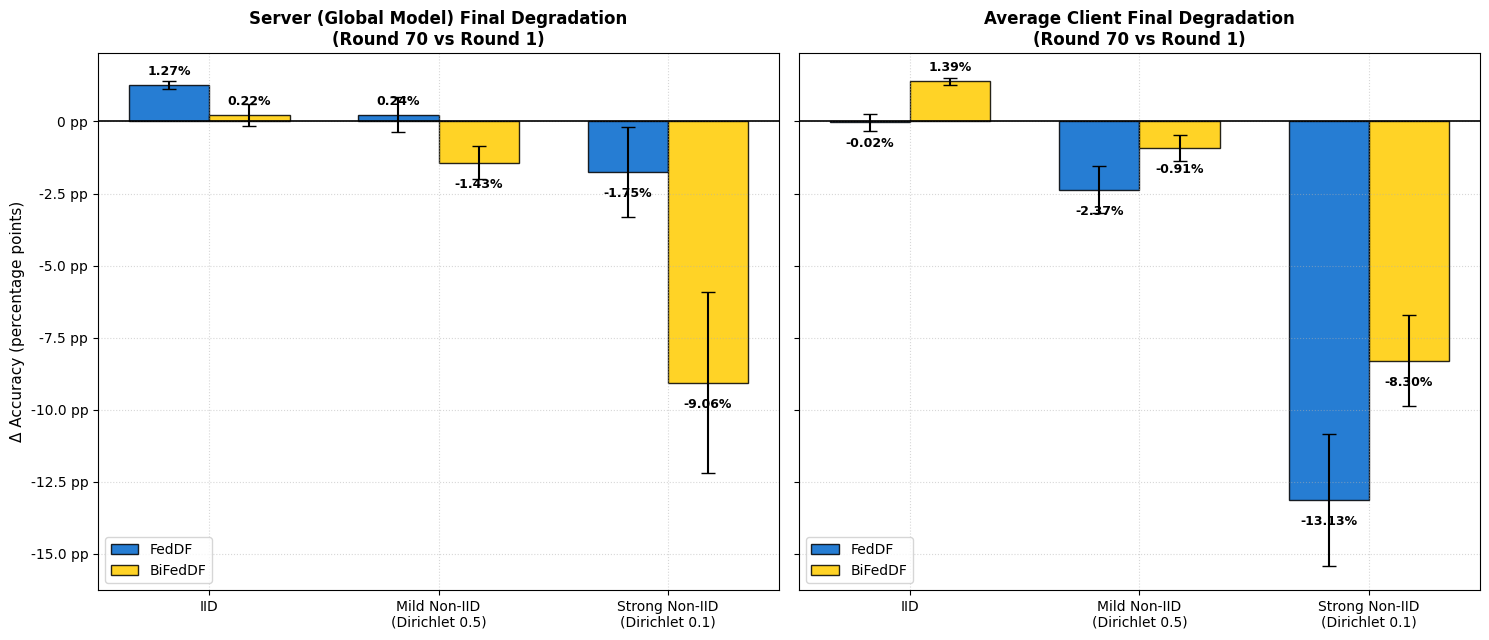

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Ensure Arial font configurations are applied
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Configurations and seeds
seeds = [100, 200, 300, 400, 500]
distributions = ["iid", "moderatedirichlet", "strongdirichlet"]
display_dist = ["IID", "Mild Non-IID\n(Dirichlet 0.5)", "Strong Non-IID\n(Dirichlet 0.1)"]

# Dictionary to hold the raw degradation drops for each seed run
drops = {
    "FedDF": {
        "iid": {"server": [], "client": []},
        "moderatedirichlet": {"server": [], "client": []},
        "strongdirichlet": {"server": [], "client": []}
    },
    "BiFedDF": {
        "iid": {"server": [], "client": []},
        "moderatedirichlet": {"server": [], "client": []},
        "strongdirichlet": {"server": [], "client": []}
    }
}

print("Computing final degradation at Round 70 vs Round 1 across 5 seeds...")

for dist in distributions:
    # 1. FedDF Basic
    for seed in seeds:
        # Server Drop (Final Round - First Round)
        s_hist = loaded_runs["feddf_basic"][dist][seed]["history"]
        s_drop = s_hist[-1] - s_hist[0]
        drops["FedDF"][dist]["server"].append(s_drop)
        
        # Avg Client Drop (Final Round - First Round)
        client_hist_dict = loaded_runs["feddf_basic"][dist][seed]["client_acc_history"]
        c_accs = [client_hist_dict[c_id] for c_id in sorted(client_hist_dict.keys(), key=lambda k: int(k))]
        mean_c_hist = np.mean(c_accs, axis=0)
        c_drop = mean_c_hist[-1] - mean_c_hist[0]
        drops["FedDF"][dist]["client"].append(c_drop)

    # 2. BiFedDF Bidirectional
    for seed in seeds:
        # Server Drop (Final Round - First Round)
        s_hist = loaded_runs["feddf_bidir"][dist][seed]["history"]
        s_drop = s_hist[-1] - s_hist[0]
        drops["BiFedDF"][dist]["server"].append(s_drop)
        
        # Avg Client Drop (Final Round - First Round)
        client_hist_dict = loaded_runs["feddf_bidir"][dist][seed]["client_acc_history"]
        c_accs = [client_hist_dict[c_id] for c_id in sorted(client_hist_dict.keys(), key=lambda k: int(k))]
        mean_c_hist = np.mean(c_accs, axis=0)
        c_drop = mean_c_hist[-1] - mean_c_hist[0]
        drops["BiFedDF"][dist]["client"].append(c_drop)

# Compute Means and SDs for plotting
feddf_server_means = [np.mean(drops["FedDF"][d]["server"]) for d in distributions]
feddf_server_stds  = [np.std(drops["FedDF"][d]["server"]) for d in distributions]
feddf_client_means = [np.mean(drops["FedDF"][d]["client"]) for d in distributions]
feddf_client_stds  = [np.std(drops["FedDF"][d]["client"]) for d in distributions]

bifeddf_server_means = [np.mean(drops["BiFedDF"][d]["server"]) for d in distributions]
bifeddf_server_stds  = [np.std(drops["BiFedDF"][d]["server"]) for d in distributions]
bifeddf_client_means = [np.mean(drops["BiFedDF"][d]["client"]) for d in distributions]
bifeddf_client_stds  = [np.std(drops["BiFedDF"][d]["client"]) for d in distributions]

# Plotting
x = np.arange(len(distributions))
width = 0.35  # width of the bars

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)

# Helper to add value labels above/below downwards bars
def label_bars(rects, ax):
    for rect in rects:
        height = rect.get_height()
        # Since drops are negative, height is negative; label goes below the bar
        label_y = height - 0.4 if height < 0 else height + 0.1
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, label_y),
                    xytext=(0, -12 if height < 0 else 3),  # vertical offsets
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- Subplot 1: Server (Global) Accuracy Degradation ---
rects1_s = ax1.bar(x - width/2, feddf_server_means, width, yerr=feddf_server_stds,
                   label='FedDF', color='#0066CC', edgecolor='black', alpha=0.85, capsize=5)
rects2_s = ax1.bar(x + width/2, bifeddf_server_means, width, yerr=bifeddf_server_stds,
                   label='BiFedDF', color='#FFCC00', edgecolor='black', alpha=0.85, capsize=5)

ax1.axhline(0, color="black", linewidth=1.2)
ax1.set_title("Server (Global Model) Final Degradation\n(Round 70 vs Round 1)", fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(display_dist, fontsize=10)
ax1.set_ylabel("Δ Accuracy (percentage points)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="lower left", fontsize=10)
label_bars(rects1_s, ax1)
label_bars(rects2_s, ax1)

# --- Subplot 2: Avg Client Accuracy Degradation ---
rects1_c = ax2.bar(x - width/2, feddf_client_means, width, yerr=feddf_client_stds,
                   label='FedDF', color='#0066CC', edgecolor='black', alpha=0.85, capsize=5)
rects2_c = ax2.bar(x + width/2, bifeddf_client_means, width, yerr=bifeddf_client_stds,
                   label='BiFedDF', color='#FFCC00', edgecolor='black', alpha=0.85, capsize=5)

ax2.axhline(0, color="black", linewidth=1.2)
ax2.set_title("Average Client Final Degradation\n(Round 70 vs Round 1)", fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(display_dist, fontsize=10)
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(loc="lower left", fontsize=10)
label_bars(rects1_c, ax2)
label_bars(rects2_c, ax2)

# Global styling and limits
import matplotlib.ticker as mticker
# Robustly format y-axis labels using FuncFormatter
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:+.1f} pp" if y != 0 else "0 pp"))


plt.tight_layout()

# Save final graphic
save_path = os.path.join(SAVE_DIR, "final_degradation_comparison.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Degradation comparison plot saved to: {save_path}")
plt.show()

Calculating per-class accuracy metrics for seed 100...
Heatmap visualization successfully saved to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/seed_100_avg_client_per_class_accuracy.png


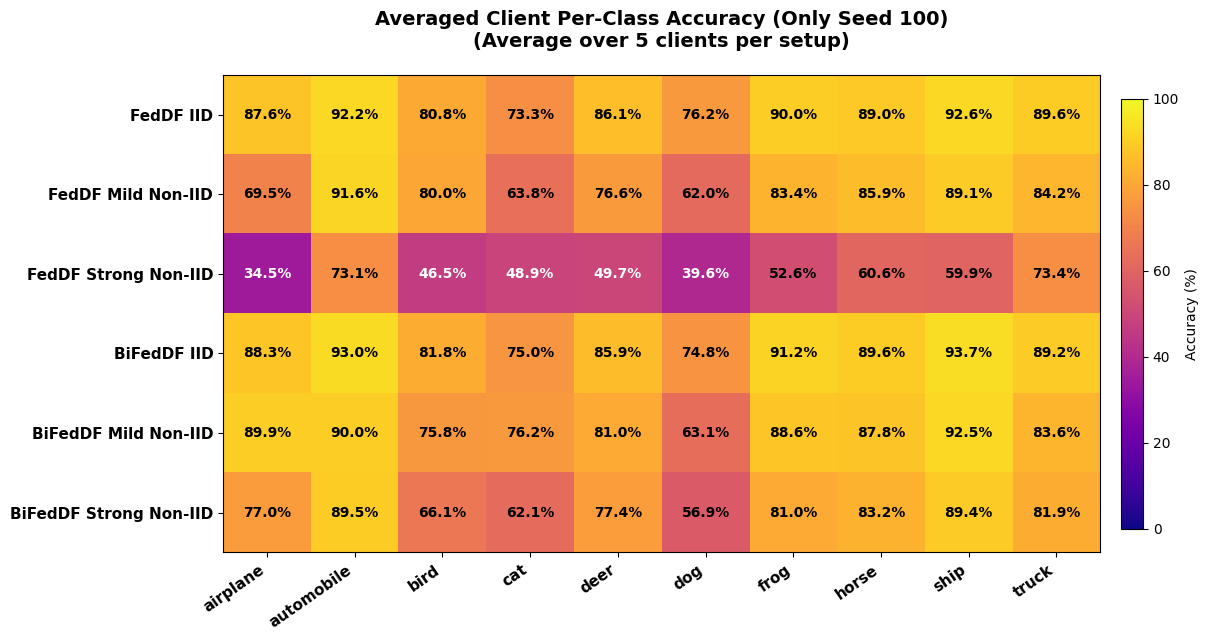

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

# Ensure clean Arial font configuration is applied
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Setups to load
configs = [
    ("FedDF IID",              "feddf_basic", "iid"),
    ("FedDF Mild Non-IID",     "feddf_basic", "moderatedirichlet"),
    ("FedDF Strong Non-IID",   "feddf_basic", "strongdirichlet"),
    ("BiFedDF IID",             "feddf_bidir", "iid"),
    ("BiFedDF Mild Non-IID",     "feddf_bidir", "moderatedirichlet"),
    ("BiFedDF Strong Non-IID",  "feddf_bidir", "strongdirichlet")
]

target_seed = 100
acc_matrix = []
setup_labels = []

print(f"Calculating per-class accuracy metrics for seed {target_seed}...")

for display_name, run_prefix, loader_base in configs:
    # 1. Fetch preloaded client models for seed 100
    client_models = loaded_runs[run_prefix][loader_base][target_seed]["client_models"]
    
    # 2. Compute per-class accuracy for each of the 5 clients on the eval_loader
    client_accs = []
    for m in client_models:
        acc = compute_per_class_accuracy(m, eval_loader, device=device)
        client_accs.append(acc)
        
    # 3. Compute the average client metric for this setup
    avg_client_acc = np.mean(client_accs, axis=0)
    acc_matrix.append(avg_client_acc)
    setup_labels.append(display_name)

acc_matrix = np.array(acc_matrix)  # Shape: (6, 10)

# --- Plot the 6-row unified Heatmap ---
fig, ax = plt.subplots(figsize=(13, 6.5))
im = ax.imshow(acc_matrix, cmap='plasma', aspect='auto', vmin=0, vmax=100)

# Set axes ticks & labels
ax.set_xticks(np.arange(len(class_names)))
ax.set_xticklabels(class_names, rotation=35, ha='right', fontsize=11, fontweight='bold')
ax.set_yticks(np.arange(len(setup_labels)))
ax.set_yticklabels(setup_labels, fontsize=11, fontweight='bold')

# Add cell annotations
for i in range(len(setup_labels)):
    for j in range(len(class_names)):
        val = acc_matrix[i, j]
        # Dynamically change text color for readability based on intensity
        text_color = 'white' if val < 50 else 'black'
        ax.text(j, i, f'{val:.1f}%', ha='center', va='center', color=text_color, fontsize=10, fontweight='bold')

# Colorbar setup
fig.colorbar(im, ax=ax, label='Accuracy (%)', pad=0.02, shrink=0.9)

ax.set_title(f"Averaged Client Per-Class Accuracy (Only Seed {target_seed})\n(Average over 5 clients per setup)", 
             fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# Save final graphic
save_name = f"seed_{target_seed}_avg_client_per_class_accuracy.png"
save_path = os.path.join(SAVE_DIR, save_name)
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Heatmap visualization successfully saved to: {save_path}")

plt.show()

Saved heatmap to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_seed100_avg_client_per_class_table.png


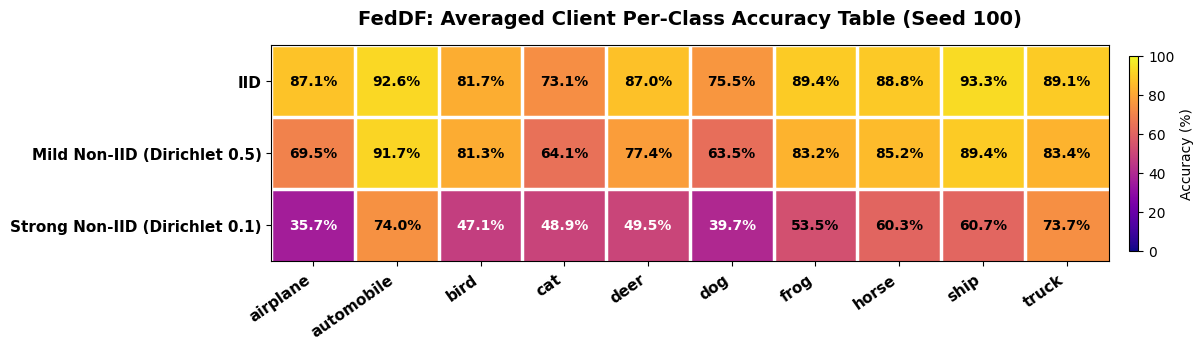

Saved heatmap to: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_seed100_avg_client_per_class_table.png


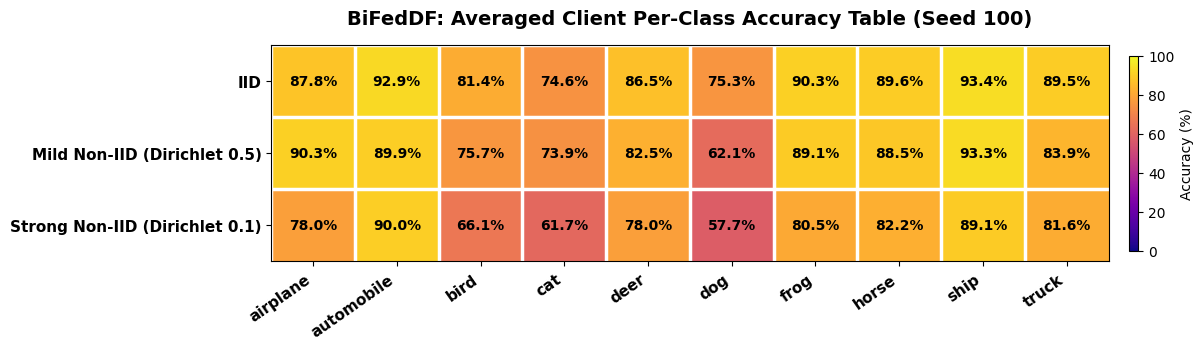

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
from torch.utils.data import DataLoader

# Font configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

target_seed = 100

# Fresh single-worker eval loader to avoid multiprocessing/WSL issues
eval_loader = DataLoader(
    eval_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

def plot_table_heatmap(title, row_labels, data, cmap='plasma', save_name=None):
    fig, ax = plt.subplots(figsize=(13, 3.6))
    im = ax.imshow(data, cmap=cmap, aspect='auto', vmin=0, vmax=100)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)

    ax.set_xticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, rotation=35, ha='right', fontsize=11, fontweight='bold')
    ax.set_yticks(np.arange(len(row_labels)))
    ax.set_yticklabels(row_labels, fontsize=11, fontweight='bold')

    ax.set_xticks(np.arange(len(class_names)) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(row_labels)) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle='-', linewidth=2.5)
    ax.tick_params(which="minor", size=0)

    for i in range(len(row_labels)):
        for j in range(len(class_names)):
            val = data[i, j]
            text_color = 'white' if val < 50 else 'black'
            ax.text(j, i, f'{val:.1f}%', ha='center', va='center', color=text_color, fontsize=10, fontweight='bold')

    fig.colorbar(im, ax=ax, label='Accuracy (%)', pad=0.02, shrink=0.9)
    plt.tight_layout()

    if save_name:
        save_path = os.path.join(SAVE_DIR, save_name)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved heatmap to: {save_path}")

    plt.show()
    plt.close(fig)

def get_seed_100_avg_client_per_class(run_prefix, loader_base, loader):
    entry = loaded_runs[run_prefix][loader_base][target_seed]
    client_models = entry["client_models"]

    client_accs = [compute_per_class_accuracy(m, loader, device) for m in client_models]
    avg_client = np.mean(client_accs, axis=0)

    return avg_client

row_labels = ["IID", "Mild Non-IID (Dirichlet 0.5)", "Strong Non-IID (Dirichlet 0.1)"]

# FedDF: 3 setups
feddf_client_matrix = np.array([
    get_seed_100_avg_client_per_class("feddf_basic", "iid", eval_loader),
    get_seed_100_avg_client_per_class("feddf_basic", "moderatedirichlet", eval_loader),
    get_seed_100_avg_client_per_class("feddf_basic", "strongdirichlet", eval_loader),
])

# BiFedDF: 3 setups
bifeddf_client_matrix = np.array([
    get_seed_100_avg_client_per_class("feddf_bidir", "iid", eval_loader),
    get_seed_100_avg_client_per_class("feddf_bidir", "moderatedirichlet", eval_loader),
    get_seed_100_avg_client_per_class("feddf_bidir", "strongdirichlet", eval_loader),
])

plot_table_heatmap(
    f"FedDF: Averaged Client Per-Class Accuracy Table (Seed {target_seed})",
    row_labels,
    feddf_client_matrix,
    cmap='plasma',
    save_name=f"feddf_seed{target_seed}_avg_client_per_class_table.png"
)

plot_table_heatmap(
    f"BiFedDF: Averaged Client Per-Class Accuracy Table (Seed {target_seed})",
    row_labels,
    bifeddf_client_matrix,
    cmap='plasma',
    save_name=f"bifeddf_seed{target_seed}_avg_client_per_class_table.png"
)

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_seed100_avg_server_per_class_accuracy_group.png


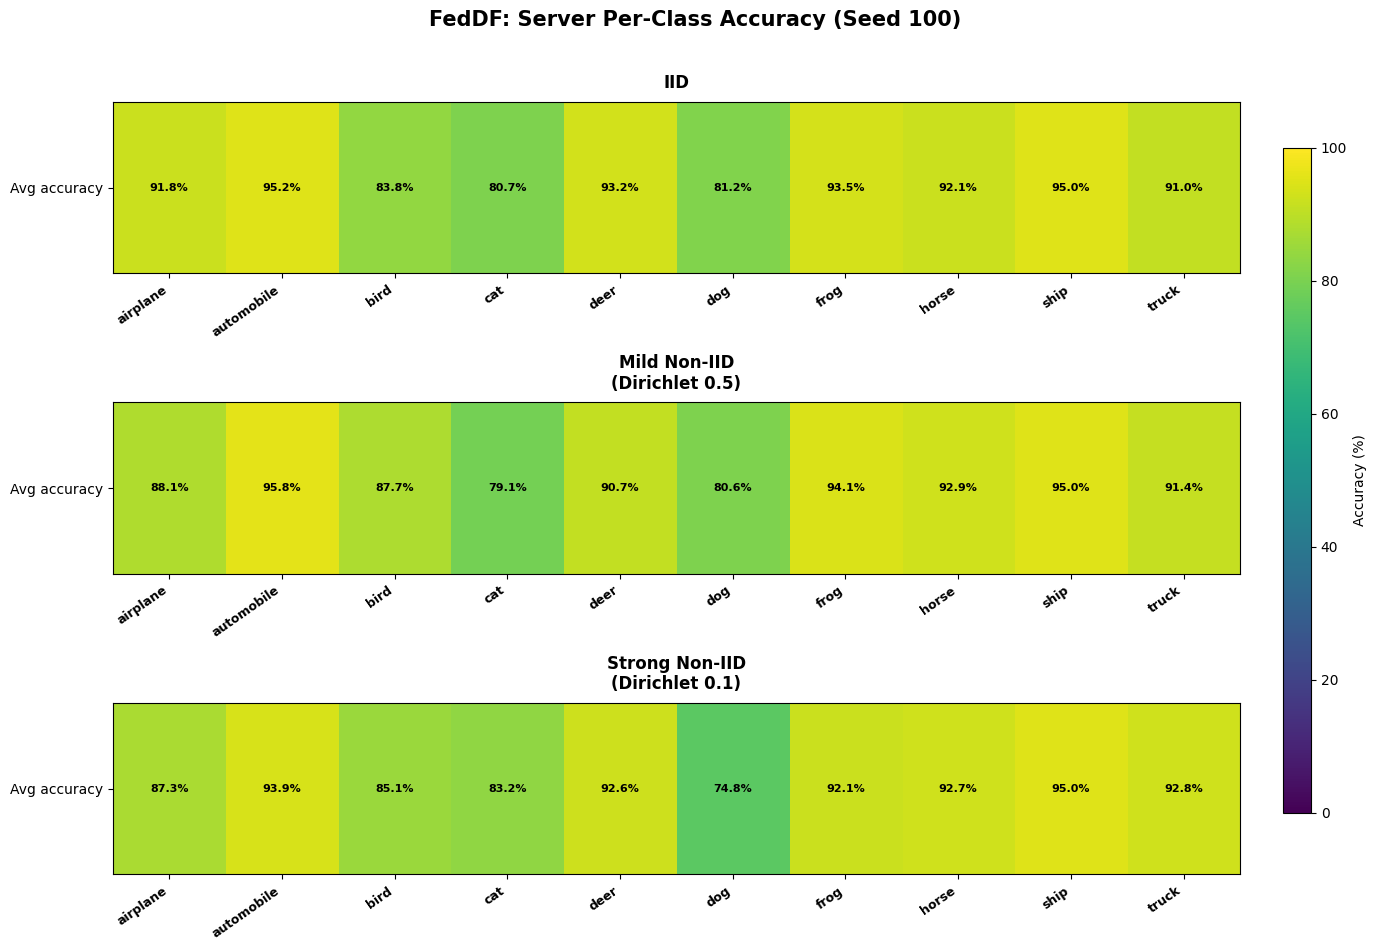

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/feddf_seed100_avg_client_per_class_accuracy_group.png


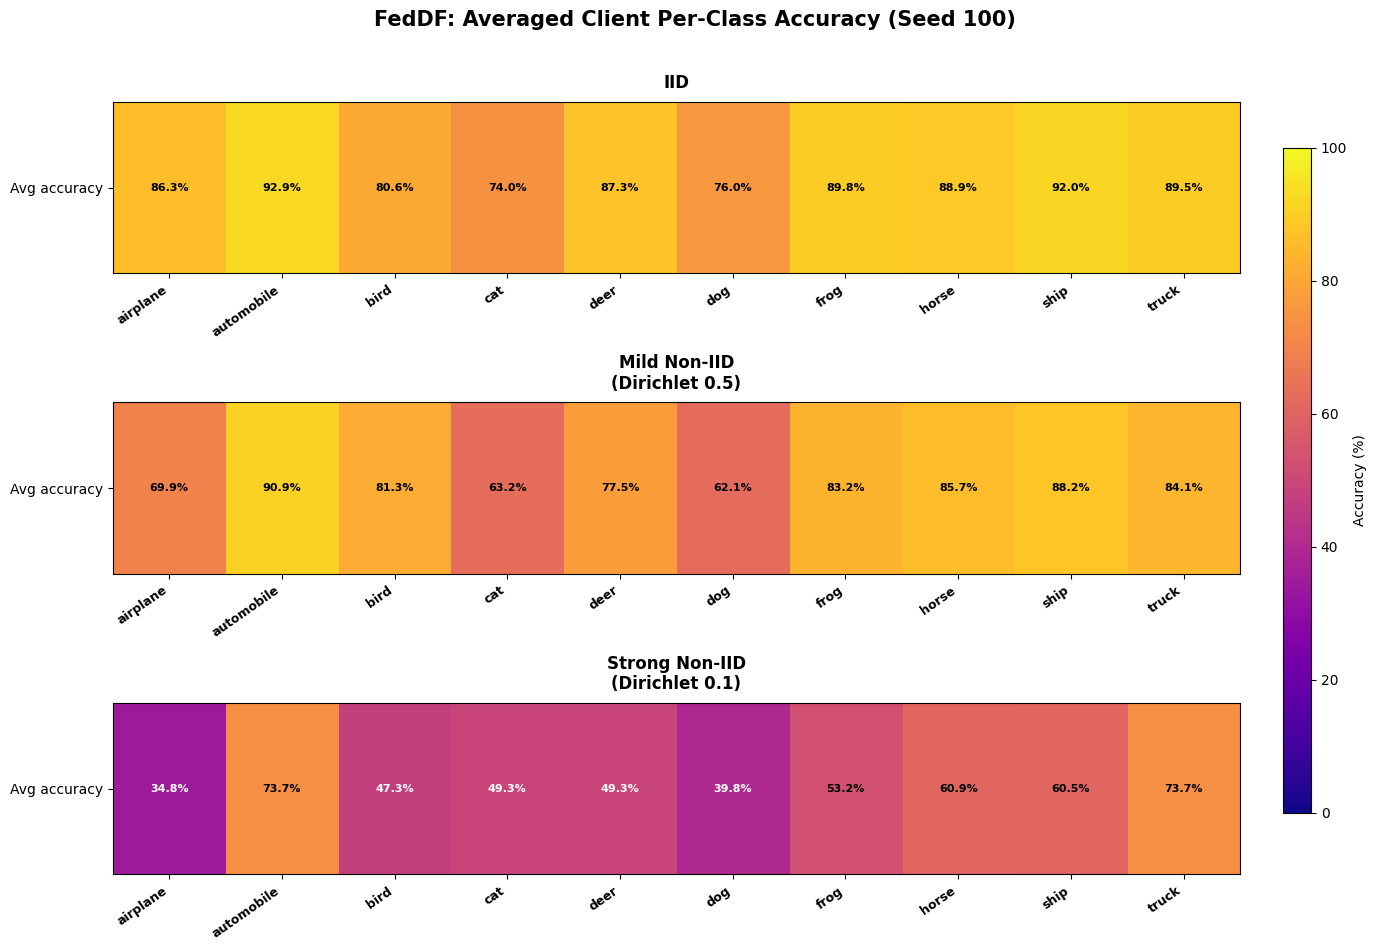

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_seed100_avg_server_per_class_accuracy_group.png


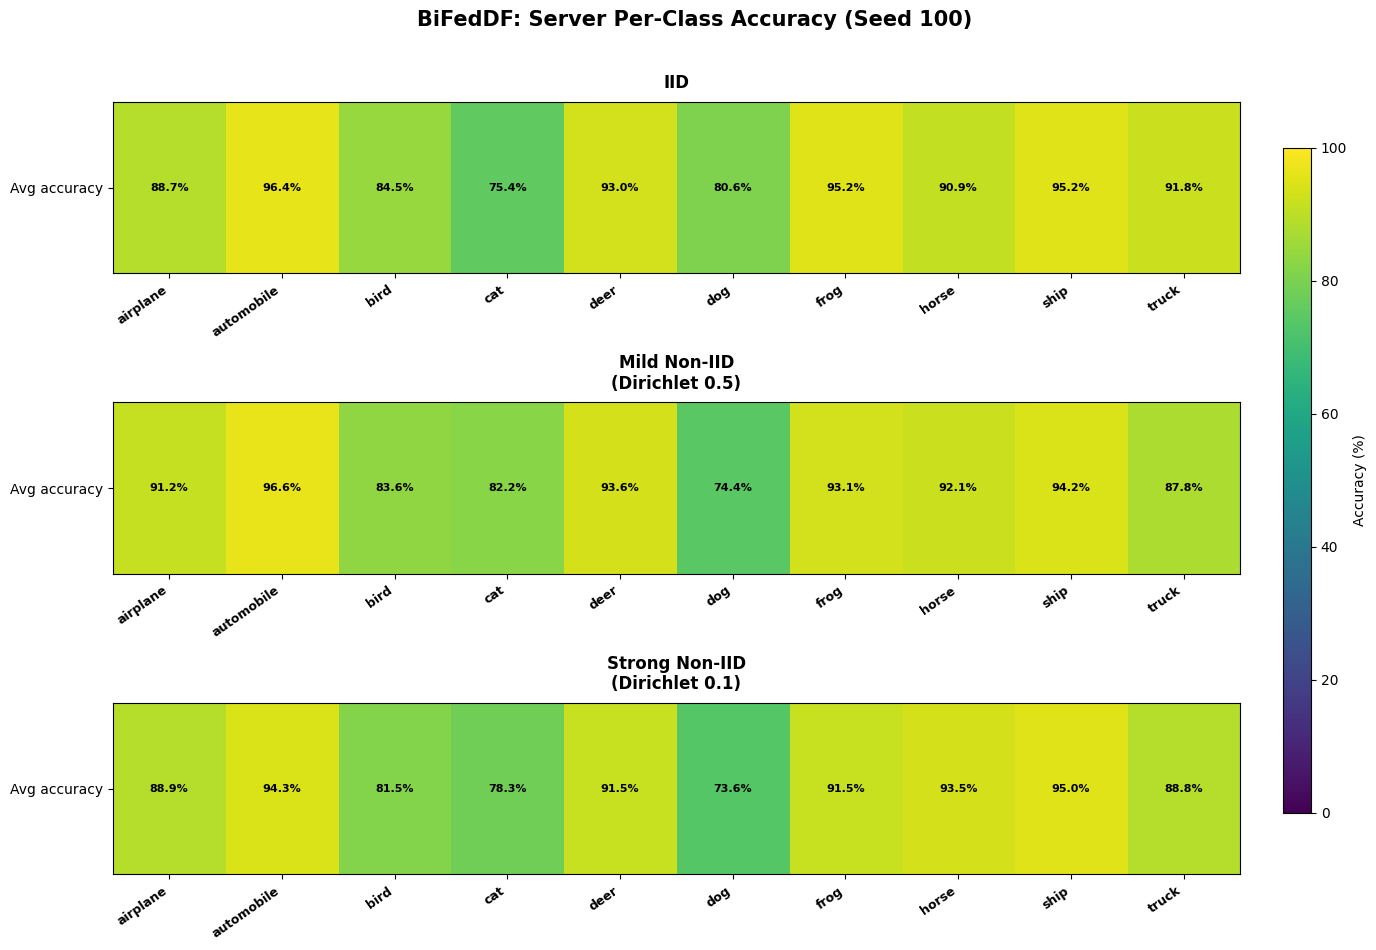

Saved: /mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELOR25072026/bifeddf_seed100_avg_client_per_class_accuracy_group.png


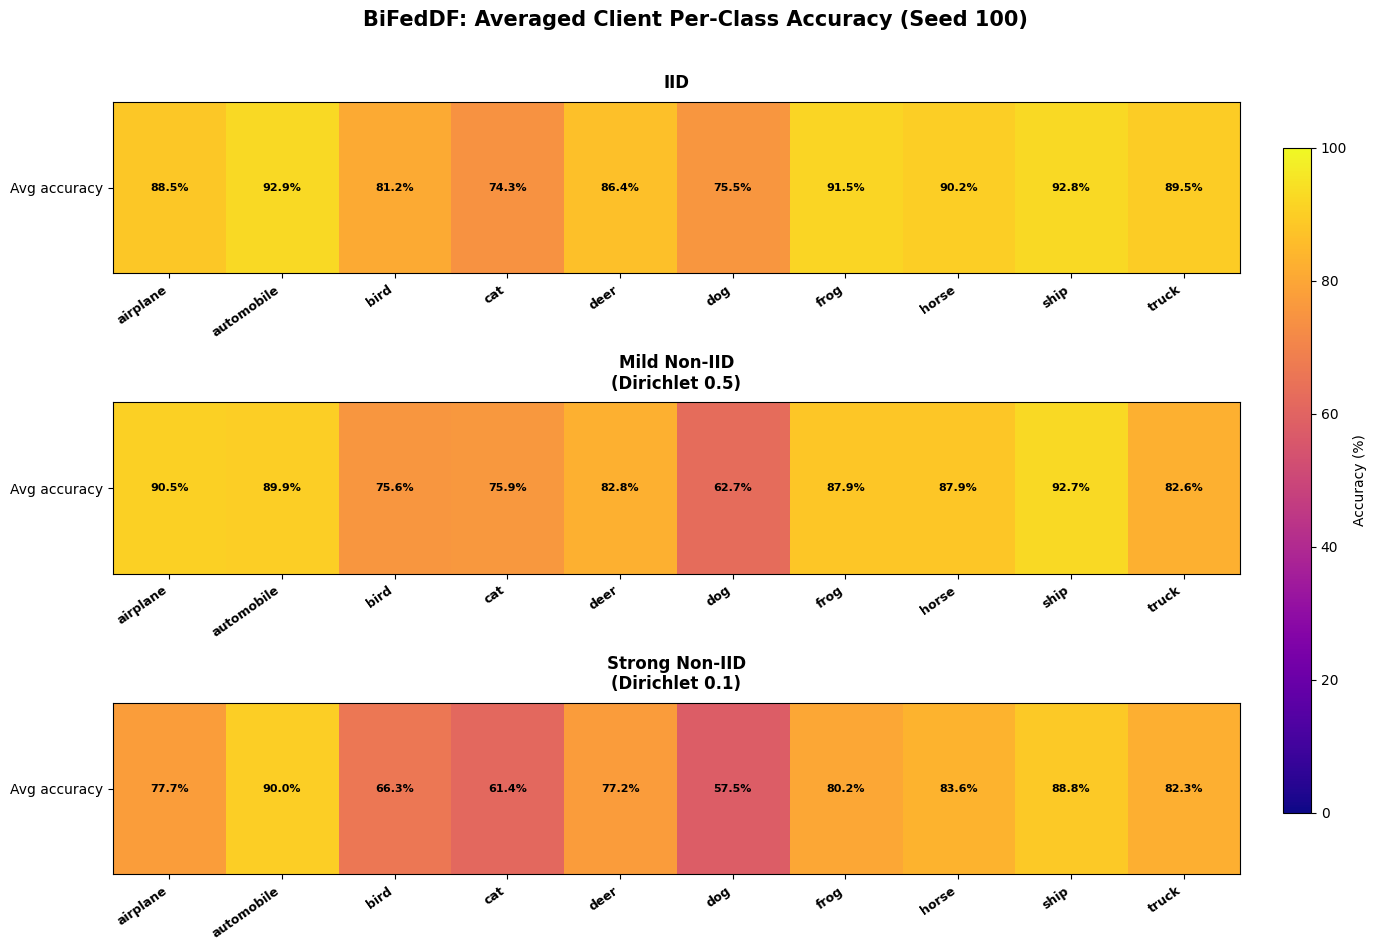

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
from torch.utils.data import DataLoader

# Font configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

target_seed = 100

# Fresh single-worker eval loader to avoid multiprocessing issues
eval_loader = DataLoader(
    eval_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

def compute_per_class_accuracy(model, loader, device=device, n_classes=10):
    model.eval()
    correct = np.zeros(n_classes, dtype=np.int64)
    total = np.zeros(n_classes, dtype=np.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            for t, p in zip(labels.view(-1), preds.view(-1)):
                total[t.item()] += 1
                correct[t.item()] += (t == p).item()

    return 100.0 * correct / np.maximum(total, 1)

def plot_heatmap_group_stacked(title, heatmaps, cmap='viridis', save_name=None):
    fig, axes = plt.subplots(3, 1, figsize=(14, 9.5))
    fig.suptitle(title, fontsize=15, fontweight='bold', y=0.995)

    vmin, vmax = 0, 100
    last_im = None

    for ax, (subplot_title, values) in zip(axes, heatmaps):
        last_im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
        ax.set_title(subplot_title, fontsize=12, fontweight='bold', pad=10)
        ax.set_xticks(np.arange(len(class_names)))
        ax.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9, fontweight='bold')
        ax.set_yticks([0])
        ax.set_yticklabels(['Avg accuracy'], fontsize=10)

        for i, value in enumerate(values):
            text_color = 'white' if value < 50 else 'black'
            ax.text(i, 0, f'{value:.1f}%', ha='center', va='center', color=text_color, fontsize=8, fontweight='bold')

    # Constrain the subplots to leave space for colorbar
    plt.tight_layout(rect=[0, 0, 0.90, 0.98])

    # Position the colorbar neatly on the right
    cax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) 
    fig.colorbar(last_im, cax=cax, label='Accuracy (%)')

    if save_name:
        save_path = os.path.join(SAVE_DIR, save_name)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

def get_seed_100_per_class_accuracy(run_prefix, loader_base, loader):
    # Fetch seed 100 entry
    entry = loaded_runs[run_prefix][loader_base][target_seed]

    server_model = entry["global_model"]
    client_models = entry["client_models"]

    server_acc = compute_per_class_accuracy(server_model, loader, device)
    client_accs = [compute_per_class_accuracy(m, loader, device) for m in client_models]
    avg_client = np.mean(client_accs, axis=0)

    return server_acc, avg_client

feddf_configs = [
    ("IID", "feddf_basic", "iid"),
    ("Mild Non-IID\n(Dirichlet 0.5)", "feddf_basic", "moderatedirichlet"),
    ("Strong Non-IID\n(Dirichlet 0.1)", "feddf_basic", "strongdirichlet"),
]

bifeddf_configs = [
    ("IID", "feddf_bidir", "iid"),
    ("Mild Non-IID\n(Dirichlet 0.5)", "feddf_bidir", "moderatedirichlet"),
    ("Strong Non-IID\n(Dirichlet 0.1)", "feddf_bidir", "strongdirichlet"),
]

# --- 1. Compute for FedDF (Seed 100) ---
feddf_server_heatmaps = []
feddf_client_heatmaps = []
for label, run_prefix, loader_base in feddf_configs:
    s_acc, c_acc = get_seed_100_per_class_accuracy(run_prefix, loader_base, eval_loader)
    feddf_server_heatmaps.append((label, s_acc))
    feddf_client_heatmaps.append((label, c_acc))

# --- 2. Compute for BiFedDF (Seed 100) ---
bifeddf_server_heatmaps = []
bifeddf_client_heatmaps = []
for label, run_prefix, loader_base in bifeddf_configs:
    s_acc, c_acc = get_seed_100_per_class_accuracy(run_prefix, loader_base, eval_loader)
    bifeddf_server_heatmaps.append((label, s_acc))
    bifeddf_client_heatmaps.append((label, c_acc))

# --- Plot 1: FedDF Server ---
plot_heatmap_group_stacked(
    f"FedDF: Server Per-Class Accuracy (Seed {target_seed})",
    feddf_server_heatmaps,
    cmap='viridis',
    save_name=f"feddf_seed{target_seed}_avg_server_per_class_accuracy_group.png"
)

# --- Plot 2: FedDF Clients ---
plot_heatmap_group_stacked(
    f"FedDF: Averaged Client Per-Class Accuracy (Seed {target_seed})",
    feddf_client_heatmaps,
    cmap='plasma',
    save_name=f"feddf_seed{target_seed}_avg_client_per_class_accuracy_group.png"
)

# --- Plot 3: BiFedDF Server ---
plot_heatmap_group_stacked(
    f"BiFedDF: Server Per-Class Accuracy (Seed {target_seed})",
    bifeddf_server_heatmaps,
    cmap='viridis',
    save_name=f"bifeddf_seed{target_seed}_avg_server_per_class_accuracy_group.png"
)

# --- Plot 4: BiFedDF Clients ---
plot_heatmap_group_stacked(
    f"BiFedDF: Averaged Client Per-Class Accuracy (Seed {target_seed})",
    bifeddf_client_heatmaps,
    cmap='plasma',
    save_name=f"bifeddf_seed{target_seed}_avg_client_per_class_accuracy_group.png"
)

In [48]:
import numpy as np
import pandas as pd

seeds = [100, 200, 300, 400, 500]

scenarios = [
    ("FedDF IID", "feddf_basic", "iid"),
    ("FedDF Mild Non-IID (Dirichlet 0.5)", "feddf_basic", "moderatedirichlet"),
    ("FedDF Strong Non-IID (Dirichlet 0.1)", "feddf_basic", "strongdirichlet"),
    ("BiFedDF IID", "feddf_bidir", "iid"),
    ("BiFedDF Mild Non-IID (Dirichlet 0.5)", "feddf_bidir", "moderatedirichlet"),
    ("BiFedDF Strong Non-IID (Dirichlet 0.1)", "feddf_bidir", "strongdirichlet"),
]

def final_server_acc(run_prefix, loader_base, seed):
    return float(loaded_runs[run_prefix][loader_base][seed]["history"][-1])

def final_avg_client_acc(run_prefix, loader_base, seed):
    client_hist = loaded_runs[run_prefix][loader_base][seed]["client_acc_history"]
    client_ids = sorted(client_hist.keys(), key=lambda k: int(k))
    final_client_accs = [float(client_hist[c_id][-1]) for c_id in client_ids]
    return float(np.mean(final_client_accs))

rows = []
for scenario_name, run_prefix, loader_base in scenarios:
    server_vals = []
    client_vals = []

    for seed in seeds:
        server_vals.append(final_server_acc(run_prefix, loader_base, seed))
        client_vals.append(final_avg_client_acc(run_prefix, loader_base, seed))

    rows.append({
        "Scenario": scenario_name,
        "Server Acc Mean (%)": np.mean(server_vals),
        "Server Acc Std (%)": np.std(server_vals, ddof=1),
        "Avg Client Acc Mean (%)": np.mean(client_vals),
        "Avg Client Acc Std (%)": np.std(client_vals, ddof=1),
    })

df = pd.DataFrame(rows)

# nicer display formatting
pd.set_option("display.precision", 2)
print(df.to_string(index=False))

                              Scenario  Server Acc Mean (%)  Server Acc Std (%)  Avg Client Acc Mean (%)  Avg Client Acc Std (%)
                             FedDF IID                90.06                0.18                    85.14                    0.17
    FedDF Mild Non-IID (Dirichlet 0.5)                89.14                0.76                    78.62                    1.04
  FedDF Strong Non-IID (Dirichlet 0.1)                86.83                1.65                    54.81                    5.34
                           BiFedDF IID                89.03                0.29                    86.14                    0.10
  BiFedDF Mild Non-IID (Dirichlet 0.5)                87.44                0.73                    82.42                    0.66
BiFedDF Strong Non-IID (Dirichlet 0.1)                79.74                3.30                    70.76                    2.73


P.S. plotting was done with LLM assistance